# Audit et nettoyage des données — Ecology

## 1. Initialisation

Importation des bibliothèques Python et des fonctions personnalisées du module `eco_utils.py`, utilisées pour l'analyse, le nettoyage et la validation des données.

In [1]:
import sys
import importlib
from pathlib import Path

import pandas as pd

from pandas.api.types import (
    is_numeric_dtype,
    is_datetime64_any_dtype,
    is_string_dtype
)

# Définir la racine du projet
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Ajouter src au chemin des modules Python
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

# Importer le module utilitaire
import eco_utils
importlib.reload(eco_utils)

from eco_utils import (
    normalize_decimal,
    extract_units,
    enleve_unit,
    detect_non_numeric,
    show_missing,
    check_numeric_range,
    detect_outliers,
    extract_datetime_format,
    detect_invalid_dates,
    detect_category_variants,
    normalize_datetime,
    convert_datetime,
    check_date_order,
    normalize_text,
    normalize_categories,
    show_unique_values,
    detect_rare_categories
)

print("Imports réussis.")
print("Module :", eco_utils.__file__)

Imports réussis.
Module : C:\Users\Lenovo\Desktop\Data Mining\20262027-UE-DataMining-Project\src\eco_utils.py


## 2. Chargement du dictionnaire de données

Le fichier `data_dictionary.csv` décrit les variables des datasets, notamment leurs types logiques et leurs rôles.

Il sert de référence pour identifier les colonnes à analyser et vérifier leur conformité pendant le nettoyage.

In [2]:
dictionary_path = PROJECT_ROOT / "data" / "data_dictionary.csv"

dictionary = pd.read_csv(dictionary_path)

print("Dimensions :", dictionary.shape)

print("\nColonnes du dictionnaire :")
print(dictionary.columns.tolist())

print("\nPremières lignes :")
display(dictionary.head())

Dimensions : (355, 8)

Colonnes du dictionnaire :
['source_bundle', 'source_system_id', 'file_name', 'field_name', 'logical_type', 'key_role', 'description', 'example_value']

Premières lignes :


,source_bundle,source_system_id,file_name,field_name,logical_type,key_role,description,example_value
0,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_number,identifier,primary_or_composite_key,Source-local encounter identifier.,ENC-000001
1,SB02,SYS-CLN-OPS,clinical_encounters.csv,patient_number,identifier,non_key,Source-local patient identifier used within th...,PAT-31162
2,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_start,date_or_datetime,non_key,Encounter start.,2018-02-27T09:15:00
3,SB02,SYS-CLN-OPS,clinical_encounters.csv,encounter_end,date_or_datetime,non_key,Encounter end.,2018-02-27T10:45:00
4,SB02,SYS-CLN-OPS,clinical_encounters.csv,facility_license_number,identifier,non_key,Facility license number.,FAC-VLN-101


## 3. Chargement des datasets

Chargement des fichiers CSV du dossier `data/ecology` dans un dictionnaire de DataFrames Pandas.

Les dimensions de chaque dataset sont affichées pour effectuer un premier contrôle de leur structure. Les données originales sont conservées sans modification.

In [3]:
ecology_path = PROJECT_ROOT / "data" / "ecology"

# Chargement des données originales
datasets = {}

for file in sorted(ecology_path.glob("*.csv")):
    datasets[file.name] = pd.read_csv(file, low_memory=False)

    print(
        f"{file.name} : "
        f"{datasets[file.name].shape[0]} lignes, "
        f"{datasets[file.name].shape[1]} colonnes"
    )

print(f"\nTotal : {len(datasets)} datasets chargés.")

# Création de copies indépendantes pour le nettoyage
cleaned_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

print("Copies de travail initialisées.")

bat_surveys.csv : 4994 lignes, 14 colonnes
environmental_field_reports.csv : 30 lignes, 12 colonnes
environmental_monthly.csv : 4994 lignes, 11 colonnes
monitoring_device_operations.csv : 4994 lignes, 11 colonnes
monitoring_sites.csv : 64 lignes, 14 colonnes
orchard_surveys.csv : 1250 lignes, 11 colonnes

Total : 6 datasets chargés.
Copies de travail initialisées.


## 4. Audit et nettoyage des variables numériques

### 4.1. Identification des variables numériques

Sélection des colonnes déclarées `numeric` dans le dictionnaire de données, puis regroupement par dataset.

Cette identification permet d'automatiser les contrôles de types, de formats, de valeurs manquantes et de contraintes numériques.

In [4]:
numeric_dictionary = dictionary[
    (dictionary["file_name"].isin(datasets.keys())) &
    (dictionary["logical_type"] == "numeric")
].copy()

numeric_columns = {
    name: group["field_name"].tolist()
    for name, group in numeric_dictionary.groupby("file_name")
}

for name, columns in numeric_columns.items():
    print(f"\n{name} : {len(columns)} colonnes numériques")
    print(columns)

print(
    "\nTotal :",
    len(numeric_dictionary),
    "variables numériques"
)


bat_surveys.csv : 7 colonnes numériques
['observation_hours', 'observed_bat_count', 'acoustic_detection_count', 'nightly_visit_count', 'colony_estimate', 'comparison_species_count', 'weather_interference']

environmental_monthly.csv : 7 colonnes numériques
['mean_temperature_c', 'rainfall_mm', 'mean_humidity_pct', 'vegetation_cover_pct', 'habitat_disturbance_index', 'pesticide_index', 'data_completeness_pct']

monitoring_device_operations.csv : 1 colonnes numériques
['uptime_pct']

monitoring_sites.csv : 3 colonnes numériques
['latitude', 'longitude', 'elevation_m']

orchard_surveys.csv : 7 colonnes numériques
['orchard_area_ha', 'durian_flower_density', 'fruit_set_rate_pct', 'durian_yield_kg', 'other_pollinator_activity', 'fertilizer_use_index', 'irrigation_level']

Total : 25 variables numériques


### 4.2. Vérification des types numériques

Comparaison des types réels des colonnes avec le type `numeric` attendu dans le dictionnaire.

Les colonnes non conformes sont identifiées pour examiner les formats de valeurs qui empêchent leur reconnaissance comme données numériques.

In [5]:
audit_types = []

for name, columns in numeric_columns.items():
    df = datasets[name]

    for col in columns:
        real_type = str(df[col].dtype)
        is_numeric = is_numeric_dtype(df[col])

        audit_types.append({
            "dataset": name,
            "column": col,
            "expected_type": "numeric",
            "real_type": real_type,
            "is_valid": bool(is_numeric)
        })

audit_types_df = pd.DataFrame(audit_types)

display(audit_types_df)

print("\nRésumé :")
print(audit_types_df["is_valid"].value_counts())

,dataset,column,expected_type,real_type,is_valid
0,bat_surveys.csv,observation_hours,numeric,object,False
1,bat_surveys.csv,observed_bat_count,numeric,object,False
2,bat_surveys.csv,acoustic_detection_count,numeric,object,False
3,bat_surveys.csv,nightly_visit_count,numeric,object,False
4,bat_surveys.csv,colony_estimate,numeric,float64,True
5,bat_surveys.csv,comparison_species_count,numeric,int64,True
6,bat_surveys.csv,weather_interference,numeric,object,False
7,environmental_monthly.csv,mean_temperature_c,numeric,object,False
8,environmental_monthly.csv,rainfall_mm,numeric,object,False
9,environmental_monthly.csv,mean_humidity_pct,numeric,object,False



Résumé :
is_valid
False    13
True     12
Name: count, dtype: int64


#### Résultats de l'audit initial

Sur les 25 variables numériques identifiées :

| Statut | Nombre de colonnes |
|---|---:|
| Type numérique conforme | 12 |
| Type non conforme | 13 |
| **Total** | **25** |

Les 13 colonnes non conformes sont stockées sous forme de chaînes de caractères. Elles nécessitent une analyse des valeurs pour identifier les formats problématiques (virgules décimales, unités, etc.) avant leur conversion en types numériques.

Aucune modification des données n'a encore été effectuée.

### 4.3. Analyse des valeurs non numériques

Examen des 13 colonnes dont le type initial n'est pas numérique afin d'identifier les valeurs empêchant leur conversion.

Cette analyse permet de repérer les séparateurs décimaux, les unités et les formats non reconnus, puis de définir les transformations nécessaires.

In [6]:
invalid_columns = audit_types_df.loc[
    ~audit_types_df["is_valid"],
    ["dataset", "column"]
]

for _, row in invalid_columns.iterrows():
    name = row["dataset"]
    col = row["column"]

    invalid = detect_non_numeric(datasets[name], col)

    print(f"\n{name} — {col}")
    print("Valeurs non numériques :", len(invalid))
    print("Valeurs distinctes :", invalid.nunique())
    print("Exemples :", invalid.unique()[:20].tolist())


bat_surveys.csv — observation_hours
Valeurs non numériques : 30
Valeurs distinctes : 30
Exemples : ['24,3', '37,2', '30,6', '35,0', '34,3', '31,6', '31,2', '32,5', '23,5', '35,7', '28,1', '21,2', '36,8', '30,4', '37,8', '24,0', '27,8', '24,9', '17,3', '32,1']

bat_surveys.csv — observed_bat_count
Valeurs non numériques : 25
Valeurs distinctes : 15
Exemples : ['9 count', '11 count', '16 count', '18 count', '5 count', '10 count', '1 count', '4 count', '19 count', '17 count', '6 count', '30 count', '13 count', '7 count', '20 count']

bat_surveys.csv — acoustic_detection_count
Valeurs non numériques : 25
Valeurs distinctes : 22
Exemples : ['7 count', '52 count', '47 count', '13 count', '18 count', '23 count', '37 count', '14 count', '9 count', '3 count', '28 count', '25 count', '33 count', '21 count', '41 count', '27 count', '12 count', '30 count', '16 count', '22 count']

bat_surveys.csv — nightly_visit_count
Valeurs non numériques : 10
Valeurs distinctes : 8
Exemples : ['7 count', '1 co

### 4.4. Normalisation des séparateurs décimaux

Création de copies des datasets originaux pour effectuer le nettoyage sans modifier les données sources.

Les virgules décimales sont ensuite remplacées par des points dans les colonnes numériques non conformes. Les valeurs modifiées sont comparées à leurs valeurs initiales pour contrôler les transformations.

In [7]:
for _, row in invalid_columns.iterrows():
    name = row["dataset"]
    col = row["column"]

    df = cleaned_datasets[name]
    before = df[col].copy()

    normalize_decimal(df, col)

    mask = before.astype("string").ne(
        df[col].astype("string")
    ).fillna(False)

    if mask.any():
        print(f"\n{name} — {col}")
        print("Valeurs modifiées :", mask.sum())

        display(pd.DataFrame({
            "before": before[mask],
            "after": df.loc[mask, col]
        }).head(5))

print("\nNormalisation des décimales terminée.")


bat_surveys.csv — observation_hours
Valeurs modifiées : 30


,before,after
227,"24,3",24.3
715,"37,2",37.2
785,"30,6",30.6
1083,"35,0",35.0
1143,"34,3",34.3



bat_surveys.csv — weather_interference
Valeurs modifiées : 8


,before,after
1765,"15,0",15.0
2866,"42,4",42.4
2901,"7,7",7.7
3131,"34,1",34.1
3144,"33,9",33.9



environmental_monthly.csv — mean_temperature_c
Valeurs modifiées : 25


,before,after
19,"23,81",23.81
216,"26,34",26.34
375,"29,35",29.35
625,"26,63",26.63
707,"24,65",24.65


... (7 outputs left out)

,before,after
123,"48,4",48.4
124,"49,7",49.7
382,"49,5",49.5
398,"71,2",71.2



orchard_surveys.csv — fertilizer_use_index
Valeurs modifiées : 4


,before,after
199,"50,1",50.1
331,"46,8",46.8
907,"44,4",44.4
1233,"29,8",29.8



Normalisation des décimales terminée.


### 4.5. Identification et vérification des unités

Les unités présentes dans les colonnes numériques sont extraites à l'aide de `extract_units()`.

Une vérification manuelle de leur cohérence avec le nom et la signification des variables a ensuite été réalisée (par exemple, `count` pour `observed_bat_count` et `mm` pour `rainfall_mm`).

Les unités détectées étant cohérentes avec les variables correspondantes, elles peuvent être supprimées tout en conservant les valeurs numériques, sans conversion d'unité.

In [8]:
unit_audit = []

for _, row in invalid_columns.iterrows():
    name = row["dataset"]
    col = row["column"]
    df = cleaned_datasets[name]

    units = extract_units(df, col)

    for unit, count in units.dropna().value_counts().items():
        unit_audit.append({
            "dataset": name,
            "column": col,
            "unit": unit,
            "count": count,
            "examples": df.loc[units == unit, col].head(5).tolist()
        })

unit_audit_df = pd.DataFrame(
    unit_audit,
    columns=["dataset", "column", "unit", "count", "examples"]
)

display(unit_audit_df)

print("Total de valeurs avec unités :", unit_audit_df["count"].sum())

,dataset,column,unit,count,examples
0,bat_surveys.csv,observed_bat_count,count,25,"[9 count, 11 count, 16 count, 18 count, 5 count]"
1,bat_surveys.csv,acoustic_detection_count,count,25,"[7 count, 52 count, 47 count, 13 count, 18 count]"
2,bat_surveys.csv,nightly_visit_count,count,10,"[7 count, 1 count, 5 count, 14 count, 9 count]"
3,environmental_monthly.csv,mean_temperature_c,C,15,"[25.86 C, 23.3 C, 23.73 C, 24.47 C, 22.95 C]"
4,environmental_monthly.csv,rainfall_mm,mm,25,"[102.7 mm, 251.3 mm, 67.9 mm, 29.5 mm, 91.9 mm]"
5,orchard_surveys.csv,orchard_area_ha,ha,5,"[59.7 ha, 54.7 ha, 6.0 ha, 31.3 ha, 44.2 ha]"
6,orchard_surveys.csv,durian_yield_kg,kg,5,"[63290.0 kg, 69487.6 kg, 116624.0 kg, 7641.7 k..."


Total de valeurs avec unités : 110


### 4.6. Suppression des unités

Les unités identifiées et vérifiées précédemment sont supprimées à l'aide de `enleve_unit()` afin de conserver uniquement les valeurs numériques.

Les transformations sont contrôlées en comparant les valeurs avant et après nettoyage. Les valeurs sans unité correspondante restent inchangées.

In [9]:
for _, row in unit_audit_df.iterrows():
    name = row["dataset"]
    col = row["column"]
    unit = row["unit"]

    df = cleaned_datasets[name]
    before = df[col].copy()

    enleve_unit(df, col, unit)

    mask = before.astype("string").ne(
        df[col].astype("string")
    ).fillna(False)

    print(f"\n{name} — {col} ({unit})")
    print("Valeurs modifiées :", mask.sum())

    if mask.any():
        display(pd.DataFrame({
            "before": before[mask],
            "after": df.loc[mask, col]
        }).head(10))


bat_surveys.csv — observed_bat_count (count)
Valeurs modifiées : 25


,before,after
19,9 count,9
271,11 count,11
523,16 count,16
543,18 count,18
1270,5 count,5
1335,10 count,10
1530,1 count,1
1538,4 count,4
1673,10 count,10
1695,19 count,19



bat_surveys.csv — acoustic_detection_count (count)
Valeurs modifiées : 25


,before,after
242,7 count,7
261,52 count,52
318,47 count,47
532,13 count,13
682,18 count,18
934,23 count,23
1093,37 count,37
1245,14 count,14
1276,9 count,9
1559,3 count,3



bat_surveys.csv — nightly_visit_count (count)
Valeurs modifiées : 10


,before,after
143,7 count,7
771,1 count,1
780,5 count,5
956,14 count,14
1050,9 count,9
2224,8 count,8
2769,16 count,16
3429,4 count,4
4326,8 count,8
4783,8 count,8


... (4 outputs left out)


orchard_surveys.csv — orchard_area_ha (ha)
Valeurs modifiées : 5


,before,after
226,59.7 ha,59.7
301,54.7 ha,54.7
702,6.0 ha,6.0
891,31.3 ha,31.3
1214,44.2 ha,44.2



orchard_surveys.csv — durian_yield_kg (kg)
Valeurs modifiées : 5


,before,after
490,63290.0 kg,63290.0
515,69487.6 kg,69487.6
654,116624.0 kg,116624.0
764,7641.7 kg,7641.7
949,37441.2 kg,37441.2


### 4.7. Vérification des valeurs non numériques restantes

Après la normalisation des décimales et la suppression des unités, un dernier contrôle est effectué pour identifier les valeurs encore non convertibles.

Cette vérification permet de confirmer que les colonnes sont prêtes pour leur conversion définitive en types numériques.

In [10]:
audit_remaining = []

for _, row in invalid_columns.iterrows():
    name = row["dataset"]
    col = row["column"]

    remaining = detect_non_numeric(cleaned_datasets[name], col)

    audit_remaining.append({
        "dataset": name,
        "column": col,
        "non_numeric_remaining": len(remaining),
        "examples": remaining.unique()[:5].tolist()
    })

audit_remaining_df = pd.DataFrame(audit_remaining)

display(audit_remaining_df)

print(
    "\nTotal de valeurs non numériques restantes :",
    audit_remaining_df["non_numeric_remaining"].sum()
)

,dataset,column,non_numeric_remaining,examples
0,bat_surveys.csv,observation_hours,0,[]
1,bat_surveys.csv,observed_bat_count,0,[]
2,bat_surveys.csv,acoustic_detection_count,0,[]
3,bat_surveys.csv,nightly_visit_count,0,[]
4,bat_surveys.csv,weather_interference,0,[]
5,environmental_monthly.csv,mean_temperature_c,0,[]
6,environmental_monthly.csv,rainfall_mm,0,[]
7,environmental_monthly.csv,mean_humidity_pct,0,[]
8,monitoring_device_operations.csv,uptime_pct,0,[]
9,orchard_surveys.csv,orchard_area_ha,0,[]



Total de valeurs non numériques restantes : 0


### 4.8. Conversion des colonnes en types numériques

Après normalisation des séparateurs décimaux et suppression des unités validées, les colonnes initialement non conformes sont converties en types numériques.

La conversion utilise `errors="raise"` afin de signaler toute valeur non convertible sans introduire automatiquement de nouvelles valeurs manquantes.

Les types obtenus sont ensuite vérifiés avec `is_numeric_dtype()`.

In [11]:
conversion_results = []

for _, row in invalid_columns.iterrows():
    name = row["dataset"]
    col = row["column"]
    df = cleaned_datasets[name]

    before_type = str(df[col].dtype)

    # Convertir uniquement si nécessaire
    if not is_numeric_dtype(df[col]):
        df[col] = pd.to_numeric(df[col], errors="raise")

    conversion_results.append({
        "dataset": name,
        "column": col,
        "before": before_type,
        "after": str(df[col].dtype),
        "is_valid": bool(is_numeric_dtype(df[col]))
    })

conversion_results_df = pd.DataFrame(conversion_results)

display(conversion_results_df)

print("\nRésumé :")
print(conversion_results_df["is_valid"].value_counts())

,dataset,column,before,after,is_valid
0,bat_surveys.csv,observation_hours,object,float64,True
1,bat_surveys.csv,observed_bat_count,object,int64,True
2,bat_surveys.csv,acoustic_detection_count,object,int64,True
3,bat_surveys.csv,nightly_visit_count,object,int64,True
4,bat_surveys.csv,weather_interference,object,float64,True
5,environmental_monthly.csv,mean_temperature_c,object,float64,True
6,environmental_monthly.csv,rainfall_mm,object,float64,True
7,environmental_monthly.csv,mean_humidity_pct,object,float64,True
8,monitoring_device_operations.csv,uptime_pct,object,float64,True
9,orchard_surveys.csv,orchard_area_ha,object,float64,True



Résumé :
is_valid
True    13
Name: count, dtype: int64


### 4.9. Validation des types numériques

Vérification finale des types des 25 variables déclarées numériques dans le dictionnaire de données.

Cette validation permet de confirmer que les colonnes initialement non conformes ont été correctement converties et que toutes les variables numériques possèdent désormais un type adapté.

In [12]:
validation_results = []

for name, columns in numeric_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        validation_results.append({
            "dataset": name,
            "column": col,
            "real_type": str(df[col].dtype),
            "is_valid": bool(is_numeric_dtype(df[col]))
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print(
    "\nTypes conformes :",
    validation_df["is_valid"].sum(),
    "/",
    len(validation_df)
)

print("\nColonnes non conformes :")
display(validation_df[~validation_df["is_valid"]])

,dataset,column,real_type,is_valid
0,bat_surveys.csv,observation_hours,float64,True
1,bat_surveys.csv,observed_bat_count,int64,True
2,bat_surveys.csv,acoustic_detection_count,int64,True
3,bat_surveys.csv,nightly_visit_count,int64,True
4,bat_surveys.csv,colony_estimate,float64,True
5,bat_surveys.csv,comparison_species_count,int64,True
6,bat_surveys.csv,weather_interference,float64,True
7,environmental_monthly.csv,mean_temperature_c,float64,True
8,environmental_monthly.csv,rainfall_mm,float64,True
9,environmental_monthly.csv,mean_humidity_pct,float64,True



Types conformes : 25 / 25

Colonnes non conformes :


,dataset,column,real_type,is_valid


### 4.10. Analyse des valeurs manquantes

Identification et quantification des valeurs manquantes dans les 25 colonnes numériques à l'aide de `show_missing()`.

Les valeurs manquantes sont conservées afin d'éviter toute imputation sans justification métier.

In [13]:
missing_results = []

for name, columns in numeric_columns.items():
    missing = show_missing(cleaned_datasets[name][columns])

    for col, row in missing.iterrows():
        missing_results.append({
            "dataset": name,
            "column": col,
            "missing_count": int(row["missing_count"]),
            "missing_percent": row["missing_percent"]
        })

missing_df = pd.DataFrame(missing_results)

display(missing_df)

print(
    "Total de valeurs manquantes :",
    missing_df["missing_count"].sum()
)

,dataset,column,missing_count,missing_percent
0,environmental_monthly.csv,pesticide_index,15,0.30
1,environmental_monthly.csv,vegetation_cover_pct,10,0.20
2,monitoring_sites.csv,elevation_m,1,1.56


Total de valeurs manquantes : 26


### 4.11. Statistiques descriptives

Calcul des statistiques descriptives des variables numériques : minimum, maximum, moyenne, médiane et écart-type.

Cette analyse permet d'examiner les distributions, d'évaluer la dispersion des valeurs et de repérer d'éventuelles anomalies avant les contrôles de cohérence.

In [14]:
numeric_stats = []

for name, columns in numeric_columns.items():
    stats = cleaned_datasets[name][columns].agg(
        ["min", "max", "mean", "median", "std"]
    ).T

    stats["dataset"] = name
    stats["column"] = stats.index

    numeric_stats.append(stats.reset_index(drop=True))

numeric_stats_df = pd.concat(numeric_stats, ignore_index=True)

display(numeric_stats_df.round(2))

,min,max,mean,median,std,dataset,column
0,5.00,46.90,30.33,30.60,5.50,bat_surveys.csv,observation_hours
1,0.00,73.00,14.13,13.00,8.25,bat_surveys.csv,observed_bat_count
2,0.00,107.00,20.48,18.00,12.13,bat_surveys.csv,acoustic_detection_count
3,0.00,54.00,10.11,9.00,6.06,bat_surveys.csv,nightly_visit_count
4,0.00,99.60,15.83,14.20,9.60,bat_surveys.csv,colony_estimate
5,1.00,26.00,10.71,11.00,3.45,bat_surveys.csv,comparison_species_count
6,0.00,100.00,37.48,36.70,16.66,bat_surveys.csv,weather_interference
7,21.30,32.00,26.38,26.35,1.67,environmental_monthly.csv,mean_temperature_c
8,5.00,384.30,159.92,156.30,74.90,environmental_monthly.csv,rainfall_mm
9,56.70,96.40,75.84,75.90,7.25,environmental_monthly.csv,mean_humidity_pct


### 4.12. Vérification des contraintes numériques

Définition des intervalles de valeurs autorisés à partir de la signification des variables (comptages positifs, pourcentages entre 0 et 100, coordonnées géographiques, etc.).

Chaque colonne est contrôlée à l'aide de `check_numeric_range()` afin d'identifier les valeurs situées en dehors des limites définies.

In [15]:
numeric_ranges = {
    "observation_hours": (0, None),
    "observed_bat_count": (0, None),
    "acoustic_detection_count": (0, None),
    "nightly_visit_count": (0, None),
    "colony_estimate": (0, None),
    "comparison_species_count": (0, None),
    "weather_interference": (0, 100),
    "mean_temperature_c": (None, None),
    "rainfall_mm": (0, None),
    "mean_humidity_pct": (0, 100),
    "vegetation_cover_pct": (0, 100),
    "habitat_disturbance_index": (0, None),
    "pesticide_index": (0, None),
    "data_completeness_pct": (0, 100),
    "uptime_pct": (0, 100),
    "latitude": (-90, 90),
    "longitude": (-180, 180),
    "elevation_m": (None, None),
    "orchard_area_ha": (0, None),
    "durian_flower_density": (0, None),
    "fruit_set_rate_pct": (0, 100),
    "durian_yield_kg": (0, None),
    "other_pollinator_activity": (0, None),
    "fertilizer_use_index": (0, None),
    "irrigation_level": (0, None)
}

range_results = []

for name, columns in numeric_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        min_val, max_val = numeric_ranges[col]

        invalid = check_numeric_range(
            df,
            col,
            min_value=min_val,
            max_value=max_val
        )

        range_results.append({
            "dataset": name,
            "column": col,
            "min_allowed": min_val,
            "max_allowed": max_val,
            "invalid_count": len(invalid),
            "is_valid": len(invalid) == 0
        })

range_audit_df = pd.DataFrame(range_results)

display(range_audit_df)

print(
    "Colonnes conformes :",
    range_audit_df["is_valid"].sum(),
    "/",
    len(range_audit_df)
)

print(
    "Valeurs hors limites :",
    range_audit_df["invalid_count"].sum()
)

,dataset,column,min_allowed,max_allowed,invalid_count,is_valid
0,bat_surveys.csv,observation_hours,0.0,NaN,0,True
1,bat_surveys.csv,observed_bat_count,0.0,NaN,0,True
2,bat_surveys.csv,acoustic_detection_count,0.0,NaN,0,True
3,bat_surveys.csv,nightly_visit_count,0.0,NaN,0,True
4,bat_surveys.csv,colony_estimate,0.0,NaN,0,True
5,bat_surveys.csv,comparison_species_count,0.0,NaN,0,True
6,bat_surveys.csv,weather_interference,0.0,100.0,0,True
7,environmental_monthly.csv,mean_temperature_c,NaN,NaN,0,True
8,environmental_monthly.csv,rainfall_mm,0.0,NaN,0,True
9,environmental_monthly.csv,mean_humidity_pct,0.0,100.0,0,True


Colonnes conformes : 25 / 25
Valeurs hors limites : 0


### 4.13. Détection des valeurs atypiques — Méthode IQR

Les valeurs atypiques des variables numériques sont identifiées à l'aide de la méthode de l'écart interquartile (IQR), avec des bornes définies par `Q1 − 1,5 × IQR` et `Q3 + 1,5 × IQR`.

Pour chaque variable, les quartiles, les bornes et le nombre d'observations atypiques sont calculés.

Les outliers sont examinés mais ne sont pas supprimés automatiquement, car ils peuvent représenter des observations écologiques réelles.

In [16]:
outlier_results = []

for name, columns in numeric_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        outliers = detect_outliers(df, col)

        outlier_results.append({
            "dataset": name,
            "column": col,
            "Q1": round(q1, 2),
            "median": round(df[col].median(), 2),
            "Q3": round(q3, 2),
            "lower_bound": round(q1 - 1.5 * iqr, 2),
            "upper_bound": round(q3 + 1.5 * iqr, 2),
            "outlier_count": len(outliers),
            "outlier_percent": round(
                len(outliers) / len(df) * 100, 2
            ),
            "examples": outliers[col].head(5).tolist()
        })

outliers_df = pd.DataFrame(outlier_results)

display(outliers_df)

print(
    "Total d'occurrences atypiques :",
    outliers_df["outlier_count"].sum()
)

,dataset,column,Q1,median,Q3,lower_bound,upper_bound,outlier_count,outlier_percent,examples
0,bat_surveys.csv,observation_hours,26.90,30.60,34.10,16.10,44.90,67,1.34,"[12.2, 12.5, 16.0, 15.3, 14.0]"
1,bat_surveys.csv,observed_bat_count,8.00,13.00,18.00,-7.00,33.00,128,2.56,"[38, 40, 36, 41, 36]"
2,bat_surveys.csv,acoustic_detection_count,12.00,18.00,26.00,-9.00,47.00,160,3.20,"[52, 52, 52, 52, 60]"
3,bat_surveys.csv,nightly_visit_count,6.00,9.00,13.00,-4.50,23.50,158,3.16,"[27, 35, 25, 24, 26]"
4,bat_surveys.csv,colony_estimate,9.30,14.20,20.50,-7.50,37.30,155,3.10,"[50.3, 50.0, 46.2, 43.8, 38.3]"
5,bat_surveys.csv,comparison_species_count,8.00,11.00,13.00,0.50,20.50,29,0.58,"[21, 22, 21, 21, 21]"
6,bat_surveys.csv,weather_interference,25.10,36.70,49.00,-10.75,84.85,32,0.64,"[90.5, 84.9, 93.3, 89.0, 87.6]"
7,environmental_monthly.csv,mean_temperature_c,25.19,26.35,27.61,21.56,31.24,9,0.18,"[21.32, 21.52, 21.54, 21.3, 31.31]"
8,environmental_monthly.csv,rainfall_mm,95.72,156.30,221.70,-93.24,410.66,0,0.00,[]
9,environmental_monthly.csv,mean_humidity_pct,70.30,75.90,81.50,53.50,98.30,0,0.00,[]


Total d'occurrences atypiques : 1053


### 4.14. Investigation des incohérences d'échelle — `fruit_set_rate_pct`

L'analyse des outliers a révélé des valeurs particulièrement faibles dans `fruit_set_rate_pct`.

Les observations comprises entre 0 et 1 sont isolées et comparées à la distribution générale afin d'examiner l'hypothèse d'une confusion entre proportions et pourcentages.

Cette étape est exploratoire : aucune correction n'est encore appliquée.

In [17]:
df = cleaned_datasets["orchard_surveys.csv"]
col = "fruit_set_rate_pct"

mask = df[col].between(0, 1, inclusive="both")

suspect_values = df.loc[
    mask, ["orchard_survey_id", col]
].copy()

print("Valeurs suspectes :", len(suspect_values))
display(suspect_values)

print("\nMédiane globale :", df[col].median())
print(
    "Médiane des valeurs > 1 :",
    df.loc[df[col] > 1, col].median()
)

Valeurs suspectes : 8


,orchard_survey_id,fruit_set_rate_pct
269,ORC-0000270,0.568
412,ORC-0000413,0.543
454,ORC-0000455,0.549
716,ORC-0000717,0.561
718,ORC-0000719,0.595
919,ORC-0000920,0.467
1060,ORC-0001061,0.581
1180,ORC-0001181,0.555



Médiane globale : 52.8
Médiane des valeurs > 1 : 52.9


### 4.15. Correction présumée de l'échelle — `fruit_set_rate_pct`

L'analyse IQR a identifié 18 valeurs atypiques, dont 8 observations comprises entre 0 et 1, alors que la majorité des taux sont exprimés sur une échelle de 0 à 100.

**Hypothèse :** ces 8 valeurs pourraient avoir été enregistrées sous forme de proportions plutôt que de pourcentages (par exemple, `0.543` au lieu de `54.3`).

**Règle appliquée :** multiplier par 100 uniquement les valeurs strictement comprises entre 0 et 1, sans modifier les autres observations.

Cette transformation est provisoire. Elle sera réexaminée
dans l’audit approfondi des vergers avant l’export final.
Les valeurs originales seront restaurées si la correction
n’est pas suffisamment justifiée.

In [18]:
name = "orchard_surveys.csv"
col = "fruit_set_rate_pct"

df = cleaned_datasets[name]
original = datasets[name]

# Identifier les observations à partir des données originales
mask = original[col].between(0, 1, inclusive="neither")

# Conserver les valeurs avant correction
before = df.loc[mask, col].copy()

# Calculer les valeurs corrigées depuis les données originales
corrected = original.loc[mask, col] * 100

# Appliquer la correction
df.loc[mask, col] = corrected

# Comparaison
comparison = pd.DataFrame({
    "before": before,
    "after": df.loc[mask, col]
})

print("Observations concernées :", len(comparison))
print(
    "Valeurs effectivement modifiées :",
    before.ne(df.loc[mask, col]).sum()
)

display(comparison)

Observations concernées : 8
Valeurs effectivement modifiées : 8


,before,after
269,0.568,56.8
412,0.543,54.3
454,0.549,54.9
716,0.561,56.1
718,0.595,59.5
919,0.467,46.7
1060,0.581,58.1
1180,0.555,55.5


### 4.16. Évaluation de la correction d'échelle

Comparaison des statistiques descriptives et du nombre d'outliers IQR avant et après la correction de `fruit_set_rate_pct`.

Cette analyse permet d'évaluer l'effet de la transformation sur la distribution, sans considérer automatiquement les valeurs atypiques restantes comme des erreurs.

In [19]:
name = "orchard_surveys.csv"
col = "fruit_set_rate_pct"

comparison_results = []

for status, df in [
    ("Avant", datasets[name]),
    ("Après", cleaned_datasets[name])
]:
    comparison_results.append({
        "status": status,
        "Q1": df[col].quantile(0.25),
        "median": df[col].median(),
        "Q3": df[col].quantile(0.75),
        "outlier_count": len(detect_outliers(df, col))
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(2))

,status,Q1,median,Q3,outlier_count
0,Avant,46.9,52.8,59.4,18
1,Après,47.0,53.0,59.4,11


**Résultat :** le nombre d'outliers IQR de `fruit_set_rate_pct` passe de 18 à 11 après la correction présumée des huit observations.

Cette diminution rend l'hypothèse d'une confusion entre proportions et pourcentages plausible, sans la confirmer définitivement. Les 11 outliers restants sont conservés.

### 4.17. Validation finale des variables numériques

Après les transformations, un audit final est réalisé sur les 25 colonnes numériques.

Il regroupe les contrôles de types, de valeurs non numériques, de valeurs manquantes, de contraintes et d'outliers afin de vérifier la qualité des données après nettoyage.

In [20]:
final_audit = []

for name, columns in numeric_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        min_val, max_val = numeric_ranges[col]

        final_audit.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "type_valid": bool(is_numeric_dtype(df[col])),
            "non_numeric": len(detect_non_numeric(df, col)),
            "missing": int(df[col].isna().sum()),
            "invalid_range": len(check_numeric_range(
                df, col,
                min_value=min_val,
                max_value=max_val
            )),
            "outliers": len(detect_outliers(df, col))
        })

final_audit_df = pd.DataFrame(final_audit)

display(final_audit_df)

print("\n=== BILAN NUMÉRIQUE ===")
print("Colonnes analysées :", len(final_audit_df))
print("Types conformes :", final_audit_df["type_valid"].sum())
print("Valeurs non numériques :", final_audit_df["non_numeric"].sum())
print("Valeurs manquantes :", final_audit_df["missing"].sum())
print("Valeurs hors contraintes :", final_audit_df["invalid_range"].sum())
print("Outliers IQR conservés :", final_audit_df["outliers"].sum())

,dataset,column,dtype,type_valid,non_numeric,missing,invalid_range,outliers
0,bat_surveys.csv,observation_hours,float64,True,0,0,0,67
1,bat_surveys.csv,observed_bat_count,int64,True,0,0,0,128
2,bat_surveys.csv,acoustic_detection_count,int64,True,0,0,0,160
3,bat_surveys.csv,nightly_visit_count,int64,True,0,0,0,158
4,bat_surveys.csv,colony_estimate,float64,True,0,0,0,155
5,bat_surveys.csv,comparison_species_count,int64,True,0,0,0,29
6,bat_surveys.csv,weather_interference,float64,True,0,0,0,32
7,environmental_monthly.csv,mean_temperature_c,float64,True,0,0,0,9
8,environmental_monthly.csv,rainfall_mm,float64,True,0,0,0,0
9,environmental_monthly.csv,mean_humidity_pct,float64,True,0,0,0,0



=== BILAN NUMÉRIQUE ===
Colonnes analysées : 25
Types conformes : 25
Valeurs non numériques : 0
Valeurs manquantes : 26
Valeurs hors contraintes : 0
Outliers IQR conservés : 1046


## Bilan — Nettoyage des variables numériques

### Résultats finaux

| Indicateur | Résultat |
|---|---:|
| Variables numériques analysées | 25 |
| Types conformes | 25/25 |
| Valeurs non numériques restantes | 0 |
| Valeurs hors contraintes définies | 0 |
| Valeurs manquantes conservées | 26 |
| Occurrences atypiques IQR conservées | 1 046 |

### Décisions de nettoyage

- **Valeurs manquantes :** les 26 valeurs absentes ont été conservées sans imputation.
- **Outliers :** les 1 046 occurrences atypiques ont été conservées, car leur caractère statistiquement inhabituel ne constitue pas une preuve d'erreur.
- **Incohérence d'échelle :** 8 valeurs de `fruit_set_rate_pct` ont été multipliées par 100 sous l'hypothèse d'une confusion entre proportions et pourcentages. Cette correction reste à confirmer par la documentation métier.

### Conclusion

Les 25 variables numériques sont conformes aux types attendus. Aucune valeur non convertible ni violation des contraintes définies ne subsiste.

Les transformations réalisées ont permis d'harmoniser les formats numériques tout en conservant les valeurs manquantes et les observations atypiques.

## 5. Audit et nettoyage des variables temporelles

### 5.1. Identification des variables temporelles

Sélection des colonnes déclarées `date_or_datetime` dans le dictionnaire de données, puis regroupement par dataset.

Cette identification permet de préparer les contrôles des types, des formats et de la cohérence chronologique des dates.

In [21]:
date_dictionary = dictionary[
    (dictionary["file_name"].isin(datasets.keys())) &
    (dictionary["logical_type"] == "date_or_datetime")
].copy()

date_columns = {
    name: group["field_name"].tolist()
    for name, group in date_dictionary.groupby("file_name")
}

for name, columns in date_columns.items():
    print(f"\n{name} : {len(columns)} colonnes")
    print(columns)

print(
    "\nTotal de variables temporelles :",
    len(date_dictionary)
)


bat_surveys.csv : 2 colonnes
['survey_start', 'survey_end']

environmental_field_reports.csv : 2 colonnes
['document_date', 'reporting_period']

monitoring_device_operations.csv : 2 colonnes
['operation_start', 'operation_end']

monitoring_sites.csv : 2 colonnes
['programme_start_date', 'programme_end_date']

orchard_surveys.csv : 1 colonnes
['survey_period']

Total de variables temporelles : 9


### 5.2. Vérification des types temporels

Comparaison des types réels des colonnes avec le type `date_or_datetime` attendu dans le dictionnaire.

Les colonnes non conformes sont identifiées afin d'analyser leurs formats avant leur conversion en types `datetime`.

In [22]:
date_audit = []

for name, columns in date_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        date_audit.append({
            "dataset": name,
            "column": col,
            "real_type": str(df[col].dtype),
            "is_valid": bool(is_datetime64_any_dtype(df[col]))
        })

date_audit_df = pd.DataFrame(date_audit)

display(date_audit_df)

print(
    "Types conformes :",
    date_audit_df["is_valid"].sum(),
    "/",
    len(date_audit_df)
)

,dataset,column,real_type,is_valid
0,bat_surveys.csv,survey_start,object,False
1,bat_surveys.csv,survey_end,object,False
2,environmental_field_reports.csv,document_date,object,False
3,environmental_field_reports.csv,reporting_period,object,False
4,monitoring_device_operations.csv,operation_start,object,False
5,monitoring_device_operations.csv,operation_end,object,False
6,monitoring_sites.csv,programme_start_date,object,False
7,monitoring_sites.csv,programme_end_date,float64,False
8,orchard_surveys.csv,survey_period,object,False


Types conformes : 0 / 9


### 5.3. Identification des formats temporels

Analyse des colonnes temporelles initialement non conformes afin d'identifier leur format de date, leurs valeurs manquantes et quelques exemples.

Les formats détectés serviront de référence pour vérifier leur homogénéité et préparer la conversion en types `datetime`.

In [23]:
invalid_date_columns = date_audit_df.loc[
    ~date_audit_df["is_valid"],
    ["dataset", "column"]
].copy()

date_formats = []

for _, row in invalid_date_columns.iterrows():
    name = row["dataset"]
    col = row["column"]

    # Utiliser les données originales pour l'audit initial
    df = datasets[name]

    date_formats.append({
        "dataset": name,
        "column": col,
        "detected_format": extract_datetime_format(df, col),
        "missing_count": int(df[col].isna().sum()),
        "examples": df[col].dropna().unique()[:5].tolist()
    })

date_formats_df = pd.DataFrame(date_formats)

display(date_formats_df)

,dataset,column,detected_format,missing_count,examples
0,bat_surveys.csv,survey_start,%Y-%m-%dT%H:%M:%S,0,"[2019-01-05T18:00:00, 2019-02-05T18:00:00, 201..."
1,bat_surveys.csv,survey_end,%Y-%m-%dT%H:%M:%S,0,"[2019-01-12T00:00:00, 2019-02-12T00:00:00, 201..."
2,environmental_field_reports.csv,document_date,%Y-%m-%d,0,"[2024-04-02, 2019-04-01, 2022-09-08, 2025-02-1..."
3,environmental_field_reports.csv,reporting_period,None,0,"[2024-04, 2019-04, 2022-09, 2025-02, 2020-07]"
4,monitoring_device_operations.csv,operation_start,%Y-%m-%dT%H:%M:%S,0,"[2019-01-01T00:00:00, 2019-02-01T00:00:00, 201..."
5,monitoring_device_operations.csv,operation_end,%Y-%m-%dT%H:%M:%S,0,"[2019-01-31T23:59:59, 2019-02-28T23:59:59, 201..."
6,monitoring_sites.csv,programme_start_date,%Y-%m-%d,0,"[2016-01-01, 2018-01-01, 2017-01-01]"
7,monitoring_sites.csv,programme_end_date,None,64,[]
8,orchard_surveys.csv,survey_period,%Y-%m-%d,0,"[2019-01-01, 2019-02-01, 2019-03-01, 2019-04-0..."


### 5.4. Vérification de la validité des dates

Recherche des valeurs temporelles invalides avant conversion.

Les périodes mensuelles au format `YYYY-MM` sont contrôlées séparément. Les colonnes entièrement manquantes sont distinguées des colonnes contenant des dates invalides.

Ce contrôle permet d'identifier les éventuelles anomalies nécessitant une investigation.

In [24]:
invalid_dates_results = []

for _, row in invalid_date_columns.iterrows():
    name = row["dataset"]
    col = row["column"]

    # Audit sur les données originales
    df = datasets[name]

    if df[col].isna().all():
        invalid = df[col].dropna()

    elif col == "reporting_period":
        parsed = pd.to_datetime(
            df[col],
            format="%Y-%m",
            errors="coerce"
        )

        invalid = df.loc[
            df[col].notna() & parsed.isna(), col
        ]

    else:
        invalid = detect_invalid_dates(df, col)

    invalid_dates_results.append({
        "dataset": name,
        "column": col,
        "invalid_count": len(invalid),
        "examples": invalid.unique()[:5].tolist()
    })

invalid_dates_df = pd.DataFrame(invalid_dates_results)

display(invalid_dates_df)

print(
    "Total de dates invalides :",
    invalid_dates_df["invalid_count"].sum()
)

,dataset,column,invalid_count,examples
0,bat_surveys.csv,survey_start,0,[]
1,bat_surveys.csv,survey_end,0,[]
2,environmental_field_reports.csv,document_date,0,[]
3,environmental_field_reports.csv,reporting_period,0,[]
4,monitoring_device_operations.csv,operation_start,0,[]
5,monitoring_device_operations.csv,operation_end,0,[]
6,monitoring_sites.csv,programme_start_date,0,[]
7,monitoring_sites.csv,programme_end_date,0,[]
8,orchard_surveys.csv,survey_period,0,[]


Total de dates invalides : 0


### 5.5. Vérification de l'homogénéité des formats temporels

Comparaison des valeurs de chaque colonne avec son format de date dominant, à l'aide d'expressions régulières.

Les valeurs utilisant un format différent sont identifiées afin de préparer leur harmonisation, sans les considérer automatiquement comme des dates invalides.

In [25]:
import re

date_format_audit = []

for _, row in invalid_date_columns.iterrows():

    name = row["dataset"]
    col = row["column"]

    # Audit sur les données originales
    df = datasets[name]

    # Format dominant identifié précédemment
    if col == "reporting_period":
        fmt = "%Y-%m"
    else:
        fmt = date_formats_df.loc[
            (date_formats_df["dataset"] == name) &
            (date_formats_df["column"] == col),
            "detected_format"
        ].iloc[0]

    if df[col].isna().all():
        non_conforming = df[col].iloc[0:0]

    else:
        values = df[col].dropna().astype(str).str.strip()

        # Construire une expression régulière
        pattern = re.escape(fmt)

        replacements = {
            "%Y": r"\d{4}",
            "%m": r"\d{2}",
            "%d": r"\d{2}",
            "%H": r"\d{2}",
            "%M": r"\d{2}",
            "%S": r"\d{2}"
        }

        for token, regex in replacements.items():
            pattern = pattern.replace(re.escape(token), regex)

        non_conforming = values[
            ~values.str.fullmatch(pattern)
        ]

    date_format_audit.append({
        "dataset": name,
        "column": col,
        "expected_format": fmt,
        "non_conforming_count": len(non_conforming),
        "examples": non_conforming.unique()[:5].tolist()
    })

date_format_audit_df = pd.DataFrame(date_format_audit)

display(date_format_audit_df)

print(
    "\nTotal de valeurs avec format différent :",
    date_format_audit_df["non_conforming_count"].sum()
)

,dataset,column,expected_format,non_conforming_count,examples
0,bat_surveys.csv,survey_start,%Y-%m-%dT%H:%M:%S,0,[]
1,bat_surveys.csv,survey_end,%Y-%m-%dT%H:%M:%S,10,"[12/01/2022 00:00:00, 12/01/2020 00:00:00, 202..."
2,environmental_field_reports.csv,document_date,%Y-%m-%d,0,[]
3,environmental_field_reports.csv,reporting_period,%Y-%m,0,[]
4,monitoring_device_operations.csv,operation_start,%Y-%m-%dT%H:%M:%S,0,[]
5,monitoring_device_operations.csv,operation_end,%Y-%m-%dT%H:%M:%S,20,"[31-May-2025 23:59:59, 31-Oct-2021 23:59:59, 3..."
6,monitoring_sites.csv,programme_start_date,%Y-%m-%d,0,[]
7,monitoring_sites.csv,programme_end_date,None,0,[]
8,orchard_surveys.csv,survey_period,%Y-%m-%d,0,[]



Total de valeurs avec format différent : 30


In [26]:

for _, row in date_format_audit_df.iterrows():
    if row["non_conforming_count"] == 0:
        continue

    name = row["dataset"]
    col = row["column"]
    fmt = row["expected_format"]

    df = datasets[name]
    parsed = pd.to_datetime(
        df[col],
        format=fmt,
        errors="coerce"
    )

    mask = parsed.isna() & df[col].notna()

    print(f"\n{name} — {col}")
    print("Valeurs à examiner :", mask.sum())

    display(df.loc[mask, [col]].drop_duplicates())



bat_surveys.csv — survey_end
Valeurs à examiner : 10


,survey_end
114,12/01/2022 00:00:00
246,12/01/2020 00:00:00
408,2020/07/12 00:00:00
414,2021/01/12 00:00:00
655,2021/08/12 00:00:00
1200,12/07/2021 00:00:00
1329,12-Apr-2019 00:00:00
2408,12-Sep-2024 00:00:00
3041,12/06/2025 00:00:00
3667,12-Feb-2019 00:00:00



monitoring_device_operations.csv — operation_end
Valeurs à examiner : 20


,operation_end
232,31-May-2025 23:59:59
267,31-Oct-2021 23:59:59
614,30-Sep-2024 23:59:59
670,2022/11/30 23:59:59
921,30-Apr-2024 23:59:59
939,2019/04/30 23:59:59
1017,30/04/2019 23:59:59
1137,2022/10/31 23:59:59
1204,30-Nov-2021 23:59:59
1324,31/05/2025 23:59:59


### 5.6. Harmonisation des formats temporels

Les dates présentant des formats différents dans `survey_end` et `operation_end` sont harmonisées au format `YYYY-MM-DDTHH:MM:SS`.

Les valeurs avant et après transformation sont comparées afin de vérifier que seule leur représentation a changé, sans modifier les informations temporelles.

In [27]:
columns_to_normalize = [
    ("bat_surveys.csv", "survey_end"),
    ("monitoring_device_operations.csv", "operation_end")
]

for name, col in columns_to_normalize:
    df = cleaned_datasets[name]
    before = df[col].copy()

    normalize_datetime(
        df, col,
        target_format="%Y-%m-%dT%H:%M:%S"
    )

    mask = before.astype("string").ne(
        df[col].astype("string")
    ).fillna(False)

    print(f"\n{name} — {col}")
    print("Valeurs modifiées :", mask.sum())

    if mask.any():
        display(pd.DataFrame({
            "before": before[mask],
            "after": df.loc[mask, col]
        }))


bat_surveys.csv — survey_end
Valeurs modifiées : 10


,before,after
114,12/01/2022 00:00:00,2022-01-12T00:00:00
246,12/01/2020 00:00:00,2020-01-12T00:00:00
408,2020/07/12 00:00:00,2020-07-12T00:00:00
414,2021/01/12 00:00:00,2021-01-12T00:00:00
655,2021/08/12 00:00:00,2021-08-12T00:00:00
1200,12/07/2021 00:00:00,2021-07-12T00:00:00
1329,12-Apr-2019 00:00:00,2019-04-12T00:00:00
2408,12-Sep-2024 00:00:00,2024-09-12T00:00:00
3041,12/06/2025 00:00:00,2025-06-12T00:00:00
3667,12-Feb-2019 00:00:00,2019-02-12T00:00:00



monitoring_device_operations.csv — operation_end
Valeurs modifiées : 20


,before,after
232,31-May-2025 23:59:59,2025-05-31T23:59:59
267,31-Oct-2021 23:59:59,2021-10-31T23:59:59
614,30-Sep-2024 23:59:59,2024-09-30T23:59:59
670,2022/11/30 23:59:59,2022-11-30T23:59:59
921,30-Apr-2024 23:59:59,2024-04-30T23:59:59
939,2019/04/30 23:59:59,2019-04-30T23:59:59
1017,30/04/2019 23:59:59,2019-04-30T23:59:59
1137,2022/10/31 23:59:59,2022-10-31T23:59:59
1204,30-Nov-2021 23:59:59,2021-11-30T23:59:59
1324,31/05/2025 23:59:59,2025-05-31T23:59:59


### 5.7. Conversion des colonnes temporelles

Après harmonisation des formats, les colonnes temporelles sont converties en types `datetime` Pandas.

Les périodes mensuelles (`YYYY-MM`) sont représentées par le premier jour du mois, tandis que les valeurs manquantes sont conservées sous forme de `NaT`.

Les types obtenus sont ensuite vérifiés pour confirmer la réussite des conversions.

In [28]:
date_conversion_results = []

for name, columns in date_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        before_type = str(df[col].dtype)

        # Convertir uniquement si la colonne n'est pas déjà datetime
        if not is_datetime64_any_dtype(df[col]):

            if df[col].isna().all():
                df[col] = pd.to_datetime(
                    df[col],
                    errors="coerce"
                )

            else:
                if col == "reporting_period":
                    fmt = "%Y-%m"
                else:
                    fmt = date_formats_df.loc[
                        (date_formats_df["dataset"] == name) &
                        (date_formats_df["column"] == col),
                        "detected_format"
                    ].iloc[0]

                convert_datetime(
                    df,
                    col,
                    date_format=fmt
                )

        date_conversion_results.append({
            "dataset": name,
            "column": col,
            "before": before_type,
            "after": str(df[col].dtype),
            "is_valid": bool(is_datetime64_any_dtype(df[col]))
        })

date_conversion_df = pd.DataFrame(date_conversion_results)

display(date_conversion_df)

print(
    "Types conformes :",
    date_conversion_df["is_valid"].sum(),
    "/",
    len(date_conversion_df)
)

,dataset,column,before,after,is_valid
0,bat_surveys.csv,survey_start,object,datetime64[ns],True
1,bat_surveys.csv,survey_end,object,datetime64[ns],True
2,environmental_field_reports.csv,document_date,object,datetime64[ns],True
3,environmental_field_reports.csv,reporting_period,object,datetime64[ns],True
4,monitoring_device_operations.csv,operation_start,object,datetime64[ns],True
5,monitoring_device_operations.csv,operation_end,object,datetime64[ns],True
6,monitoring_sites.csv,programme_start_date,object,datetime64[ns],True
7,monitoring_sites.csv,programme_end_date,float64,datetime64[ns],True
8,orchard_surveys.csv,survey_period,object,datetime64[ns],True


Types conformes : 9 / 9


### 5.8. Vérification de la cohérence chronologique

Contrôle de l'ordre des dates de début et de fin dans les enquêtes et les opérations de surveillance.

La fonction `check_date_order()` permet d'identifier les observations dont la date de fin précède la date de début.

In [29]:
date_pairs = {
    "bat_surveys.csv": ("survey_start", "survey_end"),
    "monitoring_device_operations.csv": ("operation_start", "operation_end")
}

date_order_results = []

for name, (start_col, end_col) in date_pairs.items():
    df = cleaned_datasets[name]

    invalid = check_date_order(df, start_col, end_col)

    date_order_results.append({
        "dataset": name,
        "start_column": start_col,
        "end_column": end_col,
        "invalid_count": len(invalid),
        "is_valid": invalid.empty
    })

    if not invalid.empty:
        print(f"\n{name} — Dates incohérentes :")
        display(invalid[[start_col, end_col]].head(10))

date_order_df = pd.DataFrame(date_order_results)

display(date_order_df)

print(
    "Total d'incohérences chronologiques :",
    date_order_df["invalid_count"].sum()
)

,dataset,start_column,end_column,invalid_count,is_valid
0,bat_surveys.csv,survey_start,survey_end,0,True
1,monitoring_device_operations.csv,operation_start,operation_end,0,True


Total d'incohérences chronologiques : 0


### 5.9. Analyse des durées

Calcul des durées en heures entre les dates de début et de fin des enquêtes et des opérations de surveillance.

Les durées minimales, médianes et maximales sont analysées, ainsi que les éventuelles durées nulles ou négatives, afin d'évaluer la cohérence des intervalles temporels.

In [30]:
duration_results = []

for name, (start_col, end_col) in date_pairs.items():
    df = cleaned_datasets[name]

    duration_hours = (
        df[end_col] - df[start_col]
    ).dt.total_seconds() / 3600

    duration_results.append({
        "dataset": name,
        "min_hours": duration_hours.min(),
        "median_hours": duration_hours.median(),
        "max_hours": duration_hours.max(),
        "zero_duration": int((duration_hours == 0).sum()),
        "negative_duration": int((duration_hours < 0).sum())
    })

duration_audit_df = pd.DataFrame(duration_results)

display(duration_audit_df.round(2))

,dataset,min_hours,median_hours,max_hours,zero_duration,negative_duration
0,bat_surveys.csv,150.0,150.0,150.0,0,0
1,monitoring_device_operations.csv,672.0,744.0,744.0,0,0


### 5.10. Validation finale des variables temporelles

Après harmonisation et conversion des dates, un audit final est réalisé sur les 9 colonnes temporelles.

Il vérifie la conformité des types, les valeurs manquantes, les dates invalides et les incohérences chronologiques afin de contrôler la qualité des données après nettoyage.

In [31]:
date_final_results = []

for name, columns in date_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        invalid = detect_invalid_dates(df, col)

        date_final_results.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "is_valid": bool(is_datetime64_any_dtype(df[col])),
            "missing_count": int(df[col].isna().sum()),
            "invalid_count": len(invalid)
        })

date_final_df = pd.DataFrame(date_final_results)

display(date_final_df)

print("\n=== BILAN TEMPOREL ===")
print("Colonnes analysées :", len(date_final_df))
print("Types conformes :", date_final_df["is_valid"].sum())
print("Valeurs manquantes :", date_final_df["missing_count"].sum())
print("Dates invalides :", date_final_df["invalid_count"].sum())
print("Incohérences chronologiques :", date_order_df["invalid_count"].sum())

,dataset,column,dtype,is_valid,missing_count,invalid_count
0,bat_surveys.csv,survey_start,datetime64[ns],True,0,0
1,bat_surveys.csv,survey_end,datetime64[ns],True,0,0
2,environmental_field_reports.csv,document_date,datetime64[ns],True,0,0
3,environmental_field_reports.csv,reporting_period,datetime64[ns],True,0,0
4,monitoring_device_operations.csv,operation_start,datetime64[ns],True,0,0
5,monitoring_device_operations.csv,operation_end,datetime64[ns],True,0,0
6,monitoring_sites.csv,programme_start_date,datetime64[ns],True,0,0
7,monitoring_sites.csv,programme_end_date,datetime64[ns],True,64,0
8,orchard_surveys.csv,survey_period,datetime64[ns],True,0,0



=== BILAN TEMPOREL ===
Colonnes analysées : 9
Types conformes : 9
Valeurs manquantes : 64
Dates invalides : 0
Incohérences chronologiques : 0


## Bilan — Nettoyage des variables temporelles

### Résultats finaux

| Indicateur | Résultat |
|---|---:|
| Variables temporelles analysées | 9 |
| Types conformes | 9/9 |
| Dates invalides détectées | 0 |
| Incohérences chronologiques | 0 |
| Valeurs manquantes conservées | 64 |
| Dates harmonisées | 30 |

### Décisions de nettoyage

- **Formats hétérogènes :** 10 dates de `survey_end` et 20 dates de `operation_end` ont été harmonisées au format `YYYY-MM-DDTHH:MM:SS`.
- **Valeurs manquantes :** les 64 valeurs absentes de `programme_end_date` ont été conservées sous forme de `NaT`, sans imputation.
- **Périodes mensuelles :** `reporting_period`, initialement au format `YYYY-MM`, a été convertie en `datetime` en utilisant le premier jour du mois comme représentation technique.

### Conclusion

Les 9 variables temporelles possèdent désormais un type conforme. Aucune date invalide ni incohérence chronologique n'a été détectée dans les contrôles effectués.

Les durées calculées sont positives et les valeurs manquantes ont été conservées.

## 6. Audit et nettoyage des variables catégorielles et textuelles

### 6.1. Identification des variables

Sélection des colonnes déclarées `categorical_or_text` ou `long_text` dans le dictionnaire de données, puis regroupement par dataset.

Cette identification permet de préparer les contrôles de types, de valeurs manquantes et de cohérence des catégories, tout en distinguant les textes longs nécessitant un traitement particulier.

In [32]:
text_dictionary = dictionary[
    dictionary["file_name"].isin(datasets.keys()) &
    dictionary["logical_type"].isin([
        "categorical_or_text",
        "long_text"
    ])
].copy()

text_columns = {
    name: group["field_name"].tolist()
    for name, group in text_dictionary.groupby("file_name")
}

for name, columns in text_columns.items():
    print(f"\n{name} : {len(columns)} colonnes")
    print(columns)

print(
    "\nTotal de variables textuelles :",
    len(text_dictionary)
)


bat_surveys.csv : 3 colonnes
['survey_method', 'observer_team', 'survey_quality']

environmental_field_reports.csv : 6 colonnes
['document_type', 'author_name', 'author_organization', 'title', 'text', 'publication_status']

environmental_monthly.csv : 1 colonnes
['land_use_category']

monitoring_device_operations.csv : 4 colonnes
['acoustic_quality', 'maintenance_type', 'maintenance_provider', 'record_status']

monitoring_sites.csv : 8 colonnes
['site_name', 'site_category', 'region', 'jurisdiction', 'habitat_category', 'cave_access_category', 'orchard_context', 'site_status']

orchard_surveys.csv : 1 colonnes
['agricultural_disturbance_note']

Total de variables textuelles : 23


### 6.2. Vérification des types textuels

Comparaison des types réels des variables catégorielles et textuelles avec les types attendus dans le dictionnaire.

Les colonnes non conformes sont identifiées afin de déterminer si elles nécessitent une conversion ou si une exception au schéma doit être documentée.

In [33]:
text_audit = []

for _, row in text_dictionary.iterrows():
    name = row["file_name"]
    col = row["field_name"]

    # Audit initial sur les données originales
    df = datasets[name]

    text_audit.append({
        "dataset": name,
        "column": col,
        "expected_type": row["logical_type"],
        "real_type": str(df[col].dtype),
        "is_valid": bool(is_string_dtype(df[col]))
    })

text_audit_df = pd.DataFrame(text_audit)

display(text_audit_df)

print(
    "Types conformes :",
    text_audit_df["is_valid"].sum(),
    "/",
    len(text_audit_df)
)

print("\nColonnes non conformes :")
display(text_audit_df[~text_audit_df["is_valid"]])

,dataset,column,expected_type,real_type,is_valid
0,bat_surveys.csv,survey_method,categorical_or_text,object,True
1,bat_surveys.csv,observer_team,categorical_or_text,object,False
2,bat_surveys.csv,survey_quality,categorical_or_text,object,True
3,environmental_monthly.csv,land_use_category,categorical_or_text,object,True
4,monitoring_device_operations.csv,acoustic_quality,categorical_or_text,float64,False
5,monitoring_device_operations.csv,maintenance_type,categorical_or_text,object,True
6,monitoring_device_operations.csv,maintenance_provider,categorical_or_text,object,False
7,monitoring_device_operations.csv,record_status,categorical_or_text,object,True
8,monitoring_sites.csv,site_name,categorical_or_text,object,True
9,monitoring_sites.csv,site_category,categorical_or_text,object,True


Types conformes : 18 / 23

Colonnes non conformes :


,dataset,column,expected_type,real_type,is_valid
1,bat_surveys.csv,observer_team,categorical_or_text,object,False
4,monitoring_device_operations.csv,acoustic_quality,categorical_or_text,float64,False
6,monitoring_device_operations.csv,maintenance_provider,categorical_or_text,object,False
16,orchard_surveys.csv,agricultural_disturbance_note,categorical_or_text,object,False
18,environmental_field_reports.csv,author_name,categorical_or_text,object,False


### 6.3. Investigation d'une incohérence de typage — `acoustic_quality`

La variable `acoustic_quality` est déclarée `categorical_or_text` dans le dictionnaire, mais son type réel est `float64`.

Sa description, ses valeurs distinctes, sa distribution et ses statistiques sont examinées afin de déterminer si son type numérique doit être conservé.

In [34]:
name = "monitoring_device_operations.csv"
col = "acoustic_quality"

df = datasets[name]

display(dictionary.loc[
    (dictionary["file_name"] == name) &
    (dictionary["field_name"] == col),
    ["field_name", "logical_type", "description", "example_value"]
])

print("Type réel :", df[col].dtype)
print("Valeurs manquantes :", df[col].isna().sum())
print("Valeurs distinctes :", df[col].nunique())

print("\nValeurs les plus fréquentes :")
display(df[col].value_counts(dropna=False).head(20))

print("\nStatistiques descriptives :")
display(df[col].describe())

,field_name,logical_type,description,example_value
137,acoustic_quality,categorical_or_text,Acoustic quality.,85.9


Type réel : float64
Valeurs manquantes : 0
Valeurs distinctes : 458

Valeurs les plus fréquentes :


acoustic_quality
81.0    35
77.9    34
82.0    33
75.7    33
82.7    33
80.9    33
78.3    32
76.8    32
76.9    31
81.1    30
79.7    29
79.4    29
78.1    28
81.8    28
74.7    28
78.5    28
74.2    28
77.7    28
76.4    28
78.6    28
Name: count, dtype: int64


Statistiques descriptives :


count    4994.000000
mean       78.991270
std         8.505031
min        20.000000
25%        73.900000
50%        79.300000
75%        84.600000
max       100.000000
Name: acoustic_quality, dtype: float64

Après examen des valeurs, le type numérique de `acoustic_quality` est conservé malgré sa classification textuelle dans le dictionnaire.

Cette décision est enregistrée dans `schema_exceptions` afin d'assurer la traçabilité de l'exception lors des validations finales.

In [35]:

schema_exceptions = pd.DataFrame([
    {
        "dataset": "monitoring_device_operations.csv",
        "column": "acoustic_quality",
        "dictionary_type": "categorical_or_text",
        "actual_type": "float64",
        "proposed_type": "numeric",
        "decision": "Conserver float64",
        "reason": "Valeurs décimales et exemple numérique dans le dictionnaire"
    }
])

display(schema_exceptions)


,dataset,column,dictionary_type,actual_type,proposed_type,decision,reason
0,monitoring_device_operations.csv,acoustic_quality,categorical_or_text,float64,numeric,Conserver float64,Valeurs décimales et exemple numérique dans le...


### 6.4. Analyse des valeurs manquantes

Les valeurs manquantes des colonnes catégorielles et textuelles sont analysées à l'aide de `show_missing()`, en excluant l'exception numérique `acoustic_quality`.

Leur nombre et leur proportion sont calculés pour chaque variable. Les valeurs absentes sont conservées afin d'éviter toute imputation non justifiée.

In [36]:
# Récupérer les exceptions de typage définies à l'étape 6.3
excluded_columns = set(
    zip(schema_exceptions["dataset"], schema_exceptions["column"])
)

text_missing_results = []

for name, columns in text_columns.items():
    columns_to_check = [
        col for col in columns
        if (name, col) not in excluded_columns
    ]

    missing = show_missing(
        cleaned_datasets[name][columns_to_check]
    )

    for col, row in missing.iterrows():
        text_missing_results.append({
            "dataset": name,
            "column": col,
            "missing_count": int(row["missing_count"]),
            "missing_percent": row["missing_percent"]
        })

text_missing_df = pd.DataFrame(text_missing_results)

display(text_missing_df)

print(
    "Total de valeurs manquantes :",
    text_missing_df["missing_count"].sum()
)

,dataset,column,missing_count,missing_percent
0,bat_surveys.csv,observer_team,20,0.40
1,environmental_field_reports.csv,author_name,1,3.33
2,monitoring_device_operations.csv,maintenance_provider,30,0.60
3,orchard_surveys.csv,agricultural_disturbance_note,1227,98.16


Total de valeurs manquantes : 1278


### 6.5. Détection des espaces superflus

Analyse des espaces au début, à la fin et à l'intérieur des valeurs textuelles.

Les valeurs qui nécessiteraient une normalisation sont identifiées sans modifier les données. Une attention particulière est portée aux textes longs afin de préserver leurs retours à la ligne.

In [37]:
text_spacing_results = []

for name, columns in text_columns.items():
    df = datasets[name]

    for col in columns:
        if (name, col) in excluded_columns:
            continue

        original = df[col].astype("string")

        normalized = (
            original.str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

        mask = original.ne(normalized).fillna(False)

        text_spacing_results.append({
            "dataset": name,
            "column": col,
            "affected_count": int(mask.sum()),
            "examples": original[mask].head(5).tolist()
        })

text_spacing_df = pd.DataFrame(text_spacing_results)

display(text_spacing_df[text_spacing_df["affected_count"] > 0])

print(
    "Total de valeurs concernées :",
    text_spacing_df["affected_count"].sum()
)

,dataset,column,affected_count,examples
7,environmental_field_reports.csv,text,30,[INCIDENT\r\nA post-access inspection was cond...
21,orchard_surveys.csv,agricultural_disturbance_note,5,"[ storm-related flower loss , storm-relat..."


Total de valeurs concernées : 35


### 6.6. Normalisation des espaces

Les espaces superflus identifiés dans `agricultural_disturbance_note` sont normalisés à l'aide de `normalize_text()`.

La transformation est limitée à cette colonne afin de préserver la structure des textes longs, notamment les retours à la ligne des rapports environnementaux.

Les valeurs modifiées sont comparées à leurs valeurs initiales.

In [38]:
name = "orchard_surveys.csv"
col = "agricultural_disturbance_note"

df = cleaned_datasets[name]

# Conserver les valeurs avant normalisation
before = df[col].copy()

# Normaliser les espaces
normalize_text(df, col)

# Identifier les modifications
mask = before.astype("string").ne(
    df[col].astype("string")
).fillna(False)

print("Valeurs modifiées :", mask.sum())

display(pd.DataFrame({
    "before": before[mask],
    "after": df.loc[mask, col]
}))

Valeurs modifiées : 5


,before,after
9,storm-related flower loss,storm-related flower loss
758,storm-related flower loss,storm-related flower loss
944,elevated pesticide application,elevated pesticide application
965,elevated pesticide application,elevated pesticide application
983,storm-related flower loss,storm-related flower loss


### 6.7. Analyse des valeurs distinctes

Analyse du nombre de valeurs distinctes et des catégories les plus fréquentes dans les colonnes textuelles, en excluant l'exception numérique `acoustic_quality`.

Cette exploration permet de repérer d'éventuelles variantes d'écriture et de préparer l'harmonisation des catégories.

In [39]:
category_audit = []

for name, columns in text_columns.items():
    df = datasets[name]

    for col in columns:
        if (name, col) in excluded_columns:
            continue

        category_audit.append({
            "dataset": name,
            "column": col,
            "unique_count": df[col].nunique(),
            "top_values": df[col].value_counts().head(5).to_dict()
        })

category_audit_df = pd.DataFrame(category_audit)

display(category_audit_df)

,dataset,column,unique_count,top_values
0,bat_surveys.csv,survey_method,8,"{'acoustic_and_visual': 1743, 'acoustic_transe..."
1,bat_surveys.csv,observer_team,15,"{'TEAM-11-3': 390, 'TEAM-11-4': 390, 'TEAM-12-..."
2,bat_surveys.csv,survey_quality,3,"{'high': 2690, 'acceptable': 2166, 'limited': ..."
3,environmental_field_reports.csv,document_type,5,"{'ecological_incident_report': 6, 'field_obser..."
4,environmental_field_reports.csv,author_name,28,"{'Anika Dren': 2, 'Vera Waren': 1, 'Uma Wessen..."
5,environmental_field_reports.csv,author_organization,10,"{'Horizon Field Research Cooperative': 6, 'Ave..."
6,environmental_field_reports.csv,title,30,{'Post-Access Ecological Incident at KNT-KES':...
7,environmental_field_reports.csv,text,30,{'INCIDENT A post-access inspection was condu...
8,environmental_field_reports.csv,publication_status,3,"{'restricted': 12, 'public': 10, 'internal': 8}"
9,environmental_monthly.csv,land_use_category,18,"{'mixed_forest': 1481, 'coastal_habitat': 780,..."


### 6.8. Harmonisation des catégories

Les variantes d'écriture identifiées dans `record_status` sont regroupées sous une représentation commune.

Les valeurs `CLOSED` et `Closed` sont remplacées par `closed` à l'aide de `normalize_categories()`.

Les modifications et la distribution finale sont vérifiées afin de confirmer la cohérence des catégories.

In [40]:
name = "monitoring_device_operations.csv"
col = "record_status"

df = cleaned_datasets[name]

before = df[col].copy()

mapping = {
    "CLOSED": "closed",
    "Closed": "closed"
}

normalize_categories(df, col, mapping)

mask = before.astype("string").ne(
    df[col].astype("string")
).fillna(False)

print("Valeurs modifiées :", mask.sum())

if mask.any():
    display(pd.DataFrame({
        "before": before[mask],
        "after": df.loc[mask, col]
    }))

print("\nDistribution après nettoyage :")
display(show_unique_values(df, col))

Valeurs modifiées : 20


,before,after
148,CLOSED,closed
288,Closed,closed
336,CLOSED,closed
471,Closed,closed
734,CLOSED,closed
1168,CLOSED,closed
1254,Closed,closed
2461,CLOSED,closed
2740,Closed,closed
2755,Closed,closed



Distribution après nettoyage :


,count,percent
record_status,,
closed,4994,100.0


### 6.9. Détection des variantes de catégories

Recherche automatique des catégories présentant des différences de casse ou d'espacement.

Les valeurs distinctes sont comparées après normalisation temporaire afin d'identifier les variantes correspondant à une même catégorie.

Les colonnes contenant des noms propres, des textes libres ou des valeurs numériques sont exclues de cette analyse.

In [41]:
exclude_columns = {
    "author_name",
    "title",
    "text",
    "site_name",
    "acoustic_quality"
}

category_inconsistencies_df = detect_category_variants(
    cleaned_datasets,
    text_columns,
    exclude_columns
)

display(category_inconsistencies_df)

print(
    "Groupes de variantes détectés :",
    len(category_inconsistencies_df)
)

,dataset,column,normalized,variants
0,bat_surveys.csv,survey_method,acoustic_and_visual,"[acoustic_and_visual, ACOUSTIC_AND_VISUAL]"
1,bat_surveys.csv,survey_method,acoustic_transect,"[acoustic_transect, Acoustic_Transect, ACOUSTI..."
2,bat_surveys.csv,survey_method,fixed_acoustic_station,"[fixed_acoustic_station, Fixed_Acoustic_Statio..."
3,environmental_monthly.csv,land_use_category,degraded_land,"[degraded_land, Degraded_Land, DEGRADED_LAND]"
4,environmental_monthly.csv,land_use_category,durian_orchard,"[durian_orchard, DURIAN_ORCHARD, Durian_Orchard]"
5,environmental_monthly.csv,land_use_category,karst_habitat,"[karst_habitat, Karst_Habitat, KARST_HABITAT]"
6,environmental_monthly.csv,land_use_category,mixed_agriculture,"[mixed_agriculture, MIXED_AGRICULTURE, Mixed_A..."
7,environmental_monthly.csv,land_use_category,mixed_forest,"[mixed_forest, Mixed_Forest]"
8,environmental_monthly.csv,land_use_category,research_site,"[research_site, Research_Site]"
9,monitoring_device_operations.csv,maintenance_type,routine inspection,"[routine inspection, ROUTINE INSPECTION, Routi..."


Groupes de variantes détectés : 11


### 6.10. Harmonisation automatique des catégories

Les variantes de casse et d'espacement identifiées précédemment sont regroupées sous une représentation commune à l'aide de `normalize_categories()`.

Les modifications sont contrôlées en comparant les valeurs avant et après nettoyage, ainsi que le nombre de catégories distinctes.

In [42]:
normalization_results = []

for (name, col), group in category_inconsistencies_df.groupby(
    ["dataset", "column"]
):
    df = cleaned_datasets[name]

    mapping = {
        variant: row["normalized"]
        for _, row in group.iterrows()
        for variant in row["variants"]
        if variant != row["normalized"]
    }

    before = df[col].copy()

    normalize_categories(df, col, mapping)

    mask = before.astype("string").ne(
        df[col].astype("string")
    ).fillna(False)

    normalization_results.append({
        "dataset": name,
        "column": col,
        "modified_count": int(mask.sum()),
        "unique_before": before.nunique(),
        "unique_after": df[col].nunique()
    })

    print(f"\n{name} — {col}")
    print("Valeurs modifiées :", mask.sum())

    if mask.any():
        display(pd.DataFrame({
            "before": before[mask],
            "after": df.loc[mask, col]
        }).head(10))

normalization_results_df = pd.DataFrame(
    normalization_results,
    columns=[
        "dataset", "column", "modified_count",
        "unique_before", "unique_after"
    ]
)

display(normalization_results_df)


bat_surveys.csv — survey_method
Valeurs modifiées : 20


,before,after
167,Acoustic_Transect,acoustic_transect
644,Fixed_Acoustic_Station,fixed_acoustic_station
646,ACOUSTIC_AND_VISUAL,acoustic_and_visual
741,Fixed_Acoustic_Station,fixed_acoustic_station
807,FIXED_ACOUSTIC_STATION,fixed_acoustic_station
1073,FIXED_ACOUSTIC_STATION,fixed_acoustic_station
1237,FIXED_ACOUSTIC_STATION,fixed_acoustic_station
1483,ACOUSTIC_TRANSECT,acoustic_transect
2493,ACOUSTIC_AND_VISUAL,acoustic_and_visual
2515,FIXED_ACOUSTIC_STATION,fixed_acoustic_station



environmental_monthly.csv — land_use_category
Valeurs modifiées : 15


,before,after
166,Karst_Habitat,karst_habitat
1005,Karst_Habitat,karst_habitat
1306,Degraded_Land,degraded_land
1489,DEGRADED_LAND,degraded_land
1542,DEGRADED_LAND,degraded_land
1616,KARST_HABITAT,karst_habitat
1976,Karst_Habitat,karst_habitat
2007,Karst_Habitat,karst_habitat
2594,Research_Site,research_site
2769,DURIAN_ORCHARD,durian_orchard



monitoring_device_operations.csv — maintenance_type
Valeurs modifiées : 20


,before,after
108,ROUTINE INSPECTION,routine inspection
337,Routine Inspection,routine inspection
347,Routine Inspection,routine inspection
554,ROUTINE INSPECTION,routine inspection
1386,ROUTINE INSPECTION,routine inspection
1576,ROUTINE INSPECTION,routine inspection
3168,Routine Inspection,routine inspection
3437,Routine Inspection,routine inspection
3473,ROUTINE INSPECTION,routine inspection
3611,ROUTINE INSPECTION,routine inspection



monitoring_sites.csv — site_category
Valeurs modifiées : 1


,before,after
28,ORCHARD MONITORING,orchard monitoring


,dataset,column,modified_count,unique_before,unique_after
0,bat_surveys.csv,survey_method,20,8,3
1,environmental_monthly.csv,land_use_category,15,18,8
2,monitoring_device_operations.csv,maintenance_type,20,5,3
3,monitoring_sites.csv,site_category,1,4,3


### 6.11. Vérification après harmonisation

Une nouvelle détection des variantes est effectuée après nettoyage afin de vérifier qu'aucune incohérence de casse ou d'espacement ne subsiste dans les colonnes contrôlées.

In [43]:
remaining_inconsistencies_df = detect_category_variants(
    cleaned_datasets,
    text_columns,
    exclude_columns
)

display(remaining_inconsistencies_df)

print(
    "Groupes de variantes restantes :",
    len(remaining_inconsistencies_df)
)

,dataset,column,normalized,variants


Groupes de variantes restantes : 0


### 6.12. Détection des catégories rares

Identification des catégories représentant moins de 5 % des valeurs non manquantes dans les colonnes contrôlées.

Ces catégories sont conservées, car une faible fréquence ne constitue pas à elle seule une anomalie.

In [44]:
rare_category_results = []

for name, columns in text_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        if col in exclude_columns:
            continue

        rare = detect_rare_categories(
            df, col, threshold=0.05
        )

        for category, row in rare.iterrows():
            rare_category_results.append({
                "dataset": name,
                "column": col,
                "category": category,
                "count": int(row["count"]),
                "percent": row["percent"]
            })

rare_categories_df = pd.DataFrame(
    rare_category_results,
    columns=[
        "dataset", "column", "category",
        "count", "percent"
    ]
)

display(rare_categories_df)

print(
    "Nombre de catégories rares :",
    len(rare_categories_df)
)

,dataset,column,category,count,percent
0,bat_surveys.csv,observer_team,TEAM-11-1,233,4.68
1,bat_surveys.csv,survey_quality,limited,138,2.76
2,environmental_field_reports.csv,author_organization,Marot Ecological Policy Office,1,3.33
3,environmental_field_reports.csv,author_organization,Bell Conservation Survey,1,3.33
4,environmental_field_reports.csv,author_organization,Varlan Natural History Circle,1,3.33
5,environmental_field_reports.csv,author_organization,Lantern Investigative Bureau,1,3.33
6,environmental_monthly.csv,land_use_category,protected_forest,234,4.69
7,environmental_monthly.csv,land_use_category,degraded_land,156,3.12
8,monitoring_device_operations.csv,maintenance_type,corrective maintenance,137,2.74
9,monitoring_device_operations.csv,maintenance_type,sensor replacement,52,1.04


Nombre de catégories rares : 12


### 6.13. Validation finale des variables catégorielles et textuelles

Un audit final est effectué après nettoyage pour vérifier les types des variables, quantifier les valeurs manquantes et les valeurs distinctes, et contrôler les variantes de catégories restantes.

L'exception de typage `acoustic_quality`, documentée précédemment, est exclue du contrôle des types textuels.

In [45]:
text_final_results = []

for name, columns in text_columns.items():
    df = cleaned_datasets[name]

    for col in columns:
        if (name, col) in excluded_columns:
            continue

        text_final_results.append({
            "dataset": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "is_valid": bool(is_string_dtype(df[col])),
            "missing_count": int(df[col].isna().sum()),
            "unique_count": int(df[col].nunique())
        })

text_final_df = pd.DataFrame(text_final_results)

display(text_final_df)

print("\n=== BILAN TEXTUEL ===")
print("Colonnes analysées :", len(text_final_df))
print("Types conformes :", text_final_df["is_valid"].sum())
print("Valeurs manquantes :", text_final_df["missing_count"].sum())
print("Exceptions documentées :", len(schema_exceptions))
print("Groupes de variantes restantes :", len(remaining_inconsistencies_df))

,dataset,column,dtype,is_valid,missing_count,unique_count
0,bat_surveys.csv,survey_method,object,True,0,3
1,bat_surveys.csv,observer_team,object,False,20,15
2,bat_surveys.csv,survey_quality,object,True,0,3
3,environmental_field_reports.csv,document_type,object,True,0,5
4,environmental_field_reports.csv,author_name,object,False,1,28
5,environmental_field_reports.csv,author_organization,object,True,0,10
6,environmental_field_reports.csv,title,object,True,0,30
7,environmental_field_reports.csv,text,object,True,0,30
8,environmental_field_reports.csv,publication_status,object,True,0,3
9,environmental_monthly.csv,land_use_category,object,True,0,8



=== BILAN TEXTUEL ===
Colonnes analysées : 22
Types conformes : 18
Valeurs manquantes : 1278
Exceptions documentées : 1
Groupes de variantes restantes : 0


## Bilan — Audit et nettoyage des variables catégorielles et textuelles

### Résultats finaux

| Indicateur | Résultat |
|---|---:|
| Variables déclarées catégorielles ou textuelles | 23 |
| Types textuels conformes | 22/22 |
| Exceptions de typage documentées | 1 |
| Valeurs manquantes conservées | 1 278 |
| Groupes de variantes restants | 0 |
| Catégories rares conservées | 12 |

### Nettoyages effectués

**Normalisation des espaces :** 5 valeurs de `agricultural_disturbance_note` ont été corrigées. Les retours à la ligne des rapports environnementaux ont été préservés.

**Harmonisation des catégories :**

| Colonne | Valeurs harmonisées |
|---|---:|
| `record_status` | 20 |
| `survey_method` | 20 |
| `land_use_category` | 15 |
| `maintenance_type` | 20 |
| `site_category` | 1 |
| **Total** | **76** |

### Décisions de nettoyage

- **Exception de typage :** `acoustic_quality`, déclarée textuelle dans le dictionnaire, a conservé son type numérique `float64` après investigation.
- **Valeurs manquantes :** les 1 278 valeurs absentes ont été conservées sans imputation. La colonne `agricultural_disturbance_note` présente notamment 98,16 % de valeurs manquantes.
- **Catégories rares :** les 12 catégories identifiées sous le seuil de 5 % ont été conservées, leur rareté ne constituant pas une preuve d'erreur.

### Conclusion

Les 22 variables textuelles contrôlées présentent des types conformes. Les variantes de casse et d'espacement détectées dans les catégories analysées ont été harmonisées, sans suppression de valeurs manquantes ni de catégories rares.

## 7. Audit et nettoyage des identifiants

### 7.1. Identification des variables

Sélection des variables déclarées `identifier` dans le dictionnaire de données, puis regroupement par dataset.

Cette identification permet de préparer les contrôles des types, des valeurs manquantes, de l'unicité des clés et de l'intégrité référentielle.

In [46]:
identifier_dictionary = dictionary[
    (dictionary["file_name"].isin(datasets.keys())) &
    (dictionary["logical_type"] == "identifier")
].copy()

identifier_columns = {
    name: group["field_name"].tolist()
    for name, group in identifier_dictionary.groupby("file_name")
}

display(
    identifier_dictionary[
        ["file_name", "field_name", "key_role", "description"]
    ]
)

print(
    "\nTotal de colonnes identifiants :",
    len(identifier_dictionary)
)

,file_name,field_name,key_role,description
106,bat_surveys.csv,survey_id,primary_or_composite_key,Survey id.
107,bat_surveys.csv,site_code,non_key,Source-local ecological monitoring-site code.
120,environmental_monthly.csv,site_code,primary_or_composite_key,Source-local ecological monitoring-site code.
121,environmental_monthly.csv,reporting_month,primary_or_composite_key,Reporting month.
129,environmental_monthly.csv,weather_exception_code,non_key,Weather exception code.
131,monitoring_device_operations.csv,device_operation_id,primary_or_composite_key,Device operation id.
132,monitoring_device_operations.csv,site_code,non_key,Source-local ecological monitoring-site code.
133,monitoring_device_operations.csv,device_reference,non_key,Device reference.
139,monitoring_device_operations.csv,fault_code,non_key,Fault code.
142,monitoring_sites.csv,site_code,primary_or_composite_key,Source-local ecological monitoring-site code.



Total de colonnes identifiants : 16


### 7.2. Vérification des types des identifiants

Comparaison des types réels des colonnes identifiants avec le type attendu dans le dictionnaire de données.

Cette vérification permet d'identifier les colonnes dont le type pourrait nécessiter une correction avant les contrôles d'unicité et d'intégrité référentielle.

In [47]:
identifier_audit = []

for _, row in identifier_dictionary.iterrows():
    name = row["file_name"]
    col = row["field_name"]

    # Audit initial sur les données originales
    df = datasets[name]

    identifier_audit.append({
        "dataset": name,
        "column": col,
        "key_role": row["key_role"],
        "expected_type": "identifier",
        "real_type": str(df[col].dtype),
        "is_valid": bool(is_string_dtype(df[col]))
    })

identifier_audit_df = pd.DataFrame(identifier_audit)

display(identifier_audit_df)

print("\nRésumé :")
print(identifier_audit_df["is_valid"].value_counts())

print("\nColonnes non conformes :")
display(identifier_audit_df[~identifier_audit_df["is_valid"]])

,dataset,column,key_role,expected_type,real_type,is_valid
0,bat_surveys.csv,survey_id,primary_or_composite_key,identifier,object,True
1,bat_surveys.csv,site_code,non_key,identifier,object,True
2,environmental_monthly.csv,site_code,primary_or_composite_key,identifier,object,True
3,environmental_monthly.csv,reporting_month,primary_or_composite_key,identifier,object,True
4,environmental_monthly.csv,weather_exception_code,non_key,identifier,object,False
5,monitoring_device_operations.csv,device_operation_id,primary_or_composite_key,identifier,object,True
6,monitoring_device_operations.csv,site_code,non_key,identifier,object,True
7,monitoring_device_operations.csv,device_reference,non_key,identifier,object,True
8,monitoring_device_operations.csv,fault_code,non_key,identifier,object,False
9,monitoring_sites.csv,site_code,primary_or_composite_key,identifier,object,True



Résumé :
is_valid
True     14
False     2
Name: count, dtype: int64

Colonnes non conformes :


,dataset,column,key_role,expected_type,real_type,is_valid
4,environmental_monthly.csv,weather_exception_code,non_key,identifier,object,False
8,monitoring_device_operations.csv,fault_code,non_key,identifier,object,False


### 7.3. Analyse des valeurs manquantes

Identification et quantification des valeurs manquantes dans les colonnes identifiants.

Une attention particulière est portée aux clés primaires et composites, qui doivent permettre d'identifier les enregistrements sans ambiguïté.

Les valeurs manquantes des identifiants non obligatoires sont conservées sans imputation.

In [48]:
identifier_missing_results = []

for _, row in identifier_dictionary.iterrows():
    name = row["file_name"]
    col = row["field_name"]
    df = datasets[name]

    missing_count = int(df[col].isna().sum())

    identifier_missing_results.append({
        "dataset": name,
        "column": col,
        "key_role": row["key_role"],
        "missing_count": missing_count,
        "missing_percent": round(
            missing_count / len(df) * 100, 2
        )
    })

identifier_missing_df = pd.DataFrame(identifier_missing_results)

display(identifier_missing_df)

print(
    "Total de valeurs manquantes :",
    identifier_missing_df["missing_count"].sum()
)

key_missing = identifier_missing_df.loc[
    identifier_missing_df["key_role"] == "primary_or_composite_key",
    "missing_count"
].sum()

print("Valeurs manquantes dans les colonnes de clés :", key_missing)

,dataset,column,key_role,missing_count,missing_percent
0,bat_surveys.csv,survey_id,primary_or_composite_key,0,0.00
1,bat_surveys.csv,site_code,non_key,0,0.00
2,environmental_monthly.csv,site_code,primary_or_composite_key,0,0.00
3,environmental_monthly.csv,reporting_month,primary_or_composite_key,0,0.00
4,environmental_monthly.csv,weather_exception_code,non_key,4790,95.92
5,monitoring_device_operations.csv,device_operation_id,primary_or_composite_key,0,0.00
6,monitoring_device_operations.csv,site_code,non_key,0,0.00
7,monitoring_device_operations.csv,device_reference,non_key,0,0.00
8,monitoring_device_operations.csv,fault_code,non_key,4805,96.22
9,monitoring_sites.csv,site_code,primary_or_composite_key,0,0.00


Total de valeurs manquantes : 9595
Valeurs manquantes dans les colonnes de clés : 0


### 7.4. Analyse des doublons et des conflits de clés

Vérification de l'unicité des clés primaires et composites définies dans le dictionnaire de données.

Les doublons exacts sont d'abord identifiés, puis supprimés temporairement sur une copie afin de détecter les éventuels conflits de clés, c'est-à-dire des enregistrements partageant une même clé mais présentant des informations différentes.

Cette étape permet de distinguer les doublons exacts des conflits de clés **sans modifier les datasets**. Les résultats serviront à déterminer les opérations de nettoyage nécessaires.

In [49]:
key_audit_results = []

for name, group in identifier_dictionary.groupby("file_name"):

    keys = group.loc[
        group["key_role"] == "primary_or_composite_key",
        "field_name"
    ].tolist()

    if not keys:
        continue

    # Audit sur les données originales
    df = datasets[name]

    # Compter les doublons exacts
    exact_duplicates = int(df.duplicated().sum())

    # Supprimer temporairement les doublons exacts
    df_unique = df.drop_duplicates()

    # Détecter les conflits de clés
    conflicts = df_unique[
        df_unique.duplicated(subset=keys, keep=False)
    ]

    key_audit_results.append({
        "dataset": name,
        "key_columns": keys,
        "exact_duplicates": exact_duplicates,
        "conflicting_rows": len(conflicts),
        "is_valid": conflicts.empty
    })

    if not conflicts.empty:
        print(f"\n{name} — Conflits de clés :")
        display(conflicts.sort_values(keys))

key_audit_df = pd.DataFrame(key_audit_results)

display(key_audit_df)

print(
    "\nTotal de doublons exacts :",
    key_audit_df["exact_duplicates"].sum()
)

print(
    "Total de lignes en conflit :",
    key_audit_df["conflicting_rows"].sum()
)

,dataset,key_columns,exact_duplicates,conflicting_rows,is_valid
0,bat_surveys.csv,[survey_id],2,0,True
1,environmental_field_reports.csv,[document_id],0,0,True
2,environmental_monthly.csv,"[site_code, reporting_month]",2,0,True
3,monitoring_device_operations.csv,[device_operation_id],2,0,True
4,monitoring_sites.csv,[site_code],0,0,True
5,orchard_surveys.csv,[orchard_survey_id],2,0,True



Total de doublons exacts : 8
Total de lignes en conflit : 0


### 7.5. Suppression des doublons exacts

Après vérification de l'absence de conflits de clés, les doublons exacts sont supprimés à l'aide de `drop_duplicates()`, en conservant une seule occurrence de chaque enregistrement.

Cette opération est effectuée uniquement sur les datasets nettoyés. Les données originales restent inchangées.

Le nombre de lignes avant et après suppression est enregistré pour assurer la traçabilité des modifications.

In [50]:
# Vérifier l'absence de conflits de clés
assert key_audit_df["conflicting_rows"].sum() == 0, (
    "Des conflits de clés doivent être examinés avant la déduplication."
)

deduplication_results = []

for name, df in cleaned_datasets.items():
    before = len(df)

    # Supprimer uniquement les doublons exacts
    cleaned_datasets[name] = df.drop_duplicates(
        keep="first"
    ).copy()

    after = len(cleaned_datasets[name])

    deduplication_results.append({
        "dataset": name,
        "rows_before": before,
        "rows_after": after,
        "removed": before - after
    })

deduplication_df = pd.DataFrame(deduplication_results)

display(deduplication_df)

print(
    "\nTotal de lignes supprimées :",
    deduplication_df["removed"].sum()
)

,dataset,rows_before,rows_after,removed
0,bat_surveys.csv,4994,4992,2
1,environmental_field_reports.csv,30,30,0
2,environmental_monthly.csv,4994,4992,2
3,monitoring_device_operations.csv,4994,4992,2
4,monitoring_sites.csv,64,64,0
5,orchard_surveys.csv,1250,1248,2



Total de lignes supprimées : 8


### 7.6. Validation de l'unicité des clés

Après la suppression des doublons exacts, une nouvelle vérification est effectuée sur les clés primaires et composites.

L'objectif est de confirmer qu'aucune clé dupliquée ne subsiste dans les datasets nettoyés.

In [51]:
key_validation_results = []

for name, group in identifier_dictionary.groupby("file_name"):

    keys = group.loc[
        group["key_role"] == "primary_or_composite_key",
        "field_name"
    ].tolist()

    if not keys:
        continue

    df = cleaned_datasets[name]

    duplicate_count = int(
        df.duplicated(subset=keys).sum()
    )

    key_validation_results.append({
        "dataset": name,
        "key_columns": keys,
        "total_rows": len(df),
        "duplicate_keys": duplicate_count,
        "is_unique": duplicate_count == 0
    })

key_validation_df = pd.DataFrame(key_validation_results)

display(key_validation_df)

print(
    "\nClés uniques :",
    key_validation_df["is_unique"].sum(),
    "/",
    len(key_validation_df)
)

print(
    "Total de clés dupliquées restantes :",
    key_validation_df["duplicate_keys"].sum()
)

,dataset,key_columns,total_rows,duplicate_keys,is_unique
0,bat_surveys.csv,[survey_id],4992,0,True
1,environmental_field_reports.csv,[document_id],30,0,True
2,environmental_monthly.csv,"[site_code, reporting_month]",4992,0,True
3,monitoring_device_operations.csv,[device_operation_id],4992,0,True
4,monitoring_sites.csv,[site_code],64,0,True
5,orchard_surveys.csv,[orchard_survey_id],1248,0,True



Clés uniques : 6 / 6
Total de clés dupliquées restantes : 0


### 7.7. Vérification de l'intégrité référentielle des sites

Contrôle des références `site_code` présentes dans les différents datasets.

Chaque code de site non manquant est comparé aux codes de référence de `monitoring_sites.csv` afin d'identifier les éventuelles références inexistantes.

Cette vérification ne modifie aucune donnée.

In [52]:
# Codes des sites de référence
reference_sites = set(
    cleaned_datasets["monitoring_sites.csv"]["site_code"].dropna()
)

site_reference_results = []

for name, df in cleaned_datasets.items():

    if name == "monitoring_sites.csv" or "site_code" not in df.columns:
        continue

    # Identifier les codes absents du référentiel
    mask = (
        df["site_code"].notna() &
        ~df["site_code"].isin(reference_sites)
    )

    invalid = df.loc[mask, "site_code"]

    site_reference_results.append({
        "dataset": name,
        "total_rows": len(df),
        "invalid_references": len(invalid),
        "unknown_site_codes": invalid.nunique(),
        "is_valid": invalid.empty
    })

    if not invalid.empty:
        print(f"\n{name} — Codes de sites inconnus :")
        display(invalid.value_counts())

site_reference_df = pd.DataFrame(site_reference_results)

display(site_reference_df)

print(
    "\nTotal de références invalides :",
    site_reference_df["invalid_references"].sum()
)

,dataset,total_rows,invalid_references,unknown_site_codes,is_valid
0,bat_surveys.csv,4992,0,0,True
1,environmental_field_reports.csv,30,0,0,True
2,environmental_monthly.csv,4992,0,0,True
3,monitoring_device_operations.csv,4992,0,0,True
4,orchard_surveys.csv,1248,0,0,True



Total de références invalides : 0


### 7.8. Vérification des références aux enquêtes et aux équipements

Contrôle de l'intégrité référentielle des colonnes `related_survey_id` et `related_device_reference` présentes dans `environmental_field_reports.csv`.

Les identifiants non manquants sont comparés aux références disponibles dans `bat_surveys.csv` et `monitoring_device_operations.csv` afin de détecter les éventuelles références inexistantes.

Cette étape ne modifie aucune donnée.

In [53]:

reference_checks = [
    (
        "related_survey_id",
        "bat_surveys.csv",
        "survey_id"
    ),
    (
        "related_device_reference",
        "monitoring_device_operations.csv",
        "device_reference"
    )
]

df = cleaned_datasets["environmental_field_reports.csv"]

reference_results = []

for col, reference_dataset, reference_col in reference_checks:

    reference_values = set(
        cleaned_datasets[reference_dataset][reference_col].dropna()
    )

    # Identifier les références inexistantes
    mask = (
        df[col].notna() &
        ~df[col].isin(reference_values)
    )

    invalid = df.loc[mask, col]

    reference_results.append({
        "column": col,
        "reference_dataset": reference_dataset,
        "reference_column": reference_col,
        "invalid_references": len(invalid),
        "unknown_values": invalid.nunique(),
        "is_valid": invalid.empty
    })

    if not invalid.empty:
        print(f"\n{col} — Références inconnues :")
        display(invalid.value_counts())

reference_audit_df = pd.DataFrame(reference_results)

display(reference_audit_df)

print(
    "\nTotal de références invalides :",
    reference_audit_df["invalid_references"].sum()
)


,column,reference_dataset,reference_column,invalid_references,unknown_values,is_valid
0,related_survey_id,bat_surveys.csv,survey_id,0,0,True
1,related_device_reference,monitoring_device_operations.csv,device_reference,0,0,True



Total de références invalides : 0


### 7.9. Vérification de la cohérence des sites associés aux références

Contrôle de la cohérence entre le `site_code` des rapports environnementaux et celui des enquêtes ou équipements référencés.

Cette vérification permet de détecter les références existantes mais associées à un site différent de celui du rapport.

Aucune donnée n'est modifiée.

In [54]:

reports = cleaned_datasets["environmental_field_reports.csv"]
surveys = cleaned_datasets["bat_surveys.csv"]
operations = cleaned_datasets["monitoring_device_operations.csv"]

# Site associé à chaque enquête
survey_sites = surveys.set_index("survey_id")["site_code"]

# Sites associés à chaque référence d'équipement
device_sites = operations.groupby("device_reference")["site_code"].agg(set)

# Vérifier la cohérence entre les rapports et les enquêtes
survey_mismatch = reports[
    reports["related_survey_id"].notna() &
    (
        reports["site_code"] !=
        reports["related_survey_id"].map(survey_sites)
    )
]

# Vérifier la cohérence entre les rapports et les équipements
device_mismatch = reports[
    reports["related_device_reference"].notna() &
    ~reports.apply(
        lambda row: (
            row["site_code"] in device_sites.get(
                row["related_device_reference"], set()
            )
        ),
        axis=1
    )
]

print(
    "Rapports avec site différent de l'enquête :",
    len(survey_mismatch)
)

print(
    "Rapports avec site différent de l'équipement :",
    len(device_mismatch)
)

if not survey_mismatch.empty:
    display(survey_mismatch[
        ["document_id", "site_code", "related_survey_id"]
    ])

if not device_mismatch.empty:
    display(device_mismatch[
        ["document_id", "site_code", "related_device_reference"]
    ])


Rapports avec site différent de l'enquête : 0
Rapports avec site différent de l'équipement : 0


### 7.10. Validation finale des identifiants

Un audit final est réalisé sur les colonnes identifiants après nettoyage.

Il regroupe les contrôles des types, des valeurs manquantes, de l'unicité des clés et de l'intégrité référentielle afin de vérifier la cohérence des données.

In [55]:

identifier_final_results = []

for _, row in identifier_dictionary.iterrows():
    name = row["file_name"]
    col = row["field_name"]
    role = row["key_role"]

    df = cleaned_datasets[name]

    identifier_final_results.append({
        "dataset": name,
        "column": col,
        "key_role": role,
        "dtype": str(df[col].dtype),
        "type_valid": bool(is_string_dtype(df[col])),
        "missing_count": int(df[col].isna().sum())
    })

identifier_final_df = pd.DataFrame(identifier_final_results)

display(identifier_final_df)

print("\n=== BILAN DES IDENTIFIANTS ===")

print("Colonnes analysées :", len(identifier_final_df))
print("Types conformes :", identifier_final_df["type_valid"].sum())
print("Valeurs manquantes :", identifier_final_df["missing_count"].sum())

print(
    "Clés uniques :",
    key_validation_df["is_unique"].sum(),
    "/",
    len(key_validation_df)
)

print(
    "Références de sites invalides :",
    site_reference_df["invalid_references"].sum()
)

print(
    "Autres références invalides :",
    reference_audit_df["invalid_references"].sum()
)

print("Incohérences enquête/site :", len(survey_mismatch))
print("Incohérences équipement/site :", len(device_mismatch))


,dataset,column,key_role,dtype,type_valid,missing_count
0,bat_surveys.csv,survey_id,primary_or_composite_key,object,True,0
1,bat_surveys.csv,site_code,non_key,object,True,0
2,environmental_monthly.csv,site_code,primary_or_composite_key,object,True,0
3,environmental_monthly.csv,reporting_month,primary_or_composite_key,object,True,0
4,environmental_monthly.csv,weather_exception_code,non_key,object,False,4788
5,monitoring_device_operations.csv,device_operation_id,primary_or_composite_key,object,True,0
6,monitoring_device_operations.csv,site_code,non_key,object,True,0
7,monitoring_device_operations.csv,device_reference,non_key,object,True,0
8,monitoring_device_operations.csv,fault_code,non_key,object,False,4803
9,monitoring_sites.csv,site_code,primary_or_composite_key,object,True,0



=== BILAN DES IDENTIFIANTS ===
Colonnes analysées : 16
Types conformes : 14
Valeurs manquantes : 9591
Clés uniques : 6 / 6
Références de sites invalides : 0
Autres références invalides : 0
Incohérences enquête/site : 0
Incohérences équipement/site : 0


## Bilan — Audit et nettoyage des identifiants

### Résultats finaux

| Indicateur | Résultat |
|---|---:|
| Colonnes identifiants analysées | 16 |
| Types conformes | 16/16 |
| Clés primaires et composites uniques | 6/6 |
| Conflits de clés | 0 |
| Références invalides | 0 |
| Incohérences de site | 0 |
| Valeurs manquantes conservées | 9 591 |

### Nettoyage des doublons

| Dataset | Lignes initiales | Lignes finales | Supprimées |
|---|---:|---:|---:|
| `bat_surveys.csv` | 4 994 | 4 992 | 2 |
| `environmental_field_reports.csv` | 30 | 30 | 0 |
| `environmental_monthly.csv` | 4 994 | 4 992 | 2 |
| `monitoring_device_operations.csv` | 4 994 | 4 992 | 2 |
| `monitoring_sites.csv` | 64 | 64 | 0 |
| `orchard_surveys.csv` | 1 250 | 1 248 | 2 |
| **Total** | **16 326** | **16 318** | **8** |

Les 8 doublons exacts ont été supprimés sans suppression d'enregistrements contenant des informations distinctes. Aucun conflit de clés n'a été détecté.

### Décisions de nettoyage

- **Doublons :** seules les lignes entièrement identiques ont été supprimées.
- **Valeurs manquantes :** les 9 591 valeurs absentes ont été conservées sans imputation. Elles concernent principalement `weather_exception_code` et `fault_code`.
- **Intégrité référentielle :** les références `site_code`, `related_survey_id` et `related_device_reference` ont été vérifiées. Aucune référence invalide ni incohérence entre les sites associés n'a été détectée.

### Conclusion

Les 16 colonnes identifiants possèdent un type conforme et les clés primaires et composites sont uniques après nettoyage.

Les contrôles d'intégrité référentielle sont satisfaits. Les données nettoyées conservent 16 318 enregistrements répartis dans les six datasets.

## Audit et nettoyage approfondis par fichier CSV

Après le nettoyage commun, chaque fichier CSV est étudié séparément afin d’examiner les particularités de ses variables et les éventuelles anomalies restantes.

Cette étape comprend l’analyse des distributions, les visualisations, l’examen des valeurs manquantes et atypiques, ainsi que les contrôles de cohérence propres à chaque fichier. Les corrections éventuelles sont justifiées et leur effet est vérifié, sans répéter les traitements déjà réalisés.

L’analyse commence par `monitoring_sites.csv`, qui constitue le référentiel des sites utilisés dans les autres fichiers.

### 1. Audit approfondi de `monitoring_sites.csv`

Le fichier `monitoring_sites.csv` décrit les sites de suivi écologique. Chaque site est identifié par `site_code` et caractérisé par sa localisation, son habitat, sa catégorie de suivi et les dates de son programme.

L’audit vise à comprendre la répartition des sites, examiner les valeurs manquantes et atypiques, et vérifier la cohérence entre leurs caractéristiques. Il s’appuie sur les données issues du nettoyage commun.

#### 1.1. Présentation et état initial

In [56]:
df_sites = cleaned_datasets["monitoring_sites.csv"].copy(deep=True)

print("Dimensions :", df_sites.shape)

display(df_sites.head())

display(
    dictionary.loc[
        dictionary["file_name"].eq("monitoring_sites.csv"),
        ["field_name", "logical_type", "key_role", "description"]
    ]
)

display(show_missing(df_sites))

Dimensions : (64, 14)


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaT,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaT,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaT,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaT,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaT,active


,field_name,logical_type,key_role,description
142,site_code,identifier,primary_or_composite_key,Source-local ecological monitoring-site code.
143,site_name,categorical_or_text,non_key,Site name.
144,site_category,categorical_or_text,non_key,Site category.
145,region,categorical_or_text,non_key,Region.
146,jurisdiction,categorical_or_text,non_key,Jurisdiction.
147,latitude,numeric,non_key,Latitude.
148,longitude,numeric,non_key,Longitude.
149,elevation_m,numeric,non_key,Elevation m.
150,habitat_category,categorical_or_text,non_key,Habitat category.
151,cave_access_category,categorical_or_text,non_key,Cave access category.


,missing_count,missing_percent
programme_end_date,64,100.00
elevation_m,1,1.56


#### 1.2. Examen des valeurs manquantes

Deux variables présentent des valeurs manquantes :

- `programme_end_date` : 64 valeurs absentes, soit 100 % des sites ;
- `elevation_m` : une valeur absente, soit 1,56 % des sites.

On examine le statut des sites pour déterminer si l’absence de date de fin
est compatible avec des programmes encore actifs. Le site dont l’altitude
est manquante est identifié séparément. Aucune imputation n’est appliquée
à cette étape.

In [57]:
name = "monitoring_sites.csv"

# Examiner les absences initiales, même si le traitement a déjà été exécuté
sites_before_missing = datasets[name].copy(deep=True)

display(show_missing(sites_before_missing))

# Site dont l’altitude est absente
display(
    sites_before_missing.loc[
        sites_before_missing["elevation_m"].isna(),
        ["site_code", "site_name", "region", "latitude", "longitude"]
    ]
)

# Statut des programmes dont la date de fin est absente
display(
    pd.crosstab(
        sites_before_missing["site_status"],
        sites_before_missing["programme_end_date"].isna().map({
            True: "Date de fin absente",
            False: "Date de fin renseignée"
        })
    )
)

,missing_count,missing_percent
programme_end_date,64,100.00
elevation_m,1,1.56


,site_code,site_name,region,latitude,longitude
8,KNT-CYP,Dune Reach Monitoring Site,Kintara Karst Cluster,4.8228,112.3675


programme_end_date,Date de fin absente
site_status,
active,64


#### Traitements retenus

Les 64 programmes sont déclarés actifs et aucune date de fin n’est
renseignée. La colonne `programme_end_date`, entièrement vide, sera
supprimée de la table d’analyse. Aucune date artificielle ne sera créée.

L’altitude manquante de `KNT-CYP` sera estimée par la moyenne des cinq
sites géographiquement les plus proches disposant d’une altitude renseignée.
Les voisins, leurs distances et leurs altitudes seront affichés avant
l’imputation.

Cette estimation restera approximative et sera documentée dans le notebook,
sans ajout de colonne supplémentaire. Les 64 sites seront conservés.

In [58]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

name = "monitoring_sites.csv"
df = cleaned_datasets[name]

target = df.loc[df["site_code"].eq("KNT-CYP")]
assert len(target) == 1
assert target[["latitude", "longitude"]].notna().all().all()

# Exclure le site cible et les sites sans altitude ou coordonnées
reference = df.loc[
    df["site_code"].ne("KNT-CYP")
].dropna(subset=["latitude", "longitude", "elevation_m"])

assert len(reference) >= 5

# Recherche des cinq voisins par distance géographique
model = NearestNeighbors(
    n_neighbors=5,
    metric="haversine",
    algorithm="ball_tree"
)

model.fit(
    np.radians(reference[["latitude", "longitude"]].to_numpy(dtype=float))
)

distances, indices = model.kneighbors(
    np.radians(target[["latitude", "longitude"]].to_numpy(dtype=float))
)

neighbors = reference.iloc[indices[0]][
    ["site_code", "region", "elevation_m"]
].copy()

neighbors["distance_km"] = distances[0] * 6371.0
estimated_elevation = neighbors["elevation_m"].mean()

display(neighbors.round(2))
print("Altitude proposée :", round(estimated_elevation, 2), "m")

# Aucune modification des données dans cette cellule

,site_code,region,elevation_m,distance_km
18,KNT-DMJ,Kintara Karst Cluster,190.4,3.27
1,KNT-LUM,Kintara Karst Cluster,25.0,8.16
22,KNT-UJJ,Kintara Karst Cluster,237.8,8.85
25,KNT-BME,Kintara Karst Cluster,138.0,9.29
11,KNT-NNM,Kintara Karst Cluster,179.5,11.41


Altitude proposée : 154.14 m


In [59]:
name = "monitoring_sites.csv"
df = cleaned_datasets[name]
rows_before = len(df)

# Imputer uniquement le site dont l’altitude était initialement absente
mask = df["site_code"].eq("KNT-CYP")
df.loc[mask, "elevation_m"] = estimated_elevation

# Supprimer la date de fin entièrement vide, si elle est encore présente
if "programme_end_date" in df.columns:
    assert df["programme_end_date"].isna().all()
    assert df["site_status"].eq("active").all()
    df = df.drop(columns=["programme_end_date"]).copy()

# Retirer l’ancien indicateur s’il existe encore
df = df.drop(columns=["elevation_imputed"], errors="ignore")

cleaned_datasets[name] = df

assert len(df) == rows_before
assert df["elevation_m"].notna().all()

print("Altitude retenue pour KNT-CYP :", round(estimated_elevation, 2), "m")
print("Sites conservés :", len(df))
print("Dimensions finales :", df.shape)
display(show_missing(df))

Altitude retenue pour KNT-CYP : 154.14 m
Sites conservés : 64
Dimensions finales : (64, 13)


,missing_count,missing_percent


#### Bilan du traitement

L’altitude de `KNT-CYP` a été imputée à **154,14 m**, par la moyenne
des cinq sites géographiquement les plus proches disposant d’une altitude.
Cette valeur reste une estimation incertaine, documentée ici sans ajout
de colonne supplémentaire.

La colonne `programme_end_date`, entièrement vide, a été supprimée.
Les 64 programmes sont déclarés actifs dans les données ; aucune date
de fin artificielle n’a été créée.

Le référentiel conserve ses **64 sites et 13 colonnes**.
Aucune valeur manquante ne subsiste et les données sources restent inchangées.

#### 1.3. Distribution des altitudes et détection des valeurs atypiques

L’altitude est étudiée sur les 63 sites renseignés à l’aide de statistiques
descriptives, d’un histogramme et d’un boxplot.

La méthode IQR permet de signaler les valeurs atypiques. Une valeur située
hors des bornes statistiques n’est pas nécessairement erronée et ne sera
pas supprimée automatiquement.

,elevation_m
count,63.00
mean,147.85
std,97.10
min,5.00
25%,82.10
50%,142.40
75%,223.30
max,418.80


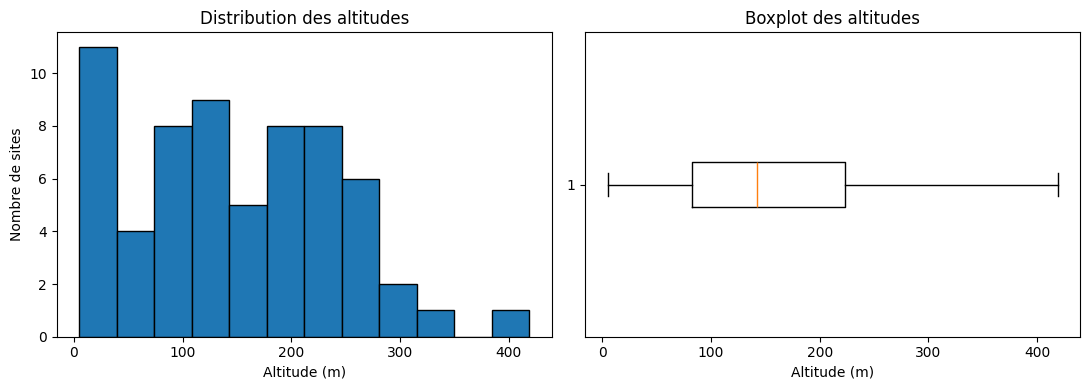

Bornes IQR : [-129.70, 435.10] m
Nombre de sites atypiques : 0


,site_code,region,habitat_category,elevation_m


In [60]:
import matplotlib.pyplot as plt

altitude = df_sites["elevation_m"].dropna()

display(altitude.describe().to_frame("elevation_m").round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(altitude, bins=12, edgecolor="black")
axes[0].set(
    title="Distribution des altitudes",
    xlabel="Altitude (m)",
    ylabel="Nombre de sites"
)

axes[1].boxplot(altitude, vert=False)
axes[1].set(
    title="Boxplot des altitudes",
    xlabel="Altitude (m)"
)

plt.tight_layout()
plt.show()

q1, q3 = altitude.quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df_sites.loc[
    df_sites["elevation_m"].lt(lower)
    | df_sites["elevation_m"].gt(upper),
    ["site_code", "region", "habitat_category", "elevation_m"]
]

print(f"Bornes IQR : [{lower:.2f}, {upper:.2f}] m")
print("Nombre de sites atypiques :", len(outliers))
display(outliers)

#### Interprétation et décision

Les 63 altitudes renseignées varient de 5 à 418,80 m. La moyenne est de
147,85 m et la médiane de 142,40 m. La moitié des sites se situe entre
82,10 et 223,30 m.

L’histogramme montre une dispersion importante, avec quelques sites
d’altitude plus élevée. Aucune valeur ne dépasse les bornes IQR
[-129,70 ; 435,10] m : aucun site n’est donc signalé comme atypique
par cette méthode.

Ces bornes sont statistiques et ne constituent pas des limites physiques.
L’absence d’outliers IQR ne garantit pas l’exactitude de chaque altitude,
mais ce contrôle ne fournit aucun motif de correction ou de suppression.
Toutes les valeurs renseignées sont conservées.

#### 1.4. Répartition géographique des sites

Les coordonnées sont visualisées par région afin d’observer les regroupements
géographiques et de repérer d’éventuels sites isolés ou associés à une région
inhabituelle.

Ce graphique utilise les coordonnées en degrés : il permet une inspection
visuelle, mais ne sert pas à mesurer directement les distances.

,nombre_sites,latitude_min,latitude_max,longitude_min,longitude_max
region,,,,,
Eastern Avelora Agricultural Cluster,22,7.3427,7.7568,101.3263,102.0928
Kintara Karst Cluster,22,4.3872,5.0398,112.0095,112.6905
Tembara Coastal Cluster,20,1.7668,2.5893,104.0316,104.5686


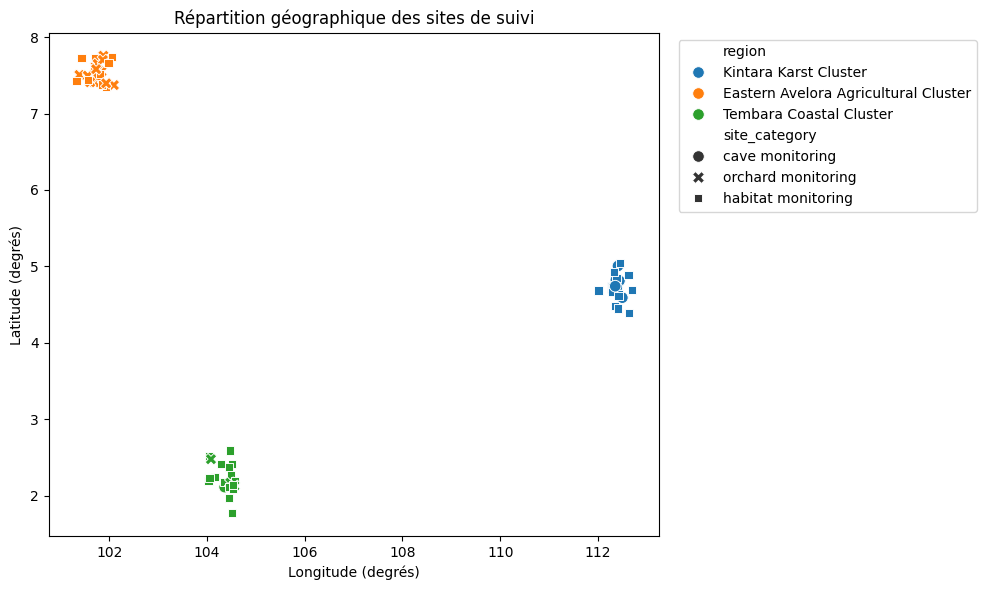

In [61]:
import seaborn as sns

display(
    df_sites.groupby("region").agg(
        nombre_sites=("site_code", "size"),
        latitude_min=("latitude", "min"),
        latitude_max=("latitude", "max"),
        longitude_min=("longitude", "min"),
        longitude_max=("longitude", "max")
    ).round(4)
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_sites,
    x="longitude",
    y="latitude",
    hue="region",
    style="site_category",
    s=70
)

plt.title("Répartition géographique des sites de suivi")
plt.xlabel("Longitude (degrés)")
plt.ylabel("Latitude (degrés)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### Interprétation et décision

Les 64 sites se répartissent en trois groupes géographiques distincts :
22 sites dans Eastern Avelora Agricultural Cluster, 22 dans Kintara Karst
Cluster et 20 dans Tembara Coastal Cluster.

Les regroupements visibles correspondent aux régions renseignées.
Aucun site ne paraît nettement détaché de son groupe régional à cette
échelle de visualisation.

Ce contrôle montre une cohérence interne entre coordonnées et régions,
sans confirmer l’exactitude des positions à partir d’une référence externe.
Aucune correction géographique n’est appliquée.

### 2. Audit approfondi de `bat_surveys.csv`

#### 2.1. Examen des valeurs manquantes

Les valeurs manquantes sont examinées sur les données issues du nettoyage
commun. Les observations concernées sont affichées avant de décider
d’un éventuel traitement. Aucune imputation n’est appliquée à cette étape.

In [62]:
name = "bat_surveys.csv"
df = cleaned_datasets[name]

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing = missing.loc[
    missing["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print("Dataset :", name)
print("Dimensions :", df.shape)
print("Total de valeurs manquantes :", missing["missing_count"].sum())

display(missing)

Dataset : bat_surveys.csv
Dimensions : (4992, 14)
Total de valeurs manquantes : 20


,missing_count,missing_percent
observer_team,20,0.4


#### Investigation de `observer_team`

La variable `observer_team` présente 20 valeurs manquantes, soit 0,40 %
des observations.

Nous examinons sa description, les équipes renseignées et les observations
concernées avant de déterminer si une imputation est justifiée.

In [63]:
name = "bat_surveys.csv"
col = "observer_team"
df = cleaned_datasets[name]

# Description de la variable
display(
    dictionary.loc[
        dictionary["file_name"].eq(name)
        & dictionary["field_name"].eq(col),
        ["field_name", "logical_type", "description", "example_value"]
    ]
)

# Répartition des équipes, valeurs manquantes comprises
display(df[col].value_counts(dropna=False).to_frame("effectif"))

# Observations dont l’équipe est manquante
display(df.loc[df[col].isna()].head(10))

,field_name,logical_type,description,example_value
117,observer_team,categorical_or_text,Observer team.,TEAM-11-2


,effectif
observer_team,
TEAM-11-3,390
TEAM-11-4,390
TEAM-12-1,389
TEAM-11-2,388
TEAM-12-2,388
TEAM-12-5,312
TEAM-12-4,312
TEAM-13-3,311
TEAM-13-5,311


,survey_id,site_code,survey_start,survey_end,survey_method,observation_hours,observed_bat_count,acoustic_detection_count,nightly_visit_count,colony_estimate,comparison_species_count,observer_team,survey_quality,weather_interference
687,BAT-0000688,KNT-CYP,2024-04-05 18:00:00,2024-04-12,acoustic_and_visual,29.1,32,46,21,33.6,12,NaN,acceptable,36.6
902,BAT-0000903,KNT-NNM,2022-09-05 18:00:00,2022-09-12,acoustic_and_visual,31.2,8,18,11,10.6,15,NaN,acceptable,24.8
1382,BAT-0001383,KNT-WUQ,2023-09-05 18:00:00,2023-09-12,fixed_acoustic_station,30.6,9,13,9,11.6,16,NaN,high,59.6
1413,BAT-0001414,KNT-DMJ,2019-10-05 18:00:00,2019-10-12,acoustic_and_visual,27.8,5,5,2,7.2,18,NaN,high,43.9
2280,BAT-0002281,AVL-ARU,2020-07-05 18:00:00,2020-07-12,fixed_acoustic_station,15.7,5,5,1,4.4,10,NaN,limited,47.9
2292,BAT-0002293,AVL-ARU,2021-07-05 18:00:00,2021-07-12,acoustic_and_visual,29.9,12,19,12,13.6,13,NaN,acceptable,50.6
2303,BAT-0002304,AVL-ARU,2022-06-05 18:00:00,2022-06-12,acoustic_transect,25.8,13,18,12,15.7,11,NaN,acceptable,41.6
2600,BAT-0002601,AVL-RNY,2021-03-05 18:00:00,2021-03-12,acoustic_and_visual,39.9,39,38,22,49.9,7,NaN,acceptable,0.0
2900,BAT-0002901,AVL-YAU,2020-03-05 18:00:00,2020-03-12,acoustic_transect,27.0,23,23,22,24.5,12,NaN,high,26.6
3404,BAT-0003405,AVL-FNM,2023-03-05 18:00:00,2023-03-12,acoustic_and_visual,33.8,11,19,8,10.6,10,NaN,high,5.5


#### Analyse de la relation entre les équipes et les sites

Nous examinons le nombre d’équipes distinctes renseignées pour chaque site,
ainsi que le nombre de sites suivis par chaque équipe.

Cette analyse permet d’évaluer si le site peut servir à proposer une équipe
pour les observations où `observer_team` est manquant.

In [64]:
df = cleaned_datasets["bat_surveys.csv"]

# Nombre de sites distincts suivis par chaque équipe
sites_per_team = (
    df.dropna(subset=["observer_team"])
    .groupby("observer_team")["site_code"]
    .nunique()
    .sort_values()
)

display(sites_per_team.to_frame("nombre_sites"))

# Nombre d’équipes distinctes connues pour chaque site
teams_per_site = (
    df.dropna(subset=["observer_team"])
    .groupby("site_code")["observer_team"]
    .nunique()
    .sort_values(ascending=False)
)

display(teams_per_site.to_frame("nombre_equipes"))

print("Sites avec une seule équipe connue :", teams_per_site.eq(1).sum())
print("Sites avec plusieurs équipes connues :", teams_per_site.gt(1).sum())

,nombre_sites
observer_team,
TEAM-11-1,3
TEAM-11-5,4
TEAM-12-3,4
TEAM-13-3,4
TEAM-13-2,4
TEAM-13-1,4
TEAM-12-5,4
TEAM-12-4,4
TEAM-13-5,4


,nombre_equipes
site_code,
AVL-ABG,1
AVL-ARU,1
AVL-BVM,1
AVL-BWK,1
AVL-DER,1
...,...
TMB-VZT,1
TMB-WQL,1
TMB-WST,1


Sites avec une seule équipe connue : 64
Sites avec plusieurs équipes connues : 0


#### Interprétation

Chaque équipe suit plusieurs sites, mais chacun des 64 sites est associé
à une seule équipe parmi les observations renseignées.

Cette association permet de proposer une équipe pour les valeurs manquantes,
sous l’hypothèse qu’elle reste stable sur la période étudiée.

Nous vérifions maintenant que les sites des 20 observations concernées
disposent bien d’une équipe unique connue avant toute imputation.

In [65]:
df = cleaned_datasets["bat_surveys.csv"]

# Équipes connues pour chaque site
site_teams = (
    df.dropna(subset=["observer_team"])
    .groupby("site_code")["observer_team"]
    .agg(nombre_equipes="nunique", equipe_proposee="first")
)

# Examiner uniquement les observations dont l’équipe est manquante
missing_teams = (
    df.loc[df["observer_team"].isna(), ["survey_id", "site_code"]]
    .join(site_teams, on="site_code")
)

display(missing_teams)

print("Observations concernées :", len(missing_teams))
print(
    "Observations avec une équipe unique connue :",
    missing_teams["nombre_equipes"].eq(1).sum()
)

# Ce contrôle ne modifie aucune donnée
assert missing_teams["nombre_equipes"].eq(1).all(), (
    "Certains sites n’ont aucune équipe connue ou en possèdent plusieurs."
)

,survey_id,site_code,nombre_equipes,equipe_proposee
687,BAT-0000688,KNT-CYP,1,TEAM-11-2
902,BAT-0000903,KNT-NNM,1,TEAM-11-5
1382,BAT-0001383,KNT-WUQ,1,TEAM-11-1
1413,BAT-0001414,KNT-DMJ,1,TEAM-11-2
2280,BAT-0002281,AVL-ARU,1,TEAM-12-3
2292,BAT-0002293,AVL-ARU,1,TEAM-12-3
2303,BAT-0002304,AVL-ARU,1,TEAM-12-3
2600,BAT-0002601,AVL-RNY,1,TEAM-12-2
2900,BAT-0002901,AVL-YAU,1,TEAM-12-1
3404,BAT-0003405,AVL-FNM,1,TEAM-12-2


Observations concernées : 20
Observations avec une équipe unique connue : 20


#### Décision d’imputation

Les 20 observations dont l’équipe est manquante correspondent toutes à des
sites possédant une seule équipe connue dans les données renseignées.

Nous retenons donc une imputation par site, sous l’hypothèse que l’association
entre site et équipe reste stable sur la période étudiée. Seules les valeurs
manquantes de `observer_team` seront complétées ; les valeurs déjà renseignées
resteront inchangées.

In [66]:
df = cleaned_datasets["bat_surveys.csv"]

# Conserver l’état initial pour contrôler les modifications
before = df["observer_team"].copy()
missing_mask = before.isna()

# Vérifier qu’une équipe unique est connue pour chaque site concerné
proposed_teams = df.loc[missing_mask, "site_code"].map(
    site_teams.loc[
        site_teams["nombre_equipes"].eq(1),
        "equipe_proposee"
    ]
)

assert proposed_teams.notna().all(), "Certaines équipes ne peuvent pas être proposées."

# Compléter uniquement les valeurs manquantes
df.loc[missing_mask, "observer_team"] = proposed_teams

# Vérifier le résultat et la conservation des valeurs déjà renseignées
assert df["observer_team"].notna().all()
assert df.loc[~missing_mask, "observer_team"].equals(before.loc[~missing_mask])

print("Valeurs imputées :", missing_mask.sum())
print("Valeurs manquantes restantes :", df["observer_team"].isna().sum())

Valeurs imputées : 20
Valeurs manquantes restantes : 0


#### Bilan du traitement des valeurs manquantes

Les 20 valeurs manquantes de `observer_team` ont été complétées à partir
de l’équipe unique connue pour chaque site, sous l’hypothèse d’une association
stable entre site et équipe.

Aucune valeur manquante ne subsiste dans `observer_team`. Les valeurs
déjà renseignées sont inchangées et aucune ligne n’a été supprimée.

#### 2.2. Détection des valeurs atypiques

Les variables numériques sont examinées à l’aide de statistiques descriptives
et de la méthode interquartile (IQR).

Les valeurs signalées sont des observations à vérifier, pas nécessairement
des erreurs. Les différences entre sites et les conditions d’observation
seront prises en compte avant toute correction ou suppression.

In [67]:
df = cleaned_datasets["bat_surveys.csv"]

numeric_cols = dictionary.loc[
    dictionary["file_name"].eq("bat_surveys.csv")
    & dictionary["logical_type"].eq("numeric"),
    "field_name"
].tolist()

display(df[numeric_cols].describe().T.round(2))

outliers_bats = eco_utils.summarize_outliers(df, numeric_cols)
display(outliers_bats.round(2))

,count,mean,std,min,25%,50%,75%,max
observation_hours,4992.0,30.33,5.50,5.0,26.9,30.6,34.1,46.9
observed_bat_count,4992.0,14.13,8.25,0.0,8.0,13.0,18.0,73.0
acoustic_detection_count,4992.0,20.48,12.13,0.0,12.0,18.0,26.0,107.0
nightly_visit_count,4992.0,10.11,6.06,0.0,6.0,9.0,13.0,54.0
colony_estimate,4992.0,15.83,9.60,0.0,9.3,14.2,20.5,99.6
comparison_species_count,4992.0,10.71,3.45,1.0,8.0,11.0,13.0,26.0
weather_interference,4992.0,37.49,16.66,0.0,25.1,36.7,49.0,100.0


,variable,nombre_renseigne,Q1,Q3,borne_inferieure,borne_superieure,nombre_atypiques,pourcentage_atypiques
0,observation_hours,4992,26.9,34.1,16.10,44.90,67,1.34
1,observed_bat_count,4992,8.0,18.0,-7.00,33.00,128,2.56
2,acoustic_detection_count,4992,12.0,26.0,-9.00,47.00,160,3.21
3,nightly_visit_count,4992,6.0,13.0,-4.50,23.50,158,3.17
4,colony_estimate,4992,9.3,20.5,-7.50,37.30,155,3.10
5,comparison_species_count,4992,8.0,13.0,0.50,20.50,29,0.58
6,weather_interference,4992,25.1,49.0,-10.75,84.85,32,0.64


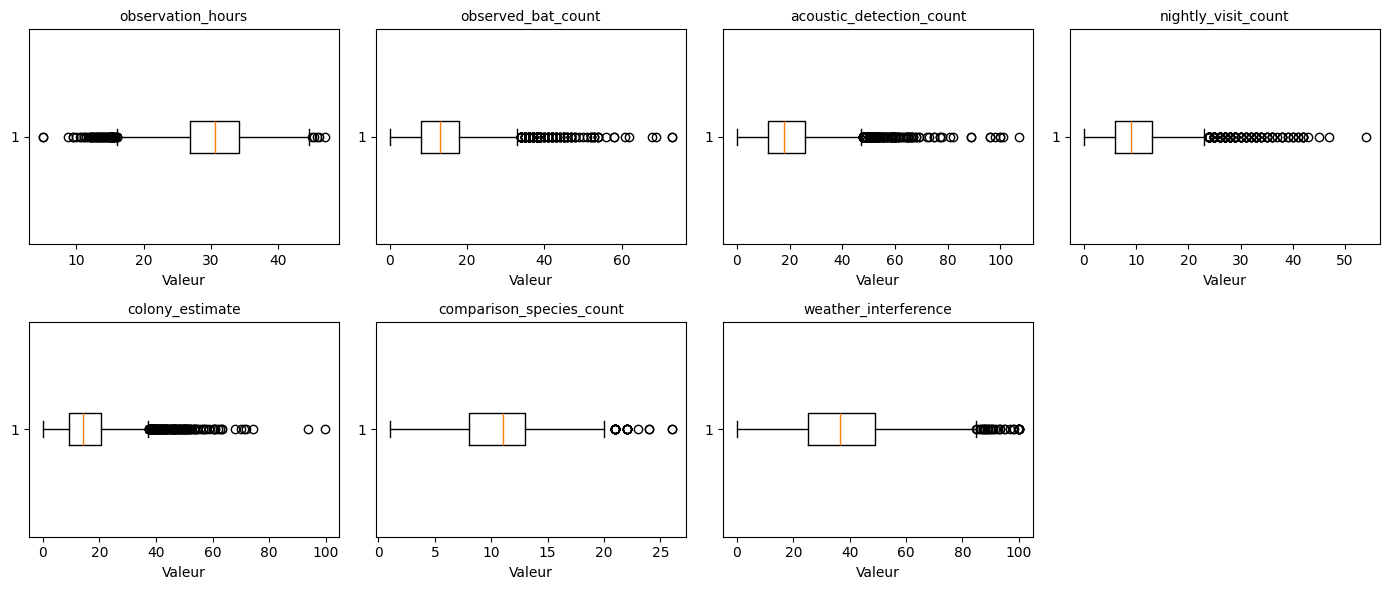

In [68]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 6))

for ax, col in zip(axes.flat, numeric_cols):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Valeur")

for ax in list(axes.flat)[len(numeric_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [69]:
df = cleaned_datasets["bat_surveys.csv"]
cases = []

for _, bounds in outliers_bats.iterrows():
    col = bounds["variable"]

    for direction, mask in [
        ("Faible", df[col].lt(bounds["borne_inferieure"])),
        ("Élevée", df[col].gt(bounds["borne_superieure"]))
    ]:
        candidates = df.loc[mask]

        if candidates.empty:
            continue

        index = (
            candidates[col].idxmin()
            if direction == "Faible"
            else candidates[col].idxmax()
        )

        row = df.loc[index]

        cases.append({
            "variable": col,
            "type": direction,
            "valeur": row[col],
            "survey_id": row["survey_id"],
            "site_code": row["site_code"],
            "date": row["survey_start"],
            "heures": row["observation_hours"],
            "comptage": row["observed_bat_count"],
            "methode": row["survey_method"],
            "qualite": row["survey_quality"],
            "interference_meteo": row["weather_interference"]
        })

display(pd.DataFrame(cases))

,variable,type,valeur,survey_id,site_code,date,heures,comptage,methode,qualite,interference_meteo
0,observation_hours,Faible,5.0,BAT-0002110,AVL-TRP,2019-04-05 18:00:00,5.0,9,acoustic_transect,limited,16.0
1,observation_hours,Élevée,46.9,BAT-0001700,KNT-TLQ,2024-02-05 18:00:00,46.9,18,fixed_acoustic_station,high,0.0
2,observed_bat_count,Élevée,73.0,BAT-0004006,TMB-BRC,2021-04-05 18:00:00,35.6,73,acoustic_transect,high,35.0
3,acoustic_detection_count,Élevée,107.0,BAT-0004032,TMB-BRC,2023-06-05 18:00:00,40.1,52,acoustic_and_visual,high,12.8
4,nightly_visit_count,Élevée,54.0,BAT-0004052,TMB-BRC,2025-02-05 18:00:00,30.2,73,acoustic_and_visual,high,39.1
5,colony_estimate,Élevée,99.6,BAT-0004052,TMB-BRC,2025-02-05 18:00:00,30.2,73,acoustic_and_visual,high,39.1
6,comparison_species_count,Élevée,26.0,BAT-0001179,KNT-CHP,2019-09-05 18:00:00,15.4,9,fixed_acoustic_station,limited,52.7
7,weather_interference,Élevée,100.0,BAT-0003924,TMB-GWP,2020-12-05 18:00:00,15.1,9,fixed_acoustic_station,acceptable,100.0


In [70]:
df = cleaned_datasets["bat_surveys.csv"]

site_groups = df.groupby("site_code")["observed_bat_count"]

q1_site = site_groups.transform(lambda s: s.quantile(0.25))
q3_site = site_groups.transform(lambda s: s.quantile(0.75))
iqr_site = q3_site - q1_site

lower_site = q1_site - 1.5 * iqr_site
upper_site = q3_site + 1.5 * iqr_site

local_mask = (
    df["observed_bat_count"].lt(lower_site)
    | df["observed_bat_count"].gt(upper_site)
)

local_atypical_bats = df.loc[
    local_mask,
    [
        "survey_id", "site_code", "survey_start",
        "observed_bat_count", "observation_hours",
        "survey_method", "survey_quality", "weather_interference"
    ]
].copy()

local_atypical_bats["borne_inferieure_site"] = lower_site[local_mask]
local_atypical_bats["borne_superieure_site"] = upper_site[local_mask]

print("Valeurs atypiques selon les bornes par site :", local_mask.sum())

display(
    local_atypical_bats.sort_values(
        ["site_code", "survey_start"]
    )
)

Valeurs atypiques selon les bornes par site : 63


,survey_id,site_code,survey_start,observed_bat_count,observation_hours,survey_method,survey_quality,weather_interference,borne_inferieure_site,borne_superieure_site
3157,BAT-0003158,AVL-ABG,2022-02-05 18:00:00,22,36.2,acoustic_and_visual,high,6.8,4.000,20.000
2302,BAT-0002303,AVL-ARU,2022-05-05 18:00:00,28,37.3,fixed_acoustic_station,high,29.9,-3.000,21.000
2314,BAT-0002315,AVL-ARU,2023-05-05 18:00:00,26,36.2,acoustic_transect,acceptable,34.1,-3.000,21.000
3057,BAT-0003058,AVL-BVM,2020-04-05 18:00:00,26,35.2,fixed_acoustic_station,high,24.1,2.625,25.625
3094,BAT-0003095,AVL-BVM,2023-05-05 18:00:00,28,32.9,acoustic_transect,high,33.1,2.625,25.625
...,...,...,...,...,...,...,...,...,...,...
4790,BAT-0004791,TMB-WQL,2021-09-05 18:00:00,24,40.1,fixed_acoustic_station,high,24.3,1.500,21.500
4799,BAT-0004800,TMB-WQL,2022-06-05 18:00:00,22,37.3,fixed_acoustic_station,high,26.1,1.500,21.500
4819,BAT-0004820,TMB-WQL,2024-02-05 18:00:00,22,31.1,fixed_acoustic_station,acceptable,40.7,1.500,21.500
4657,BAT-0004658,TMB-WST,2023-08-05 18:00:00,31,45.0,acoustic_and_visual,high,10.3,-0.500,27.500


#### Analyse des observations signalées

Les écarts aux bornes sont d’ampleur variable. À AVL-BVM, le comptage de 26
dépasse légèrement la borne supérieure de 25,625 ; à AVL-ARU, le comptage
de 28 dépasse davantage la borne de 21. Le signalement IQR ne traduit
donc pas une même intensité d’écart pour tous les relevés.

Deux observations élevées à AVL-ARU surviennent en mai, en 2022 et 2023.
Cette répétition suggère une piste saisonnière à examiner, sans suffire
à établir une saisonnalité.

À TMB-WST et TMB-WYT, les comptages élevés accompagnent des durées
d’observation importantes, respectivement 45 et 44,5 heures.
L’effort pourrait contribuer aux valeurs observées, mais cette hypothèse
nécessite une comparaison avec les autres relevés de ces sites.

Les lignes affichées sont de qualité déclarée `high` ou `acceptable`.
Aucune erreur manifeste n’y apparaît, mais cela ne valide pas l’ensemble
des 63 observations. Aucune correction n’est justifiée à ce stade.

In [71]:
df = cleaned_datasets["bat_surveys.csv"]
cases = []

for _, bounds in outliers_bats.iterrows():
    col = bounds["variable"]

    if col == "observed_bat_count":
        continue

    for direction, threshold in [
        ("Faible", bounds["borne_inferieure"]),
        ("Élevée", bounds["borne_superieure"])
    ]:
        mask = df[col].lt(threshold) if direction == "Faible" else df[col].gt(threshold)
        candidates = df.loc[mask]

        if candidates.empty:
            continue

        index = (
            candidates[col].idxmin()
            if direction == "Faible"
            else candidates[col].idxmax()
        )
        row = df.loc[index]

        cases.append({
            "variable": col,
            "type": direction,
            "valeur": row[col],
            "borne_IQR": threshold,
            "survey_id": row["survey_id"],
            "site_code": row["site_code"],
            "date": row["survey_start"],
            "heures": row["observation_hours"],
            "comptage": row["observed_bat_count"],
            "qualite": row["survey_quality"],
            "interference_meteo": row["weather_interference"]
        })

display(pd.DataFrame(cases))

,variable,type,valeur,borne_IQR,survey_id,site_code,date,heures,comptage,qualite,interference_meteo
0,observation_hours,Faible,5.0,16.10,BAT-0002110,AVL-TRP,2019-04-05 18:00:00,5.0,9,limited,16.0
1,observation_hours,Élevée,46.9,44.90,BAT-0001700,KNT-TLQ,2024-02-05 18:00:00,46.9,18,high,0.0
2,acoustic_detection_count,Élevée,107.0,47.00,BAT-0004032,TMB-BRC,2023-06-05 18:00:00,40.1,52,high,12.8
3,nightly_visit_count,Élevée,54.0,23.50,BAT-0004052,TMB-BRC,2025-02-05 18:00:00,30.2,73,high,39.1
4,colony_estimate,Élevée,99.6,37.30,BAT-0004052,TMB-BRC,2025-02-05 18:00:00,30.2,73,high,39.1
5,comparison_species_count,Élevée,26.0,20.50,BAT-0001179,KNT-CHP,2019-09-05 18:00:00,15.4,9,limited,52.7
6,weather_interference,Élevée,100.0,84.85,BAT-0003924,TMB-GWP,2020-12-05 18:00:00,15.1,9,acceptable,100.0


#### Analyse des autres valeurs extrêmes

- **Durées d’observation :** le minimum de 5 heures accompagne une qualité
  `limited`, ce qui est compatible avec un relevé écourté. Le maximum
  de 46,9 heures dépasse légèrement la borne IQR et concerne un relevé
  déclaré de qualité `high`. Aucune erreur de durée n’est démontrée.

- **Détections, visites et estimation de colonie :** les maxima apparaissent
  à TMB-BRC, où les comptages sont également élevés. Cette concordance
  rend plausible une activité importante sur ce site, sans confirmer
  l’exactitude de chaque mesure.

- **Espèces de comparaison :** le maximum de 26 concerne un relevé de
  qualité `limited`. Cette observation reste à vérifier ; la qualité
  déclarée ne suffit pas à conclure que la valeur est fausse.

- **Interférence météorologique :** la valeur de 100 respecte la borne
  autorisée. Elle accompagne une durée courte de 15,1 heures, sans que
  ce rapprochement démontre que la météo a écourté le relevé.

Ces cas extrêmes ne révèlent pas de valeur manifestement impossible.
Ils sont conservés sans correction, avec une attention particulière
aux relevés de qualité limitée. Cet examen porte sur les exemples
affichés et ne valide pas toutes les observations signalées par l’IQR.

#### Bilan des valeurs atypiques — `bat_surveys.csv`

L’analyse IQR a été complétée par un examen des différences entre sites,
de l’effort d’observation, de la qualité des relevés et de plusieurs cas extrêmes.

Les contrôles réalisés n’ont pas démontré d’erreur justifiant une correction
ou une suppression. Les valeurs sont donc conservées. Les relevés signalés,
notamment ceux de qualité limitée, restent à prendre en compte avec prudence
dans les analyses ultérieures.

Cette décision ne constitue pas une validation de l’exactitude de chaque mesure.

### 3. Audit approfondi de `environmental_monthly.csv`

#### 3.1. Analyse des valeurs manquantes

Les colonnes contenant des valeurs manquantes sont identifiées dans les
données issues du nettoyage commun. Leur nombre et leur proportion sont
calculés avant d’examiner les traitements possibles.

In [72]:
df = cleaned_datasets["environmental_monthly.csv"]

# 1. Vérifier les valeurs manquantes
columns_to_check = [
    "weather_exception_code",
    "mean_temperature_c",
    "rainfall_mm",
    "mean_humidity_pct",
    "pesticide_index",
    "vegetation_cover_pct"
]

display(show_missing(df[columns_to_check]))

print("Variables météorologiques quantitatives — valeurs renseignées :")
display(
    df[["mean_temperature_c", "rainfall_mm", "mean_humidity_pct"]]
    .notna()
    .sum()
    .to_frame("nombre_renseigne")
)

# 2. Identifier les lignes à supprimer
required_columns = ["pesticide_index", "vegetation_cover_pct"]
missing_mask = df[required_columns].isna().any(axis=1)

print("Lignes concernées :", missing_mask.sum())
print("Pourcentage :", round(100 * missing_mask.mean(), 2), "%")
print(
    "Lignes manquantes pour les deux variables :",
    df[required_columns].isna().all(axis=1).sum()
)

# 3. Vérifier la couverture de chaque site après suppression envisagée
before_counts = df.groupby("site_code").size()
after_counts = (
    df.loc[~missing_mask]
    .groupby("site_code")
    .size()
    .reindex(before_counts.index, fill_value=0)
)

coverage = pd.DataFrame({
    "releves_avant": before_counts,
    "releves_supprimes": before_counts - after_counts,
    "releves_apres": after_counts
})

display(coverage.loc[coverage["releves_supprimes"].gt(0)])

print("Sites avant :", len(before_counts))
print("Sites conservés :", after_counts.gt(0).sum())
print("Lignes restantes :", (~missing_mask).sum())

,missing_count,missing_percent
weather_exception_code,4788,95.91
pesticide_index,15,0.30
vegetation_cover_pct,10,0.20


Variables météorologiques quantitatives — valeurs renseignées :


,nombre_renseigne
mean_temperature_c,4992
rainfall_mm,4992
mean_humidity_pct,4992


Lignes concernées : 25
Pourcentage : 0.5 %
Lignes manquantes pour les deux variables : 0


,releves_avant,releves_supprimes,releves_apres
site_code,,,
AVL-BWK,78,1,77
AVL-DER,78,1,77
AVL-GRB,78,1,77
AVL-HUA,78,1,77
AVL-NMQ,78,1,77
AVL-RBC,78,1,77
AVL-SEY,78,1,77
KNT-BME,78,2,76
KNT-DMJ,78,1,77


Sites avant : 64
Sites conservés : 64
Lignes restantes : 4967


In [73]:
name = "environmental_monthly.csv"
df = cleaned_datasets[name]

# Conserver les lignes retirées pour la traçabilité
required_columns = ["pesticide_index", "vegetation_cover_pct"]
missing_mask = df[required_columns].isna().any(axis=1)

removed_environmental_rows = df.loc[missing_mask].copy()

# Supprimer les lignes incomplètes et la colonne météo peu renseignée
df_clean = (
    df.loc[~missing_mask]
    .drop(columns=["weather_exception_code"])
    .copy()
)

# Vérifier les transformations
assert len(df_clean) == len(df) - missing_mask.sum()
assert df_clean["site_code"].nunique() == df["site_code"].nunique()
assert df_clean[required_columns].notna().all().all()
assert "weather_exception_code" not in df_clean.columns

cleaned_datasets[name] = df_clean

print("Lignes supprimées :", len(removed_environmental_rows))
print("Dimensions avant :", df.shape)
print("Dimensions après :", df_clean.shape)
print("Sites conservés :", df_clean["site_code"].nunique())

display(show_missing(df_clean))

Lignes supprimées : 25
Dimensions avant : (4992, 11)
Dimensions après : (4967, 10)
Sites conservés : 64


,missing_count,missing_percent


#### Bilan du traitement des valeurs manquantes

La colonne `weather_exception_code` a été retirée de la table d’analyse.

Les colonnes de température, de pluie et d’humidité sont conservées
pour les lignes restantes. La suppression des 25 lignes incomplètes
retire toutefois aussi leurs autres mesures renseignées.
Les données brutes restent disponibles pour les retrouver.

Les 25 lignes incomplètes pour `pesticide_index` ou `vegetation_cover_pct`
ont été supprimées, soit 0,50 % des observations. Elles sont conservées
séparément dans `removed_environmental_rows` pour la traçabilité.

Le fichier contient désormais **4 967 lignes et 10 colonnes**.
Les **64 sites** restent représentés. Les mois retirés constituent
des lacunes à prendre en compte dans les analyses temporelles.

#### 3.2. Détection des valeurs atypiques

Les variables numériques de `environmental_monthly.csv` sont examinées
à l’aide de statistiques descriptives et de la méthode interquartile (IQR).

Les valeurs signalées seront confrontées aux bornes autorisées et au contexte
du site et de la période. Un événement météorologique exceptionnel peut
produire une valeur atypique sans constituer une erreur.

In [74]:
name = "environmental_monthly.csv"
df = cleaned_datasets[name]

numeric_cols = dictionary.loc[
    dictionary["file_name"].eq(name)
    & dictionary["logical_type"].eq("numeric"),
    "field_name"
].tolist()

display(df[numeric_cols].describe().T.round(2))

outliers_environment = eco_utils.summarize_outliers(df, numeric_cols)
display(outliers_environment.round(2))

,count,mean,std,min,25%,50%,75%,max
mean_temperature_c,4967.0,26.38,1.67,21.3,25.19,26.35,27.62,32.0
rainfall_mm,4967.0,159.92,74.84,5.0,95.75,156.30,221.70,384.3
mean_humidity_pct,4967.0,75.84,7.25,56.7,70.30,75.90,81.50,96.4
vegetation_cover_pct,4967.0,60.99,13.99,15.0,52.70,62.30,70.90,98.0
habitat_disturbance_index,4967.0,30.37,16.36,0.0,17.90,29.40,41.40,86.8
pesticide_index,4967.0,24.99,16.27,0.0,11.55,25.10,37.50,77.3
data_completeness_pct,4967.0,95.96,2.82,85.5,94.00,96.10,98.20,100.0


,variable,nombre_renseigne,Q1,Q3,borne_inferieure,borne_superieure,nombre_atypiques,pourcentage_atypiques
0,mean_temperature_c,4967,25.19,27.62,21.54,31.26,9,0.18
1,rainfall_mm,4967,95.75,221.70,-93.17,410.62,0,0.00
2,mean_humidity_pct,4967,70.30,81.50,53.50,98.30,0,0.00
3,vegetation_cover_pct,4967,52.70,70.90,25.40,98.20,46,0.93
4,habitat_disturbance_index,4967,17.90,41.40,-17.35,76.65,19,0.38
5,pesticide_index,4967,11.55,37.50,-27.37,76.42,1,0.02
6,data_completeness_pct,4967,94.00,98.20,87.70,104.50,13,0.26


In [75]:
df = cleaned_datasets["environmental_monthly.csv"]
cases = []

for _, bounds in outliers_environment.iterrows():
    col = bounds["variable"]

    for direction, threshold in [
        ("Faible", bounds["borne_inferieure"]),
        ("Élevée", bounds["borne_superieure"])
    ]:
        mask = df[col].lt(threshold) if direction == "Faible" else df[col].gt(threshold)
        candidates = df.loc[mask]

        if candidates.empty:
            continue

        index = (
            candidates[col].idxmin()
            if direction == "Faible"
            else candidates[col].idxmax()
        )
        row = df.loc[index]

        cases.append({
            "variable": col,
            "type": direction,
            "valeur": row[col],
            "borne_IQR": threshold,
            "site_code": row["site_code"],
            "mois": row["reporting_month"],
            "land_use_category": row["land_use_category"],
            "data_completeness_pct": row["data_completeness_pct"]
        })

display(pd.DataFrame(cases))

,variable,type,valeur,borne_IQR,site_code,mois,land_use_category,data_completeness_pct
0,mean_temperature_c,Faible,21.3,21.545,AVL-SEY,2019-10-01,mixed_forest,90.9
1,mean_temperature_c,Élevée,32.0,31.265,TMB-UVF,2022-04-01,mixed_forest,97.3
2,vegetation_cover_pct,Faible,15.0,25.400,KNT-YRX,2025-02-01,mixed_forest,95.3
3,habitat_disturbance_index,Élevée,86.8,76.650,KNT-GGN,2020-05-01,degraded_land,100.0
4,pesticide_index,Élevée,77.3,76.425,KNT-GKR,2024-02-01,mixed_forest,95.4
5,data_completeness_pct,Faible,85.5,87.700,TMB-HFR,2019-10-01,mixed_forest,85.5


#### Analyse des cas extrêmes

- **Température :** les extrêmes de 21,3 °C et 32 °C dépassent légèrement
  les bornes IQR. Ces valeurs ne sont pas manifestement impossibles,
  mais leur contexte saisonnier et local reste à considérer.

- **Couverture végétale :** la valeur de 15 % à KNT-YRX est faible pour
  un site classé `mixed_forest`. Cette catégorie ne définit toutefois
  pas un pourcentage attendu. Ce cas mérite une comparaison avec
  les autres mois du même site.

- **Perturbation de l’habitat :** l’indice de 86,8 concerne un site
  classé `degraded_land`. Cette association est compatible avec une
  perturbation élevée, sans confirmer la mesure ni l’échelle de l’indice.

- **Pesticides :** la valeur de 77,3 dépasse légèrement la borne de 76,425.
  Le classement `mixed_forest` ne suffit pas à exclure une exposition.
  Sans définition de l’indice, aucune correction n’est justifiée.

- **Complétude :** le minimum de 85,5 % reste dans l’intervalle autorisé.
  Il indique une couverture moindre, à prendre en compte dans
  l’interprétation des mesures du mois concerné.

Ces exemples ne démontrent pas d’erreur. Les valeurs restent inchangées
à ce stade ; la faible couverture végétale est retenue pour vérification.

count    77.00
mean     34.92
std       6.53
min      15.00
25%      29.60
50%      36.00
75%      39.30
max      51.00
Name: vegetation_cover_pct, dtype: float64

,reporting_month,vegetation_cover_pct,data_completeness_pct
772,2024-11-01,42.2,92.5
773,2024-12-01,25.5,96.2
774,2025-01-01,24.3,95.3
775,2025-02-01,15.0,95.3
776,2025-03-01,35.7,95.4
777,2025-04-01,35.4,94.5
778,2025-05-01,37.6,96.3


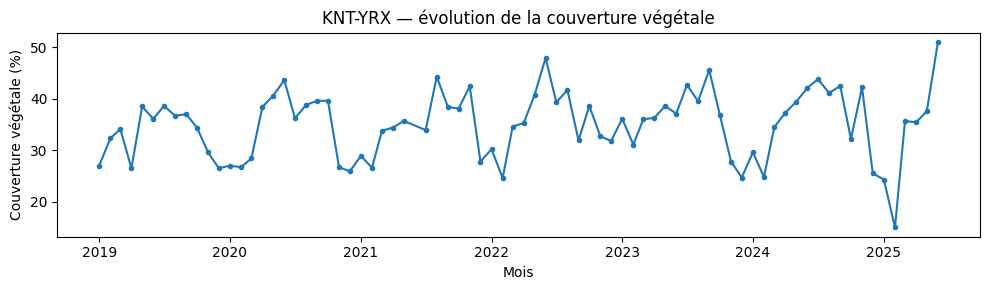

In [76]:
df = cleaned_datasets["environmental_monthly.csv"]

site_vegetation = (
    df.loc[
        df["site_code"].eq("KNT-YRX"),
        ["reporting_month", "vegetation_cover_pct", "data_completeness_pct"]
    ]
    .sort_values("reporting_month")
    .copy()
)

display(site_vegetation["vegetation_cover_pct"].describe().round(2))

# Mois proches de la valeur minimale observée
months = pd.to_datetime(
    site_vegetation["reporting_month"], format="%Y-%m-%d"
)

display(
    site_vegetation.loc[
        months.between("2024-11-01", "2025-05-01")
    ]
)

plt.figure(figsize=(10, 3))
plt.plot(
    months,
    site_vegetation["vegetation_cover_pct"],
    marker="."
)
plt.title("KNT-YRX — évolution de la couverture végétale")
plt.xlabel("Mois")
plt.ylabel("Couverture végétale (%)")
plt.tight_layout()
plt.show()

#### Vérification de la couverture végétale à KNT-YRX

La couverture végétale fluctue généralement entre environ 25 % et 48 %.
La valeur de 15 % en février 2025 constitue un minimum isolé, suivi
d’un retour vers 35 % dès le relevé suivant.

Cette baisse ponctuelle mérite un signalement. Elle peut correspondre
à un changement réel ou à un problème de mesure ; le graphique seul
ne permet pas de trancher. La complétude de 95,3 % ne garantit pas
l’exactitude de cette mesure.

La valeur est conservée sans correction et signalée comme observation
à vérifier, faute d’élément permettant de la remplacer de façon fiable.

#### Bilan des valeurs atypiques — `environmental_monthly.csv`

L’analyse IQR et l’examen des cas extrêmes n’ont pas démontré d’erreur
justifiant une correction ou une suppression supplémentaire.

La couverture végétale de 15 % à KNT-YRX en février 2025 reste signalée
pour vérification. Les faibles taux de complétude seront également pris
en compte lors de l’interprétation des mesures.

Les valeurs sont conservées à ce stade. Les vérifications réalisées
ne constituent pas une validation de l’exactitude de chaque observation.

### 4. Audit approfondi de `monitoring_device_operations.csv`

#### 4.1. Analyse des valeurs manquantes

Les colonnes contenant des valeurs manquantes sont identifiées dans
les données issues du nettoyage commun. Leur nombre et leur proportion
sont calculés avant de déterminer les traitements adaptés.

In [77]:
name = "monitoring_device_operations.csv"
df = cleaned_datasets[name]

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing = missing.loc[
    missing["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print("Dataset :", name)
print("Dimensions :", df.shape)
print("Total de valeurs manquantes :", missing["missing_count"].sum())

display(missing)

Dataset : monitoring_device_operations.csv
Dimensions : (4992, 11)
Total de valeurs manquantes : 4833


,missing_count,missing_percent
fault_code,4803,96.21
maintenance_provider,30,0.60


In [78]:
name = "monitoring_device_operations.csv"
df = cleaned_datasets[name]

display(
    dictionary.loc[
        dictionary["file_name"].eq(name)
        & dictionary["field_name"].isin(
            ["fault_code", "maintenance_provider"]
        ),
        ["field_name", "description", "example_value"]
    ]
)

# Présence d’un code de panne selon le type de maintenance
display(
    pd.crosstab(
        df["maintenance_type"],
        df["fault_code"].notna().map({
            True: "Code renseigné",
            False: "Code absent"
        }),
        margins=True
    )
)

# Prestataires connus pour les sites concernés par une valeur manquante
providers_by_site = (
    df.dropna(subset=["maintenance_provider"])
    .groupby("site_code")["maintenance_provider"]
    .agg(nombre_prestataires="nunique", prestataire_propose="first")
)

missing_providers = (
    df.loc[
        df["maintenance_provider"].isna(),
        ["device_operation_id", "site_code", "device_reference"]
    ]
    .join(providers_by_site, on="site_code")
)

display(missing_providers)

print(
    "Lignes avec un prestataire unique connu pour le site :",
    missing_providers["nombre_prestataires"].eq(1).sum(),
    "/",
    len(missing_providers)
)

,field_name,description,example_value
139,fault_code,Fault code.,STORAGE_LIMIT
140,maintenance_provider,Maintenance provider.,ECO-SERVICE-2


fault_code,Code absent,Code renseigné,All
maintenance_type,,,
corrective maintenance,0,137,137
routine inspection,4803,0,4803
sensor replacement,0,52,52
All,4803,189,4992


,device_operation_id,site_code,device_reference,nombre_prestataires,prestataire_propose
811,DOP-0000812,KNT-GKR,DEV-KNTGKR-1,1,ECO-SERVICE-4
1027,DOP-0001028,KNT-JQG,DEV-KNTJQG-1,1,ECO-SERVICE-3
1064,DOP-0001065,KNT-JQG,DEV-KNTJQG-1,1,ECO-SERVICE-3
1305,DOP-0001306,KNT-YRG,DEV-KNTYRG-1,1,ECO-SERVICE-2
1353,DOP-0001354,KNT-WUQ,DEV-KNTWUQ-2,1,ECO-SERVICE-3
1487,DOP-0001488,KNT-GGN,DEV-KNTGGN-1,1,ECO-SERVICE-1
1581,DOP-0001582,KNT-QWU,DEV-KNTQWU-2,1,ECO-SERVICE-2
1596,DOP-0001597,KNT-QWU,DEV-KNTQWU-2,1,ECO-SERVICE-2
1676,DOP-0001677,KNT-TLQ,DEV-KNTTLQ-3,1,ECO-SERVICE-3
1696,DOP-0001697,KNT-TLQ,DEV-KNTTLQ-3,1,ECO-SERVICE-3


Lignes avec un prestataire unique connu pour le site : 30 / 30


#### Décision pour `maintenance_provider`

Les 30 opérations dont le prestataire est manquant concernent toutes
des sites associés à un seul prestataire dans les observations renseignées.

Nous retenons une imputation par appareil, sous l’hypothèse
que l’association avec son prestataire reste stable pendant
la période étudiée. Seules les valeurs initialement manquantes
sont complétées ; les prestataires déjà renseignés restent inchangés.

Le traitement de `fault_code` sera décidé séparément, après examen
du tableau croisé avec le type de maintenance.

In [79]:
name = "monitoring_device_operations.csv"

cleaned_datasets[name], device_cleaning_summary = (
    eco_utils.complete_device_operations(
        cleaned_datasets[name],
        datasets[name]
    )
)

for label, value in device_cleaning_summary.items():
    print(f"{label} : {value}")

Codes absents remplacés : 4803
Prestataires initialement absents traités : 30
Valeurs manquantes restantes : 0
Observations conservées : 4992


#### Bilan du traitement des valeurs manquantes

Deux traitements ont été appliqués :

- Les 4 803 valeurs manquantes de `fault_code`, associées uniquement aux
  inspections de routine, ont été remplacées par `NO_FAULT`. Cette convention
  signifie « aucune panne déclarée » et ne garantit pas l’absence réelle de panne.
- Les 30 valeurs manquantes de `maintenance_provider` ont été complétées
  à partir du prestataire unique connu pour chaque équipement concerné,
  sous l’hypothèse d’une association stable pendant la période étudiée.

Les contrôles vérifient l’absence de valeurs manquantes et de doublons,
l’unicité de `device_operation_id` et la conservation des 4 992 observations.
Les valeurs initialement renseignées restent inchangées.

#### 4.2. Détection des valeurs atypiques

Les variables `uptime_pct` et `acoustic_quality` sont examinées à l’aide
de statistiques descriptives et de la méthode IQR.

`uptime_pct` représente un pourcentage de disponibilité. Le traitement
numérique d’`acoustic_quality` constitue une exception documentée au
dictionnaire ; son échelle reste à confirmer.

Les valeurs signalées seront examinées avec le type de maintenance
et le code de panne avant de décider d’un éventuel traitement.

In [80]:
name = "monitoring_device_operations.csv"
df = cleaned_datasets[name]

# Inclure l’exception numérique documentée acoustic_quality
numeric_cols = ["uptime_pct", "acoustic_quality"]

display(df[numeric_cols].describe().T.round(2))

outliers_devices = eco_utils.summarize_outliers(df, numeric_cols)
display(outliers_devices.round(2))

,count,mean,std,min,25%,50%,75%,max
uptime_pct,4992.0,92.53,7.93,23.1,90.2,93.8,97.30,100.0
acoustic_quality,4992.0,78.99,8.51,20.0,73.9,79.3,84.62,100.0


,variable,nombre_renseigne,Q1,Q3,borne_inferieure,borne_superieure,nombre_atypiques,pourcentage_atypiques
0,uptime_pct,4992,90.2,97.30,79.55,107.95,182,3.65
1,acoustic_quality,4992,73.9,84.62,57.81,100.71,82,1.64


In [81]:
df = cleaned_datasets["monitoring_device_operations.csv"]

for _, bounds in outliers_devices.iterrows():
    col = bounds["variable"]

    mask = (
        df[col].lt(bounds["borne_inferieure"])
        | df[col].gt(bounds["borne_superieure"])
    )

    print(f"\n{col} — {mask.sum()} valeurs atypiques")

    display(
        pd.crosstab(
            df.loc[mask, "maintenance_type"],
            df.loc[mask, "fault_code"],
            margins=True
        )
    )

    # Afficher les cinq valeurs les plus faibles
    display(
        df.loc[
            mask,
            [
                "device_operation_id", "site_code", "operation_start",
                "uptime_pct", "acoustic_quality",
                "maintenance_type", "fault_code"
            ]
        ].nsmallest(5, col)
    )


uptime_pct — 182 valeurs atypiques


fault_code,MICROPHONE_DRIFT,NO_FAULT,POWER_INTERRUPTION,STORAGE_LIMIT,All
maintenance_type,,,,,
corrective maintenance,41,0,30,53,124
routine inspection,0,6,0,0,6
sensor replacement,52,0,0,0,52
All,93,6,30,53,182


,device_operation_id,site_code,operation_start,uptime_pct,acoustic_quality,maintenance_type,fault_code
2151,DOP-0002152,AVL-TRP,2022-10-01,23.1,57.8,sensor replacement,MICROPHONE_DRIFT
2109,DOP-0002110,AVL-TRP,2019-04-01,23.9,51.6,sensor replacement,MICROPHONE_DRIFT
2114,DOP-0002115,AVL-TRP,2019-09-01,29.0,47.8,sensor replacement,MICROPHONE_DRIFT
1209,DOP-0001210,KNT-CHP,2022-04-01,29.9,62.5,sensor replacement,MICROPHONE_DRIFT
2126,DOP-0002127,AVL-TRP,2020-09-01,31.2,49.3,sensor replacement,MICROPHONE_DRIFT



acoustic_quality — 82 valeurs atypiques


fault_code,MICROPHONE_DRIFT,NO_FAULT,POWER_INTERRUPTION,STORAGE_LIMIT,All
maintenance_type,,,,,
corrective maintenance,12,0,8,10,30
routine inspection,0,12,0,0,12
sensor replacement,40,0,0,0,40
All,52,12,8,10,82


,device_operation_id,site_code,operation_start,uptime_pct,acoustic_quality,maintenance_type,fault_code
1208,DOP-0001209,KNT-CHP,2022-03-01,49.7,20.0,sensor replacement,MICROPHONE_DRIFT
2162,DOP-0002163,AVL-TRP,2023-09-01,46.6,36.1,sensor replacement,MICROPHONE_DRIFT
1196,DOP-0001197,KNT-CHP,2021-03-01,58.8,37.2,sensor replacement,MICROPHONE_DRIFT
1179,DOP-0001180,KNT-CHP,2019-10-01,38.9,39.4,sensor replacement,MICROPHONE_DRIFT
1232,DOP-0001233,KNT-CHP,2024-03-01,44.8,39.7,sensor replacement,MICROPHONE_DRIFT


#### Interprétation et décision

Sur les 182 disponibilités atypiquement faibles, 176 sont associées à un
code de panne et à une maintenance corrective ou un remplacement de capteur.
De même, 70 des 82 valeurs faibles de qualité acoustique accompagnent
une panne déclarée.

Les valeurs les plus faibles affichées correspondent à des remplacements
de capteur avec le code `MICROPHONE_DRIFT`. Cette concordance est compatible
avec un fonctionnement dégradé, plutôt qu’avec une erreur de saisie,
sans prouver l’exactitude de chaque mesure.

Les 6 disponibilités faibles et les 12 qualités acoustiques faibles
associées à `NO_FAULT` restent à vérifier : ce code remplace une information
initialement absente et ne garantit pas le bon fonctionnement du dispositif.
Ces deux groupes peuvent se chevaucher.

Les valeurs sont conservées sans correction. Elles serviront à contextualiser
les relevés de chauves-souris : une faible activité enregistrée pendant une
période de fonctionnement dégradé ne suffit pas à conclure à une baisse
réelle de leur présence.

### 5. Audit approfondi de `orchard_surveys.csv`

#### 5.1. Analyse des valeurs manquantes

Les colonnes contenant des valeurs manquantes sont identifiées dans
les données issues du nettoyage commun. Leur nombre et leur proportion
sont calculés avant de décider d’un éventuel traitement.

In [82]:
name = "orchard_surveys.csv"
df = cleaned_datasets[name]

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing = missing.loc[
    missing["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print("Dataset :", name)
print("Dimensions :", df.shape)
print("Total de valeurs manquantes :", missing["missing_count"].sum())

display(missing)

Dataset : orchard_surveys.csv
Dimensions : (1248, 11)
Total de valeurs manquantes : 1225


,missing_count,missing_percent
agricultural_disturbance_note,1225,98.16


In [83]:
df = datasets["orchard_surveys.csv"]
col = "agricultural_disturbance_note"

print("5 lignes avec une note manquante :")
display(df.loc[df[col].isna()].head(5))

print("5 lignes avec une note renseignée :")
display(df.loc[df[col].notna()].head(5))

5 lignes avec une note manquante :


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
0,ORC-0000001,AVL-MAR,2019-01-01,24.1,40.3,34.7,20400.8,55.2,27.1,38.4,NaN
1,ORC-0000002,AVL-MAR,2019-02-01,24.1,33.8,41.6,17712.7,63.8,44.2,41.6,NaN
2,ORC-0000003,AVL-MAR,2019-03-01,24.1,55.1,57.3,28900.5,77.4,35.2,45.6,NaN
3,ORC-0000004,AVL-MAR,2019-04-01,24.1,90.2,48.7,21992.9,67.4,22.8,36.3,NaN
4,ORC-0000005,AVL-MAR,2019-05-01,24.1,80.7,61.4,27213.5,62.9,31.9,40.7,NaN


5 lignes avec une note renseignée :


,orchard_survey_id,site_code,survey_period,orchard_area_ha,durian_flower_density,fruit_set_rate_pct,durian_yield_kg,other_pollinator_activity,fertilizer_use_index,irrigation_level,agricultural_disturbance_note
9,ORC-0000010,AVL-MAR,2019-10-01,24.1,48.5,51.900,25181.7,63.4,28.4,39.2,storm-related flower loss
321,ORC-0000322,AVL-NFR,2019-10-01,24.4,56.3,47.300,21416.5,57.2,50.6,30.2,storm-related flower loss
422,ORC-0000423,AVL-GRB,2021-09-01,54.4,57.4,44.700,45001.4,43.8,40.5,45.2,storm-related flower loss
454,ORC-0000455,AVL-GRB,2024-05-01,54.4,88.5,0.549,55807.6,60.6,30.7,53.6,elevated pesticide application
758,ORC-0000759,AVL-YAU,2023-09-01,6.0,57.6,44.300,5302.4,50.7,38.5,52.2,storm-related flower loss


In [84]:
orchards = datasets["orchard_surveys.csv"].copy()
environment = datasets["environmental_monthly.csv"].copy()

# Clé temporelle commune
orchards["mois"] = pd.to_datetime(
    orchards["survey_period"], errors="raise"
).dt.to_period("M")

environment["mois"] = pd.to_datetime(
    environment["reporting_month"], errors="raise"
).dt.to_period("M")

# Retirer uniquement les doublons exacts
orchards = orchards.drop_duplicates()
environment = environment.drop_duplicates()

# Une seule observation environnementale attendue par site et mois
assert not environment.duplicated(["site_code", "mois"]).any()

comparison_notes = orchards.merge(
    environment[
        [
            "site_code", "mois", "pesticide_index",
            "rainfall_mm", "mean_temperature_c",
            "mean_humidity_pct", "weather_exception_code"
        ]
    ],
    on=["site_code", "mois"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Relevés sans correspondance environnementale :",
      comparison_notes["_merge"].ne("both").sum())

# Examiner les conditions associées aux 23 notes
display(
    comparison_notes.loc[
        comparison_notes["agricultural_disturbance_note"].notna(),
        [
            "site_code", "mois", "agricultural_disturbance_note",
            "pesticide_index", "rainfall_mm", "mean_temperature_c",
            "mean_humidity_pct", "weather_exception_code"
        ]
    ].sort_values(["site_code", "mois"])
)

Relevés sans correspondance environnementale : 0


,site_code,mois,agricultural_disturbance_note,pesticide_index,rainfall_mm,mean_temperature_c,mean_humidity_pct,weather_exception_code
944,AVL-FNQ,2019-09,elevated pesticide application,70.6,219.3,24.84,81.8,NaN
945,AVL-FNQ,2019-10,storm-related flower loss,58.4,241.5,25.16,83.8,HEAVY_RAIN
946,AVL-FNQ,2019-11,storm-related flower loss,61.6,162.5,25.09,78.0,HEAVY_RAIN
957,AVL-FNQ,2020-10,storm-related flower loss,45.9,219.3,25.18,88.4,HEAVY_RAIN
959,AVL-FNQ,2020-12,storm-related flower loss,44.3,163.6,25.2,78.8,HEAVY_RAIN
964,AVL-FNQ,2021-05,elevated pesticide application,68.2,138.0,27.16,75.0,NaN
965,AVL-FNQ,2021-06,elevated pesticide application,68.0,146.7,27.28,74.1,NaN
969,AVL-FNQ,2021-10,storm-related flower loss,51.9,296.2,25.3,78.7,HEAVY_RAIN
981,AVL-FNQ,2022-10,storm-related flower loss,51.7,253.6,24.88,"80,0",HEAVY_RAIN
982,AVL-FNQ,2022-11,storm-related flower loss,62.3,"199,1",25.4,83.1,HEAVY_RAIN


In [85]:
# Même tableau, pour les observations dont la note est absente
col = "agricultural_disturbance_note"

mask = (
    comparison_notes[col].isna()
    | comparison_notes[col].eq("NOT_RECORDED")
)

display(
    comparison_notes.loc[
        mask,
        [
            "site_code", "mois", col,
            "pesticide_index", "rainfall_mm",
            "mean_temperature_c", "mean_humidity_pct",
            "weather_exception_code"
        ]
    ].sort_values(["site_code", "mois"])
)

,site_code,mois,agricultural_disturbance_note,pesticide_index,rainfall_mm,mean_temperature_c,mean_humidity_pct,weather_exception_code
468,AVL-ECJ,2019-01,NaN,40.5,82.9,27.24,76.4,NaN
469,AVL-ECJ,2019-02,NaN,41.6,93.8,27.85,65.6,NaN
470,AVL-ECJ,2019-03,NaN,43.1,69.6,27.32,67.4,NaN
471,AVL-ECJ,2019-04,NaN,37.6,77.0,28.13,69.4,NaN
472,AVL-ECJ,2019-05,NaN,47.2,110.0,28.49,71.9,NaN
...,...,...,...,...,...,...,...,...
1165,TMB-SKZ,2025-02,NaN,23.7,238.0,27.23,82.4,NaN
1166,TMB-SKZ,2025-03,NaN,38.3,187.0 mm,29.58,74.5,NaN
1167,TMB-SKZ,2025-04,NaN,37.4,162.6,29.73,72.8,NaN
1168,TMB-SKZ,2025-05,NaN,39.4,118.8,29.78,71.0,NaN


In [86]:
col = "agricultural_disturbance_note"

# Notes absentes dans le tableau issu des données brutes
missing_notes = comparison_notes.loc[
    comparison_notes[col].isna()
].copy()

# Conversion pour effectuer la comparaison numérique
pesticide = pd.to_numeric(
    missing_notes["pesticide_index"]
    .astype("string")
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

weather = (
    missing_notes["weather_exception_code"]
    .astype("string")
    .str.strip()
    .str.upper()
)

high_pesticide = pesticide.ge(66.4).fillna(False)
heavy_rain = weather.eq("HEAVY_RAIN").fillna(False)

print("Observations sans note :", len(missing_notes))
print("Indice de pesticides ≥ 66,4 :", high_pesticide.sum())
print("Indice absent ou non convertible :", pesticide.isna().sum())
print("Code HEAVY_RAIN présent :", heavy_rain.sum())
print("Code météo absent :", weather.isna().sum())

print(
    "Tous les indices sont renseignés et strictement < 66,4 :",
    bool(len(missing_notes) > 0
         and pesticide.notna().all()
         and pesticide.lt(66.4).all())
)
print(
    "Aucun code HEAVY_RAIN renseigné :",
    bool(len(missing_notes) > 0 and not heavy_rain.any())
)

# Afficher les contre-exemples et les indices non vérifiables
display(
    missing_notes.loc[
        high_pesticide | heavy_rain | pesticide.isna(),
        [
            "site_code", "mois", col,
            "pesticide_index", "weather_exception_code"
        ]
    ]
)

Observations sans note : 1225
Indice de pesticides ≥ 66,4 : 0
Indice absent ou non convertible : 2
Code HEAVY_RAIN présent : 16
Code météo absent : 1189
Tous les indices sont renseignés et strictement < 66,4 : False
Aucun code HEAVY_RAIN renseigné : False


,site_code,mois,agricultural_disturbance_note,pesticide_index,weather_exception_code
512,AVL-ECJ,2022-09,NaN,36.8,HEAVY_RAIN
564,AVL-RBC,2020-07,NaN,NaN,NaN
734,AVL-YAU,2021-09,NaN,43.8,HEAVY_RAIN
759,AVL-YAU,2023-10,NaN,29.2,HEAVY_RAIN
823,AVL-HUA,2022-08,NaN,47.8,HEAVY_RAIN
926,AVL-NMQ,2024-09,NaN,18.1,HEAVY_RAIN
936,AVL-FNQ,2019-01,NaN,56.5,HEAVY_RAIN
958,AVL-FNQ,2020-11,NaN,46.9,HEAVY_RAIN
960,AVL-FNQ,2021-01,NaN,57.8,HEAVY_RAIN
970,AVL-FNQ,2021-11,NaN,41.9,HEAVY_RAIN


#### Décision de suppression de `agricultural_disturbance_note`

La colonne présente 1 225 valeurs manquantes, soit 98,16 % des observations.

Le rapprochement avec les données environnementales ne permet pas de
reconstituer les notes absentes : 16 observations sans note portent
le code `HEAVY_RAIN`, et 2 possèdent un indice de pesticides manquant.
Les autres indices renseignés sont inférieurs à 66,4, mais ce constat
ne prouve pas l’absence de perturbation.

Nous retirons donc cette colonne de la table destinée au clustering,
sans inventer de notes ni assimiler les absences à « aucune perturbation ».

Les 23 notes renseignées sont conservées séparément pour contextualiser
les analyses. Aucune ligne n’est supprimée.

In [87]:
name = "orchard_surveys.csv"
col = "agricultural_disturbance_note"
df = cleaned_datasets[name]

orchard_notes = df.loc[
    df[col].notna() & df[col].ne("NOT_RECORDED"),
    ["orchard_survey_id", "site_code", "survey_period", col]
].copy()

# Supprimer uniquement la colonne
cleaned_datasets[name] = df.drop(columns=[col]).copy()

assert len(cleaned_datasets[name]) == len(df)
assert col not in cleaned_datasets[name].columns

print("Notes conservées séparément :", len(orchard_notes))
print("Dimensions après suppression :", cleaned_datasets[name].shape)

Notes conservées séparément : 23
Dimensions après suppression : (1248, 10)


#### 5.2. Détection des valeurs atypiques

Les variables numériques de `orchard_surveys.csv` sont examinées
à l’aide de statistiques descriptives et de la méthode IQR.

Les valeurs signalées, notamment les taux de fructification très faibles,
seront examinées avant toute décision de correction ou de suppression.

In [88]:
name = "orchard_surveys.csv"
df = cleaned_datasets[name]

numeric_cols = dictionary.loc[
    dictionary["file_name"].eq(name)
    & dictionary["logical_type"].eq("numeric"),
    "field_name"
].tolist()

display(df[numeric_cols].describe().T.round(2))

outliers_orchards = eco_utils.summarize_outliers(df, numeric_cols)
display(outliers_orchards.round(2))

,count,mean,std,min,25%,50%,75%,max
orchard_area_ha,1248.0,45.53,18.98,6.0,29.90,49.35,59.32,84.7
durian_flower_density,1248.0,63.15,22.37,17.0,45.98,58.55,84.02,100.0
fruit_set_rate_pct,1248.0,53.55,9.31,27.3,47.00,53.00,59.40,87.7
durian_yield_kg,1248.0,47150.89,21479.64,3971.3,31192.90,46774.65,62028.28,118638.7
other_pollinator_activity,1248.0,59.44,9.37,27.9,53.30,59.50,65.70,93.7
fertilizer_use_index,1248.0,38.32,10.73,5.0,31.00,38.10,45.52,74.4
irrigation_level,1248.0,39.97,9.12,11.5,33.80,39.50,45.50,81.0


,variable,nombre_renseigne,Q1,Q3,borne_inferieure,borne_superieure,nombre_atypiques,pourcentage_atypiques
0,orchard_area_ha,1248,29.90,59.32,-14.24,103.46,0,0.00
1,durian_flower_density,1248,45.98,84.02,-11.10,141.10,0,0.00
2,fruit_set_rate_pct,1248,47.00,59.40,28.40,78.00,11,0.88
3,durian_yield_kg,1248,31192.90,62028.28,-15060.16,108281.34,6,0.48
4,other_pollinator_activity,1248,53.30,65.70,34.70,84.30,8,0.64
5,fertilizer_use_index,1248,31.00,45.52,9.21,67.31,9,0.72
6,irrigation_level,1248,33.80,45.50,16.25,63.05,15,1.20


In [89]:
name = "orchard_surveys.csv"
col = "fruit_set_rate_pct"

source_rates = pd.to_numeric(
    datasets[name][col].astype("string").str.replace(",", ".", regex=False),
    errors="raise"
)

suspect_ids = datasets[name].loc[
    source_rates.between(0, 1, inclusive="neither"),
    ["orchard_survey_id", col]
].rename(columns={col: "valeur_source"})

comparison_rates = suspect_ids.merge(
    cleaned_datasets[name][["orchard_survey_id", col]],
    on="orchard_survey_id",
    how="left",
    validate="many_to_one"
).rename(columns={col: "valeur_actuelle"})

display(comparison_rates)

,orchard_survey_id,valeur_source,valeur_actuelle
0,ORC-0000270,0.568,56.8
1,ORC-0000413,0.543,54.3
2,ORC-0000455,0.549,54.9
3,ORC-0000717,0.561,56.1
4,ORC-0000719,0.595,59.5
5,ORC-0000920,0.467,46.7
6,ORC-0001061,0.581,58.1
7,ORC-0001181,0.555,55.5


In [90]:
df = cleaned_datasets["orchard_surveys.csv"]

original_rates = comparison_rates.set_index(
    "orchard_survey_id"
)["valeur_source"]

mask = df["orchard_survey_id"].isin(original_rates.index)

df.loc[mask, "fruit_set_rate_pct"] = pd.to_numeric(
    df.loc[mask, "orchard_survey_id"].map(original_rates),
    errors="raise"
)

print("Valeurs d’origine restaurées :", mask.sum())

outliers_orchards = eco_utils.summarize_outliers(df, numeric_cols)
display(outliers_orchards.round(2))

Valeurs d’origine restaurées : 8


,variable,nombre_renseigne,Q1,Q3,borne_inferieure,borne_superieure,nombre_atypiques,pourcentage_atypiques
0,orchard_area_ha,1248,29.90,59.32,-14.24,103.46,0,0.00
1,durian_flower_density,1248,45.98,84.02,-11.10,141.10,0,0.00
2,fruit_set_rate_pct,1248,46.90,59.40,28.15,78.15,18,1.44
3,durian_yield_kg,1248,31192.90,62028.28,-15060.16,108281.34,6,0.48
4,other_pollinator_activity,1248,53.30,65.70,34.70,84.30,8,0.64
5,fertilizer_use_index,1248,31.00,45.52,9.21,67.31,9,0.72
6,irrigation_level,1248,33.80,45.50,16.25,63.05,15,1.20


In [91]:
df = cleaned_datasets["orchard_surveys.csv"].copy()
col = "fruit_set_rate_pct"

df["mois"] = pd.to_datetime(df["survey_period"]).dt.to_period("M")
assert not df.duplicated(["site_code", "mois"]).any()

rates = df.set_index(["site_code", "mois"])[col]

suspects = df.loc[
    df[col].between(0, 1, inclusive="neither"),
    ["orchard_survey_id", "site_code", "mois", col]
].copy()

for label, offset in [("taux_mois_precedent", -1), ("taux_mois_suivant", 1)]:
    keys = pd.MultiIndex.from_arrays([
        suspects["site_code"],
        suspects["mois"] + offset
    ])
    suspects[label] = rates.reindex(keys).to_numpy()

# Proposition de correction, sans modifier les données
suspects["hypothese_taux_x100"] = suspects[col] * 100

display(suspects)

,orchard_survey_id,site_code,mois,fruit_set_rate_pct,taux_mois_precedent,taux_mois_suivant,hypothese_taux_x100
269,ORC-0000270,AVL-TRP,2021-12,0.568,65.0,42.6,56.8
412,ORC-0000413,AVL-GRB,2020-11,0.543,57.9,38.9,54.3
454,ORC-0000455,AVL-GRB,2024-05,0.549,54.4,54.5,54.9
716,ORC-0000717,AVL-YAU,2020-03,0.561,39.3,57.3,56.1
718,ORC-0000719,AVL-YAU,2020-05,0.595,57.3,62.5,59.5
919,ORC-0000920,AVL-NMQ,2024-02,0.467,44.4,56.8,46.7
1060,ORC-0001061,TMB-BRC,2022-11,0.581,57.3,65.7,58.1
1180,ORC-0001181,TMB-HQL,2019-11,0.555,47.2,50.7,55.5


#### Investigation d’une possible incohérence d’échelle

Les huit taux inférieurs à 1 % contrastent avec les mois voisins,
dont les taux varient ici de 38,9 % à 65,7 %.

Après multiplication par 100, les valeurs proposées sont comprises
entre 46,7 % et 59,5 %, un ordre de grandeur comparable aux relevés voisins.
Le cas d’AVL-GRB en mai 2024 est particulièrement cohérent avec cette
hypothèse : 0,549 deviendrait 54,9 %, contre 54,4 % le mois précédent
et 54,5 % le mois suivant.

Ces observations soutiennent l’hypothèse d’une confusion entre proportions
et pourcentages. Elles ne suffisent toutefois pas à exclure une baisse
réelle, notamment pour AVL-GRB en mai 2024, où une note mentionne
une application élevée de pesticides.

La correction ×100 reste donc une proposition documentée.
Les valeurs originales sont conservées à ce stade.

In [92]:
df = cleaned_datasets["orchard_surveys.csv"]
cases = []

for _, bounds in outliers_orchards.iterrows():
    col = bounds["variable"]

    if col == "fruit_set_rate_pct":
        continue

    for direction, threshold in [
        ("Faible", bounds["borne_inferieure"]),
        ("Élevée", bounds["borne_superieure"])
    ]:
        mask = df[col].lt(threshold) if direction == "Faible" else df[col].gt(threshold)
        candidates = df.loc[mask]

        if candidates.empty:
            continue

        index = (
            candidates[col].idxmin()
            if direction == "Faible"
            else candidates[col].idxmax()
        )
        row = df.loc[index]
        area = row["orchard_area_ha"]

        cases.append({
            "variable": col,
            "type": direction,
            "valeur": row[col],
            "site_code": row["site_code"],
            "periode": row["survey_period"],
            "surface_ha": area,
            "rendement_kg": row["durian_yield_kg"],
            "rendement_kg_ha": (
                row["durian_yield_kg"] / area if area > 0 else float("nan")
            ),
            "fructification_pct": row["fruit_set_rate_pct"]
        })

display(pd.DataFrame(cases).round(2))

,variable,type,valeur,site_code,periode,surface_ha,rendement_kg,rendement_kg_ha,fructification_pct
0,durian_yield_kg,Élevée,118638.7,AVL-KAR,2020-05-01,84.7,118638.7,1400.69,70.5
1,other_pollinator_activity,Faible,27.9,AVL-GRB,2023-02-01,54.4,36052.8,662.74,28.4
2,other_pollinator_activity,Élevée,93.7,TMB-BRC,2023-08-01,25.7,29831.0,1160.74,56.1
3,fertilizer_use_index,Faible,5.0,AVL-MAR,2020-11-01,24.1,26896.1,1116.02,58.1
4,fertilizer_use_index,Élevée,74.4,TMB-BRC,2023-04-01,25.7,40146.6,1562.12,87.7
5,irrigation_level,Faible,11.5,TMB-BRC,2023-02-01,25.7,25116.0,977.28,57.1
6,irrigation_level,Élevée,81.0,AVL-MAR,2024-03-01,24.1,25849.5,1072.59,56.2


#### Analyse des autres valeurs extrêmes

- **Rendement :** le maximum de 118 638,7 kg concerne un verger de 84,7 ha,
  soit 1 400,69 kg/ha. Son rendement total élevé doit donc être interprété
  en tenant compte de sa grande surface. Il n’est pas le rendement par hectare
  le plus élevé parmi les exemples affichés.

- **Autres pollinisateurs :** la faible activité de 27,9 à AVL-GRB accompagne
  un taux de fructification faible de 28,4 %. Cette concordance constitue
  une piste d’analyse, sans démontrer de lien causal. L’activité maximale
  de 93,7 à TMB-BRC ne s’accompagne pas d’une fructification aussi élevée.

- **Fertilisation et irrigation :** les extrêmes peuvent refléter des pratiques
  agricoles différentes. Sans définition précise des indices ni comparaison
  avec les autres périodes du site, leur caractère erroné ne peut pas être établi.

Aucune contradiction manifeste n’est démontrée dans ces exemples.
Les valeurs sont conservées sans correction ; ce contrôle ne valide
pas l’ensemble des observations signalées.

#### Bilan des valeurs atypiques — `orchard_surveys.csv`

L’examen des cas extrêmes n’a pas démontré d’erreur justifiant une suppression.

Les huit taux de fructification inférieurs à 1 % présentent une possible
confusion entre proportions et pourcentages. La comparaison avec les mois
voisins soutient l’hypothèse d’une correction ×100, sans la confirmer.
Les valeurs originales sont conservées et signalées pour vérification.

Les autres valeurs atypiques sont également conservées. Le rendement total
sera interprété en tenant compte de la surface du verger.
Aucune correction automatique n’est appliquée.

### 6. Audit approfondi de `environmental_field_reports.csv`

#### 6.1. Analyse des valeurs manquantes

Les valeurs manquantes sont identifiées avant d’examiner leur traitement.
Une attention particulière est portée aux auteurs et aux textes :
aucune information documentaire ne sera inventée pour compléter une absence.

In [93]:
name = "environmental_field_reports.csv"
df = cleaned_datasets[name]

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

missing = missing.loc[
    missing["missing_count"] > 0
].sort_values("missing_count", ascending=False)

print("Dataset :", name)
print("Dimensions :", df.shape)
print("Total de valeurs manquantes :", missing["missing_count"].sum())

display(missing)

# Examiner les rapports concernés sans afficher tout leur texte
missing_mask = df.isna().any(axis=1)

display(
    df.loc[
        missing_mask,
        [
            "document_id", "site_code", "document_date",
            "author_name", "author_organization", "title"
        ]
    ]
)

Dataset : environmental_field_reports.csv
Dimensions : (30, 12)
Total de valeurs manquantes : 1


,missing_count,missing_percent
author_name,1,3.33


,document_id,site_code,document_date,author_name,author_organization,title
23,EFR-510012,KNT-VXR,2021-06-20,NaN,Threshold Earth Observatory,Sensor Quality Review 49


In [94]:
df = cleaned_datasets["environmental_field_reports.csv"]

document_mask = df["document_id"].eq("EFR-510012")
organization = df.loc[document_mask, "author_organization"].iloc[0]

# Autres rapports de la même organisation
display(
    df.loc[
        df["author_organization"].eq(organization),
        [
            "document_id", "document_date",
            "author_name", "author_organization", "title"
        ]
    ]
)

# Rechercher une éventuelle signature dans le rapport concerné
print("Texte du rapport EFR-510012 :")
print(df.loc[document_mask, "text"].iloc[0])

,document_id,document_date,author_name,author_organization,title
8,EFR-510037,2024-03-23,Selene Aras,Threshold Earth Observatory,Monthly Monitoring Report 34
13,EFR-510032,2023-04-04,Nadia Istra,Threshold Earth Observatory,Cave Access Note 39
18,EFR-510008,2022-05-12,Calen Jaren,Threshold Earth Observatory,Cave Access Note 44
23,EFR-510012,2021-06-20,NaN,Threshold Earth Observatory,Sensor Quality Review 49
29,EFR-510095,2023-12-08,Jalen Zorin,Threshold Earth Observatory,Ecological Incident Report 55


Texte du rapport EFR-510012 :
DEVICE
Quality review for DEV-KNTVXR-2 at KNT-VXR.

INTERVAL
The device operated through the stated monitoring month with brief periods of reduced acoustic quality.

EFFECT
The fault may lower detection sensitivity during several hours but does not invalidate the entire period.

REMEDIATION
Clean the housing, verify time synchronization, and compare against the backup station.

The reporting interval concerns orchard pollination survey and includes recorded effort, weather, and device-quality limitations.

Bat activity was interpreted alongside habitat condition, flowering, fruit set, disturbance, and comparison-species observations.

The programme retained raw survey and device references so that low counts can be separated from poor monitoring coverage.


In [95]:
df = cleaned_datasets["environmental_field_reports.csv"]

missing_count = df["author_name"].isna().sum()
df["author_name"] = df["author_name"].fillna("UNKNOWN")

assert df["author_name"].notna().all()

print("Auteurs absents remplacés par UNKNOWN :", missing_count)

Auteurs absents remplacés par UNKNOWN : 1


L’auteur du rapport `EFR-510012` n’a pas pu être identifié.
La valeur manquante est remplacée par `UNKNOWN`, une catégorie indiquant
une identité non renseignée. Ce remplacement ne constitue pas une
identification de l’auteur et aucune ligne n’est supprimée.

#### 6.2. Vérification des valeurs atypiques

Ce fichier ne contient aucune variable déclarée numérique dans le dictionnaire :
la méthode IQR n’est donc pas appliquée.

Les contrôles de dates, de doublons, de clés et de références ont déjà été
réalisés dans le nettoyage commun. L’examen du contenu des rapports relève
de l’analyse textuelle ultérieure ; les textes sont conservés sans modification.

In [96]:
removed_columns = {
    "environmental_monthly.csv": {"weather_exception_code"},
    "orchard_surveys.csv": {"agricultural_disturbance_note"},
    "monitoring_sites.csv": {"programme_end_date"}
}

validation = []

for name, df in cleaned_datasets.items():
    schema = dictionary.loc[dictionary["file_name"].eq(name)]

    expected_columns = (
        set(schema["field_name"])
        - removed_columns.get(name, set())
    )

    keys = schema.loc[
        schema["key_role"].eq("primary_or_composite_key"),
        "field_name"
    ].tolist()

    assert keys, f"Aucune clé définie pour {name}"
    assert set(keys).issubset(df.columns), f"Clé absente : {name}"

    validation.append({
        "dataset": name,
        "lignes": len(df),
        "colonnes": len(df.columns),
        "colonnes_conformes": set(df.columns) == expected_columns,
        "valeurs_manquantes": int(df.isna().sum().sum()),
        "doublons_exacts": int(df.duplicated().sum()),
        "lignes_avec_cle_manquante": int(
            df[keys].isna().any(axis=1).sum()
        ),
        "cles_dupliquees": int(df.duplicated(subset=keys).sum())
    })

validation_global = pd.DataFrame(validation)
display(validation_global)

assert validation_global["colonnes_conformes"].all()
assert validation_global[
    ["doublons_exacts", "lignes_avec_cle_manquante", "cles_dupliquees"]
].eq(0).all().all()

print("Contrôles de structure et de clés réussis.")

,dataset,lignes,colonnes,colonnes_conformes,valeurs_manquantes,doublons_exacts,lignes_avec_cle_manquante,cles_dupliquees
0,bat_surveys.csv,4992,14,True,0,0,0,0
1,environmental_field_reports.csv,30,12,True,0,0,0,0
2,environmental_monthly.csv,4967,10,True,0,0,0,0
3,monitoring_device_operations.csv,4992,11,True,0,0,0,0
4,monitoring_sites.csv,64,13,True,0,0,0,0
5,orchard_surveys.csv,1248,10,True,0,0,0,0


Contrôles de structure et de clés réussis.


## Validation globale des données nettoyées

Après les traitements propres à chaque CSV, une validation globale vérifie :

- la conformité des colonnes au dictionnaire, en tenant compte des trois
  suppressions documentées ;
- l’absence de valeurs manquantes ;
- l’absence de doublons exacts ;
- la présence et l’unicité des clés primaires ou composites.

Les colonnes volontairement retirées sont `weather_exception_code`,
`agricultural_disturbance_note` et `programme_end_date`.

Ces contrôles vérifient la structure des données après nettoyage.
Ils ne garantissent pas l’exactitude de chaque valeur, notamment des
valeurs imputées ou remplacées par convention.

In [97]:
removed_columns = {
    "environmental_monthly.csv": {"weather_exception_code"},
    "orchard_surveys.csv": {"agricultural_disturbance_note"},
    "monitoring_sites.csv": {"programme_end_date"}
}

results = []

for name, df in cleaned_datasets.items():
    schema = dictionary.loc[dictionary["file_name"].eq(name)]

    expected_columns = (
        set(schema["field_name"])
        - removed_columns.get(name, set())
    )

    keys = schema.loc[
        schema["key_role"].eq("primary_or_composite_key"),
        "field_name"
    ].tolist()

    assert keys, f"Aucune clé définie pour {name}"
    assert set(keys).issubset(df.columns), f"Clé absente : {name}"

    results.append({
        "dataset": name,
        "lignes": len(df),
        "colonnes": len(df.columns),
        "colonnes_conformes": set(df.columns) == expected_columns,
        "valeurs_manquantes": int(df.isna().sum().sum()),
        "doublons_exacts": int(df.duplicated().sum()),
        "cles_manquantes": int(df[keys].isna().any(axis=1).sum()),
        "cles_dupliquees": int(df.duplicated(subset=keys).sum())
    })

validation_global = pd.DataFrame(results)
display(validation_global)

assert validation_global["colonnes_conformes"].all(), (
    "Des colonnes ne correspondent pas au schéma attendu."
)

assert validation_global[
    [
        "valeurs_manquantes",
        "doublons_exacts",
        "cles_manquantes",
        "cles_dupliquees"
    ]
].eq(0).all().all(), (
    "Des valeurs manquantes, doublons ou anomalies de clés subsistent."
)

print("Validation de la structure, des valeurs manquantes et des clés réussie.")

,dataset,lignes,colonnes,colonnes_conformes,valeurs_manquantes,doublons_exacts,cles_manquantes,cles_dupliquees
0,bat_surveys.csv,4992,14,True,0,0,0,0
1,environmental_field_reports.csv,30,12,True,0,0,0,0
2,environmental_monthly.csv,4967,10,True,0,0,0,0
3,monitoring_device_operations.csv,4992,11,True,0,0,0,0
4,monitoring_sites.csv,64,13,True,0,0,0,0
5,orchard_surveys.csv,1248,10,True,0,0,0,0


Validation de la structure, des valeurs manquantes et des clés réussie.


In [98]:
from pandas.api.types import (
    is_numeric_dtype,
    is_datetime64_any_dtype,
    is_string_dtype
)

type_results = []

for name, df in cleaned_datasets.items():
    schema = dictionary.loc[dictionary["file_name"].eq(name)]

    for _, field in schema.iterrows():
        col = field["field_name"]

        if col in removed_columns.get(name, set()):
            continue

        expected = field["logical_type"]

        if (
            name == "monitoring_device_operations.csv"
            and col == "acoustic_quality"
        ):
            expected = "numeric"

        if expected == "numeric":
            valid = is_numeric_dtype(df[col])
        elif expected == "date_or_datetime":
            valid = is_datetime64_any_dtype(df[col])
        elif expected in ["identifier", "categorical_or_text", "long_text"]:
            valid = is_string_dtype(df[col])
        else:
            valid = False

        type_results.append({
            "dataset": name,
            "colonne": col,
            "type_attendu": expected,
            "type_obtenu": str(df[col].dtype),
            "conforme": bool(valid)
        })

validation_types = pd.DataFrame(type_results)

display(
    validation_types.groupby("dataset").agg(
        colonnes_controlees=("conforme", "size"),
        types_conformes=("conforme", "sum")
    )
)

display(validation_types.loc[~validation_types["conforme"]])

assert validation_types["conforme"].all(), "Des types restent à corriger."

print("Validation des types réussie.")

,colonnes_controlees,types_conformes
dataset,,
bat_surveys.csv,14,14
environmental_field_reports.csv,12,12
environmental_monthly.csv,10,10
monitoring_device_operations.csv,11,11
monitoring_sites.csv,13,13
orchard_surveys.csv,10,10


,dataset,colonne,type_attendu,type_obtenu,conforme


Validation des types réussie.


In [99]:
sites = cleaned_datasets["monitoring_sites.csv"]
surveys = cleaned_datasets["bat_surveys.csv"]
operations = cleaned_datasets["monitoring_device_operations.csv"]
reports = cleaned_datasets["environmental_field_reports.csv"]

results = []

# Chaque site référencé doit exister dans monitoring_sites
for name, df in cleaned_datasets.items():
    if name == "monitoring_sites.csv":
        continue

    invalid = ~df["site_code"].isin(sites["site_code"])

    results.append({
        "controle": f"{name} → sites",
        "incoherences": int(invalid.sum())
    })

# Chaque enquête référencée doit exister et correspondre au site du rapport
survey_sites = surveys.set_index("survey_id")["site_code"]
expected_sites = reports["related_survey_id"].map(survey_sites)

invalid_surveys = (
    expected_sites.isna()
    | reports["site_code"].ne(expected_sites)
)

results.append({
    "controle": "Rapports → enquêtes du même site",
    "incoherences": int(invalid_surveys.sum())
})

# Chaque équipement référencé doit être associé au site du rapport
device_pairs = set(
    operations[["site_code", "device_reference"]]
    .itertuples(index=False, name=None)
)

invalid_devices = reports.apply(
    lambda row: (
        row["site_code"], row["related_device_reference"]
    ) not in device_pairs,
    axis=1
)

results.append({
    "controle": "Rapports → équipements du même site",
    "incoherences": int(invalid_devices.sum())
})

validation_references = pd.DataFrame(results)
display(validation_references)

assert validation_references["incoherences"].eq(0).all(), (
    "Des références incohérentes subsistent."
)

print("Validation des références réussie.")

,controle,incoherences
0,bat_surveys.csv → sites,0
1,environmental_field_reports.csv → sites,0
2,environmental_monthly.csv → sites,0
3,monitoring_device_operations.csv → sites,0
4,orchard_surveys.csv → sites,0
5,Rapports → enquêtes du même site,0
6,Rapports → équipements du même site,0


Validation des références réussie.


In [100]:
import numpy as np

checks = []

count_columns = {
    "observed_bat_count",
    "acoustic_detection_count",
    "nightly_visit_count",
    "comparison_species_count"
}

for name, df in cleaned_datasets.items():
    for col in df.select_dtypes(include="number").columns:
        values = df[col].dropna()
        invalid = ~np.isfinite(values)

        lower, upper = numeric_ranges.get(col, (None, None))

        if lower is not None:
            invalid |= values.lt(lower)
        if upper is not None:
            invalid |= values.gt(upper)
        if col in count_columns:
            invalid |= values.ne(values.round())

        checks.append({
            "controle": f"{name} / {col}",
            "incoherences": int(invalid.sum())
        })

# programme_end_date a été supprimée : seuls ces couples restent à vérifier
date_pairs = {
    "bat_surveys.csv": ("survey_start", "survey_end"),
    "monitoring_device_operations.csv": ("operation_start", "operation_end")
}

for name, (start, end) in date_pairs.items():
    df = cleaned_datasets[name]

    checks.append({
        "controle": f"{name} / chronologie",
        "incoherences": int(df[end].lt(df[start]).sum())
    })

validation_values = pd.DataFrame(checks)
display(validation_values)

assert validation_values["incoherences"].eq(0).all(), (
    "Des valeurs hors contraintes ou des dates incohérentes subsistent."
)

print("Validation des bornes numériques et de la chronologie réussie.")

,controle,incoherences
0,bat_surveys.csv / observation_hours,0
1,bat_surveys.csv / observed_bat_count,0
2,bat_surveys.csv / acoustic_detection_count,0
3,bat_surveys.csv / nightly_visit_count,0
4,bat_surveys.csv / colony_estimate,0
5,bat_surveys.csv / comparison_species_count,0
6,bat_surveys.csv / weather_interference,0
7,environmental_monthly.csv / mean_temperature_c,0
8,environmental_monthly.csv / rainfall_mm,0
9,environmental_monthly.csv / mean_humidity_pct,0


Validation des bornes numériques et de la chronologie réussie.


### Bilan de la validation globale

Les contrôles exécutés ont confirmé :

- la conformité des colonnes et des types, avec les exceptions documentées ;
- l’absence de valeurs manquantes, de doublons exacts et de conflits de clés ;
- la cohérence des références entre les fichiers ;
- le respect des contraintes numériques définies et de l’ordre des dates.

Les six fichiers contiennent **16 293 observations** au total.
Ils sont prêts à être exportés.

Ces validations confirment la cohérence technique des données nettoyées,
sans garantir l’exactitude de chaque mesure ni des valeurs imputées.

Les contrôles de références vérifient leur existence et
leur correspondance avec les sites. Les contrôles chronologiques
portent sur les dates de début et de fin des relevés
et des opérations des appareils.

Ils ne garantissent pas la concordance entre la date d’un rapport
et celle de l’enquête citée. Cette vérification est réalisée
dans le notebook d’analyse.

### Export des fichiers


In [101]:
from pathlib import Path

output_path = PROJECT_ROOT / "data" / "ecology_cleaned"
output_path.mkdir(parents=True, exist_ok=True)

export_results = []

for name, df in cleaned_datasets.items():
    file_path = output_path / name

    df.to_csv(file_path, index=False, encoding="utf-8")

    export_results.append({
        "fichier": name,
        "lignes": len(df),
        "colonnes": len(df.columns),
        "fichier_cree": file_path.is_file()
    })

export_summary = pd.DataFrame(export_results)
display(export_summary)

assert export_summary["fichier_cree"].all()

print("Dossier d’export :", output_path.resolve())
print("Les six fichiers ont été exportés ; leur relecture reste à vérifier.")

,fichier,lignes,colonnes,fichier_cree
0,bat_surveys.csv,4992,14,True
1,environmental_field_reports.csv,30,12,True
2,environmental_monthly.csv,4967,10,True
3,monitoring_device_operations.csv,4992,11,True
4,monitoring_sites.csv,64,13,True
5,orchard_surveys.csv,1248,10,True


Dossier d’export : C:\Users\Lenovo\Desktop\Data Mining\20262027-UE-DataMining-Project\data\ecology_cleaned
Les six fichiers ont été exportés ; leur relecture reste à vérifier.


In [102]:
import numpy as np

verification = []

for name, df in cleaned_datasets.items():
    expected = df.reset_index(drop=True)

    loaded = pd.read_csv(
        output_path / name,
        dtype="string",
        keep_default_na=False,
        na_values=[""]
    )

    # Dimensions, colonnes et positions des valeurs manquantes
    assert expected.shape == loaded.shape, f"Dimensions différentes : {name}"
    assert expected.columns.equals(loaded.columns), f"Colonnes différentes : {name}"
    assert expected.isna().equals(loaded.isna()), f"Valeurs manquantes différentes : {name}"

    # Comparaison des valeurs selon le type attendu
    for col in expected.columns:
        if is_numeric_dtype(expected[col]):
            np.testing.assert_allclose(
                expected[col].to_numpy(dtype=float, na_value=np.nan),
                pd.to_numeric(loaded[col], errors="raise")
                .to_numpy(dtype=float, na_value=np.nan),
                rtol=1e-9,
                atol=1e-9,
                equal_nan=True,
                err_msg=f"Valeurs numériques différentes : {name} / {col}"
            )

        elif is_datetime64_any_dtype(expected[col]):
            parsed = pd.to_datetime(
                loaded[col], format="mixed", errors="raise"
            )
            pd.testing.assert_series_equal(
                expected[col], parsed,
                check_dtype=False,
                check_names=False
            )

        else:
            pd.testing.assert_series_equal(
                expected[col].astype("string"),
                loaded[col],
                check_names=False
            )

    verification.append({
        "fichier": name,
        "lignes": len(loaded),
        "colonnes": len(loaded.columns),
        "export_fidele": True
    })

display(pd.DataFrame(verification))
print("Les six exports ont été relus et leurs valeurs vérifiées.")

,fichier,lignes,colonnes,export_fidele
0,bat_surveys.csv,4992,14,True
1,environmental_field_reports.csv,30,12,True
2,environmental_monthly.csv,4967,10,True
3,monitoring_device_operations.csv,4992,11,True
4,monitoring_sites.csv,64,13,True
5,orchard_surveys.csv,1248,10,True


Les six exports ont été relus et leurs valeurs vérifiées.


### Conclusion du nettoyage

Les six fichiers Ecology ont été nettoyés, validés et exportés.
La relecture des CSV confirme la conservation des dimensions,
des colonnes et des valeurs des DataFrames nettoyés.

Les imputations, suppressions et conventions de remplacement sont
documentées dans le notebook. Les valeurs atypiques non démontrées
comme erronées ont été conservées.

Les données sont prêtes pour l’analyse exploratoire et la recherche
de relations entre les fichiers.